# XGBoost — toutes les approches de reconstruction du capteur manquant

## L'idée de départ

Les vibrations sont des ondes qui se propagent dans le matériel. Les capteurs voisins voient donc des traces de la même dynamique, mais avec une amplitude qui peut changer selon la matière, la distance, le montage et le régime de la machine.

Ce notebook conserve **tous les essais XGBoost du notebook original**, avec leurs graphiques et évaluations. Le capteur cible `ACR_Mot.PV` est toujours exclu des entrées de reconstruction.

## Ce que chaque famille essaie d'apporter

- **SSI + SINDy + XGBoost :** SSI extrait les mouvements cachés communs ; SINDy résume leur évolution ; XGBoost apprend à les transformer en capteur cible.
- **Lags :** le passé récent peut contenir une onde qui arrive avec retard au capteur cible.
- **CNN 1D :** cherche des formes locales dans de petites fenêtres de temps avant de les donner à XGBoost.
- **Instantané, contexte et résidu :** tests plus directs pour savoir si les autres capteurs au même instant, leur historique, ou une correction d'erreur suffisent.
- **Calibration et modèles d'amplitude :** essais dédiés à l'échelle du signal. Ils sont évalués, mais ne sont jamais déclarés bons sans ratios d'amplitude et de pics convaincants.

Le Test reste séparé : aucune méthode ne doit apprendre du futur. Une faible erreur moyenne ne suffit pas : nous lisons aussi R², corrélation, variance, amplitude et pics.


In [ ]:
# ============================== CONFIGURATION ==============================
import warnings
warnings.filterwarnings("ignore")

DATA_PATH = r"..\data\processed\preprocessed_data1.csv"   # <-- chemin vers votre CSV (relatif, à adapter)

TIME_COLUMN = "Timestamp"        # nom de la colonne temporelle. Mettre None si pas de colonne temps explicite (index = temps).
TARGET_SENSOR = "ACR_Mot.PV"       # nom du capteur à reconstruire (celui qui sera artificiellement masqué pour l'évaluation)
AVAILABLE_SENSORS = None         # liste des colonnes capteurs à utiliser. None => toutes les colonnes numériques sauf TIME_COLUMN.

# Fraction train / validation / test (split temporel, PAS de shuffle)
TRAIN_FRAC = 0.60
VAL_FRAC   = 0.20
TEST_FRAC  = 0.20   # doit valoir 1 - TRAIN_FRAC - VAL_FRAC

# SSI
SSI_BLOCK_ROWS = 15          # nombre de block-rows "s" (doit être > ordre max testé)
SSI_ORDER_CANDIDATES = [2, 3, 4, 5, 6, 8]   # ordres testés, choisis via validation

# SINDy
SINDY_POLY_DEGREE = 2
SINDY_THRESHOLD_CANDIDATES = [0.01, 0.02, 0.05, 0.1, 0.2]   # sparsité, choisi via validation
SINDY_ALPHA = 0.05

# Kalman / EKF
EKF_Q_SCALE = 1e-3     # covariance de bruit de process (échelle)
EKF_R_SCALE = 1e-2     # covariance de bruit de mesure (échelle)

# Tests de manquants
RANDOM_MISSING_FRACTION = 0.10
CONTINUOUS_WINDOW_FRACTIONS = [0.01, 0.05, 0.10, 0.20, 0.30]
PEAK_WINDOW_HALF_WIDTH = 15     # nb d'échantillons de part et d'autre d'un pic à masquer
LONG_WINDOW_FRACTIONS = [0.30, 0.45, 0.60]

RANDOM_SEED = 42

OUTPUT_DIR = "results_xgboost"    # dossier où sauver les CSV de résultats (créé s'il n'existe pas)

# =============================================================================
import numpy as np
import pandas as pd
np.random.seed(RANDOM_SEED)

import os
os.makedirs(OUTPUT_DIR, exist_ok=True)

assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1.0) < 1e-6, "Les fractions Train/Val/Test doivent sommer à 1."
print("Configuration chargée.")


Configuration chargée.


## 1. Charger, vérifier et séparer les données

La séparation temporelle par équipement évite que le modèle apprenne à partir du futur. Le Test n'est jamais utilisé pour choisir les réglages ou calibrer l'amplitude.


In [2]:
if os.path.exists(DATA_PATH):
    print(f"Chargement des données réelles depuis : {DATA_PATH}")
    df_raw = pd.read_csv(DATA_PATH)
    USING_SYNTHETIC_DATA = False


print("\nDimensions :", df_raw.shape)
print("\nColonnes :", list(df_raw.columns))
print("\nTypes :")
print(df_raw.dtypes)
df_raw.head()


Chargement des données réelles depuis : C:\Users\camelia\Documents\letsgo\industrial-vibration-missing-data-reconstruction\data\processed\preprocessed_data1.csv

Dimensions : (15686, 12)

Colonnes : ['Timestamp', 'equipment_id', 'ACR_Mot.PV', 'ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV', 'Pres.PV', 'Temp.PV', 'Barometer', 'Temperature']

Types :
Timestamp        object
equipment_id     object
ACR_Mot.PV      float64
ACR_Mot.SV      float64
ACR_Mot.TV      float64
ACR_Pmp.PV      float64
ACR_Pmp.SV      float64
ACR_Pmp.TV      float64
Pres.PV         float64
Temp.PV         float64
Barometer       float64
Temperature     float64
dtype: object


,Timestamp,equipment_id,ACR_Mot.PV,ACR_Mot.SV,ACR_Mot.TV,ACR_Pmp.PV,ACR_Pmp.SV,ACR_Pmp.TV,Pres.PV,Temp.PV,Barometer,Temperature
0,2024-04-10T12:00:30Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.451494,18.061707,1018.053265,20.412823
1,2024-04-10T12:02:50Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.452516,18.102875,1018.078814,20.385832
2,2024-04-10T12:02:55Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.102875,1018.078814,20.385832
3,2024-04-10T12:03:35Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.215271,1018.078814,20.393339
4,2024-04-10T12:03:50Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.215271,1018.028774,20.393339


In [3]:

# ============================================================
# Vérifications et préparation des colonnes
# ============================================================

# Vérifier que les colonnes principales existent
assert TIME_COLUMN in df_raw.columns, (
    f"TIME_COLUMN='{TIME_COLUMN}' absent des colonnes : {list(df_raw.columns)}"
)

assert TARGET_SENSOR in df_raw.columns, (
    f"TARGET_SENSOR='{TARGET_SENSOR}' absent des colonnes : {list(df_raw.columns)}"
)


# ============================================================
# Détection automatique de TOUS les capteurs numériques
# ============================================================

if AVAILABLE_SENSORS is None:

    # On récupère toutes les colonnes numériques
    numeric_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()

    AVAILABLE_SENSORS = numeric_cols

    print("AVAILABLE_SENSORS détecté automatiquement :")
    for col in AVAILABLE_SENSORS:
        print(f"  - {col}")

else:

    # Vérifier que toutes les colonnes demandées existent
    missing_cols = [
        col for col in AVAILABLE_SENSORS
        if col not in df_raw.columns
    ]

    assert not missing_cols, (
        f"Colonnes absentes du DataFrame : {missing_cols}"
    )


# ============================================================
# Vérifier que le capteur cible est bien disponible
# ============================================================

assert TARGET_SENSOR in AVAILABLE_SENSORS, (
    f"TARGET_SENSOR='{TARGET_SENSOR}' doit faire partie "
    f"de AVAILABLE_SENSORS"
)


# ============================================================
# Séparer le capteur cible des autres capteurs
# ============================================================

OTHER_SENSORS = [
    col for col in AVAILABLE_SENSORS
    if col != TARGET_SENSOR
]


print("\n==============================================")
print("Configuration des capteurs")
print("==============================================")

print(f"Capteur cible (à reconstruire) : {TARGET_SENSOR}")

print(f"\nNombre de capteurs disponibles : {len(AVAILABLE_SENSORS)}")

print("Tous les capteurs numériques :")
for col in AVAILABLE_SENSORS:
    print(f"  - {col}")

print(f"\nNombre de capteurs utilisés comme prédicteurs : {len(OTHER_SENSORS)}")

print("Autres capteurs :")
for col in OTHER_SENSORS:
    print(f"  - {col}")


# ============================================================
# Vérification des valeurs manquantes
# ============================================================

print("\n==============================================")
print("Valeurs manquantes par colonne")
print("==============================================")

print(df_raw[AVAILABLE_SENSORS].isna().sum())


# ============================================================
# Statistiques descriptives
# ============================================================

print("\n==============================================")
print("Statistiques descriptives")
print("==============================================")

display(df_raw[AVAILABLE_SENSORS].describe())


# ============================================================
# Vérification finale des colonnes originales
# ============================================================

print("\n==============================================")
print("Colonnes originales du DataFrame")
print("==============================================")

print(df_raw.columns.tolist())

print(f"\nNombre total de colonnes : {len(df_raw.columns)}")
print(f"Nombre de colonnes numériques : {len(AVAILABLE_SENSORS)}")



AVAILABLE_SENSORS détecté automatiquement :
  - ACR_Mot.PV
  - ACR_Mot.SV
  - ACR_Mot.TV
  - ACR_Pmp.PV
  - ACR_Pmp.SV
  - ACR_Pmp.TV
  - Pres.PV
  - Temp.PV
  - Barometer
  - Temperature

Configuration des capteurs
Capteur cible (à reconstruire) : ACR_Mot.PV

Nombre de capteurs disponibles : 10
Tous les capteurs numériques :
  - ACR_Mot.PV
  - ACR_Mot.SV
  - ACR_Mot.TV
  - ACR_Pmp.PV
  - ACR_Pmp.SV
  - ACR_Pmp.TV
  - Pres.PV
  - Temp.PV
  - Barometer
  - Temperature

Nombre de capteurs utilisés comme prédicteurs : 9
Autres capteurs :
  - ACR_Mot.SV
  - ACR_Mot.TV
  - ACR_Pmp.PV
  - ACR_Pmp.SV
  - ACR_Pmp.TV
  - Pres.PV
  - Temp.PV
  - Barometer
  - Temperature

Valeurs manquantes par colonne
ACR_Mot.PV     0
ACR_Mot.SV     0
ACR_Mot.TV     0
ACR_Pmp.PV     0
ACR_Pmp.SV     0
ACR_Pmp.TV     0
Pres.PV        0
Temp.PV        0
Barometer      0
Temperature    0
dtype: int64

Statistiques descriptives


,ACR_Mot.PV,ACR_Mot.SV,ACR_Mot.TV,ACR_Pmp.PV,ACR_Pmp.SV,ACR_Pmp.TV,Pres.PV,Temp.PV,Barometer,Temperature
count,15686.000000,15686.000000,15686.000000,15686.000000,15686.000000,15686.000000,15686.000000,15686.000000,15686.000000,15686.000000
mean,0.002185,13.710205,33.592024,0.002872,21.629912,33.777091,36.395911,33.472410,1017.903602,23.884231
std,0.000980,9.932659,10.214518,0.001310,14.912302,6.425036,13.472976,8.710358,4.266254,1.537564
min,0.000533,0.387957,17.718750,0.000255,0.413133,17.609375,0.424722,18.061707,1010.347385,19.007975
25%,0.001197,0.506138,24.203125,0.001091,0.566808,30.023438,39.183369,25.818359,1012.060680,23.415518
50%,0.002650,15.169131,32.054688,0.003649,30.162298,35.320312,40.302795,33.243469,1020.280371,24.288061
75%,0.003018,19.126297,43.328125,0.003838,33.887039,39.117188,42.824001,41.783844,1020.921440,24.775757
max,0.003945,30.173618,54.296875,0.004244,42.875000,44.609375,46.708912,55.039612,1022.532339,26.970425



Colonnes originales du DataFrame
['Timestamp', 'equipment_id', 'ACR_Mot.PV', 'ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV', 'Pres.PV', 'Temp.PV', 'Barometer', 'Temperature']

Nombre total de colonnes : 12
Nombre de colonnes numériques : 10


TRAIN
equipment_id
A    6205
B    3163
C      42
Name: count, dtype: int64

VALIDATION
equipment_id
A    2068
B    1054
C      14
Name: count, dtype: int64

TEST
equipment_id
A    2069
B    1056
C      15
Name: count, dtype: int64


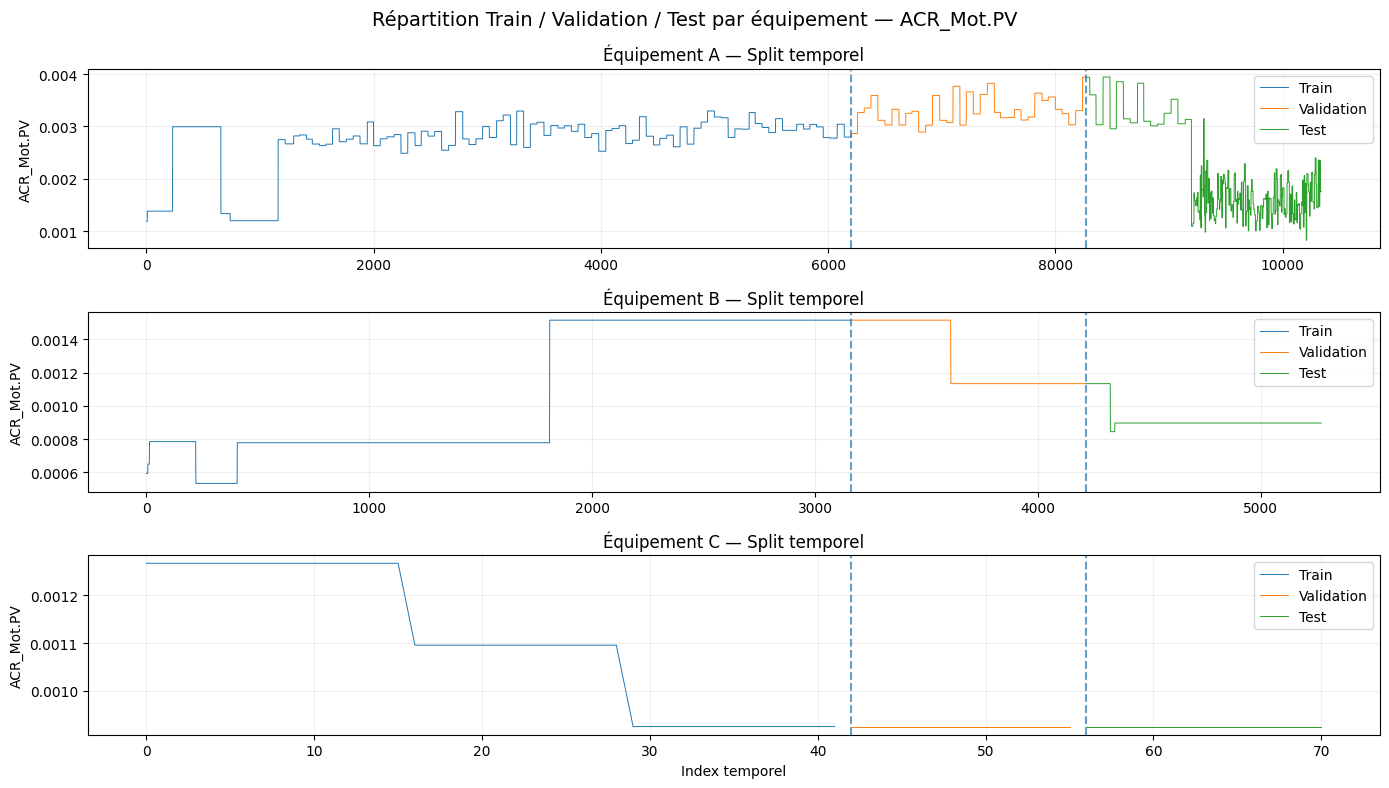

In [4]:
# ============================================================
# 1. Split temporel PAR ÉQUIPEMENT
# ============================================================

TRAIN_FRAC = 0.60
VAL_FRAC   = 0.20
TEST_FRAC  = 0.20

train_list = []
val_list   = []
test_list  = []

for equipment in df_raw["equipment_id"].unique():

    df_eq = (
        df_raw[df_raw["equipment_id"] == equipment]
        .sort_index()
        .reset_index(drop=True)
    )

    N = len(df_eq)

    n_train = int(N * TRAIN_FRAC)
    n_val   = int(N * VAL_FRAC)

    # Train
    train_eq = df_eq.iloc[:n_train].copy()

    # Validation
    val_eq = df_eq.iloc[n_train:n_train+n_val].copy()

    # Test
    test_eq = df_eq.iloc[n_train+n_val:].copy()

    train_list.append(train_eq)
    val_list.append(val_eq)
    test_list.append(test_eq)


# ============================================================
# 2. Reconstruction des DataFrames
# ============================================================

df_train = pd.concat(train_list, ignore_index=True)
df_val   = pd.concat(val_list, ignore_index=True)
df_test  = pd.concat(test_list, ignore_index=True)


# ============================================================
# 3. Vérification
# ============================================================

print("TRAIN")
print(df_train["equipment_id"].value_counts())

print("\nVALIDATION")
print(df_val["equipment_id"].value_counts())

print("\nTEST")
print(df_test["equipment_id"].value_counts())

import matplotlib.pyplot as plt

# ============================================================
# Visualisation du split temporel par équipement
# ============================================================

equipments = sorted(df_raw["equipment_id"].unique())

fig, axes = plt.subplots(
    len(equipments), 1,
    figsize=(14, 8),
    sharex=False
)

if len(equipments) == 1:
    axes = [axes]

for ax, equipment in zip(axes, equipments):

    # Données de cet équipement
    train_eq = df_train[
        df_train["equipment_id"] == equipment
    ][TARGET_SENSOR].reset_index(drop=True)

    val_eq = df_val[
        df_val["equipment_id"] == equipment
    ][TARGET_SENSOR].reset_index(drop=True)

    test_eq = df_test[
        df_test["equipment_id"] == equipment
    ][TARGET_SENSOR].reset_index(drop=True)

    # Indices temporels
    train_idx = range(len(train_eq))

    val_idx = range(
        len(train_eq),
        len(train_eq) + len(val_eq)
    )

    test_idx = range(
        len(train_eq) + len(val_eq),
        len(train_eq) + len(val_eq) + len(test_eq)
    )

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------
    ax.plot(
        train_idx,
        train_eq,
        label="Train",
        lw=0.7
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------
    ax.plot(
        val_idx,
        val_eq,
        label="Validation",
        lw=0.7
    )

    # --------------------------------------------------------
    # Test
    # --------------------------------------------------------
    ax.plot(
        test_idx,
        test_eq,
        label="Test",
        lw=0.7
    )

    # Séparations
    ax.axvline(
        len(train_eq),
        linestyle="--",
        alpha=0.7
    )

    ax.axvline(
        len(train_eq) + len(val_eq),
        linestyle="--",
        alpha=0.7
    )

    ax.set_title(
        f"Équipement {equipment} — Split temporel"
    )

    ax.set_ylabel(TARGET_SENSOR)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")


axes[-1].set_xlabel("Index temporel")

fig.suptitle(
    f"Répartition Train / Validation / Test par équipement — {TARGET_SENSOR}",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [5]:
# Scaling : le scaler est ajusté UNIQUEMENT sur Train (évite le data leakage)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(df_train[AVAILABLE_SENSORS].values)

def scale(dframe):
    return pd.DataFrame(scaler.transform(dframe[AVAILABLE_SENSORS].values), columns=AVAILABLE_SENSORS)

train_s = scale(df_train)
val_s   = scale(df_val)
test_s  = scale(df_test)

target_idx = AVAILABLE_SENSORS.index(TARGET_SENSOR)
obs_idx    = [AVAILABLE_SENSORS.index(c) for c in OTHER_SENSORS]

print("Scaler ajusté sur Train uniquement (moyenne/écart-type) :")
print(pd.DataFrame({"mean": scaler.mean_, "scale": scaler.scale_}, index=AVAILABLE_SENSORS))


Scaler ajusté sur Train uniquement (moyenne/écart-type) :
                    mean      scale
ACR_Mot.PV      0.002144   0.000914
ACR_Mot.SV     13.341657   9.494807
ACR_Mot.TV     30.218471   7.837434
ACR_Pmp.PV      0.002945   0.001260
ACR_Pmp.SV     22.657275  15.147921
ACR_Pmp.TV     31.971461   5.751887
Pres.PV        38.712266  10.644683
Temp.PV        30.833419   6.699289
Barometer    1017.199133   4.556650
Temperature    24.322916   0.895609


In [6]:
corr_with_target = df_train[AVAILABLE_SENSORS].corr()[TARGET_SENSOR].drop(TARGET_SENSOR).sort_values(key=abs, ascending=False)
print("Corrélation (Train) des capteurs disponibles avec la cible, triée par |corr| :")
print(corr_with_target)

SENSOR_CORR_MIN_THRESHOLD = 0.0   # mettre par ex. 0.05 pour exclure les capteurs quasi-non-corrélés
selected_sensors = [c for c in OTHER_SENSORS if abs(corr_with_target.get(c, 1.0)) >= SENSOR_CORR_MIN_THRESHOLD]
print(f"\nCapteurs retenus pour SSI ({len(selected_sensors)}) :", selected_sensors)

ALL_SSI_SENSORS = [TARGET_SENSOR] + [c for c in selected_sensors]  # cible incluse en Train pour identifier C_missing


Corrélation (Train) des capteurs disponibles avec la cible, triée par |corr| :
ACR_Pmp.SV     0.868289
ACR_Pmp.TV     0.862675
Temp.PV        0.804388
ACR_Mot.TV     0.758836
Barometer      0.754261
ACR_Pmp.PV     0.726760
ACR_Mot.SV     0.424982
Pres.PV        0.229944
Temperature   -0.093339
Name: ACR_Mot.PV, dtype: float64

Capteurs retenus pour SSI (9) : ['ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV', 'Pres.PV', 'Temp.PV', 'Barometer', 'Temperature']


## 2. Briques SSI utilisées par les approches hybrides

SSI donne des états cachés à partir des capteurs disponibles. Cette brique est nécessaire pour les essais qui utilisent SSI, SINDy et XGBoost ensemble.


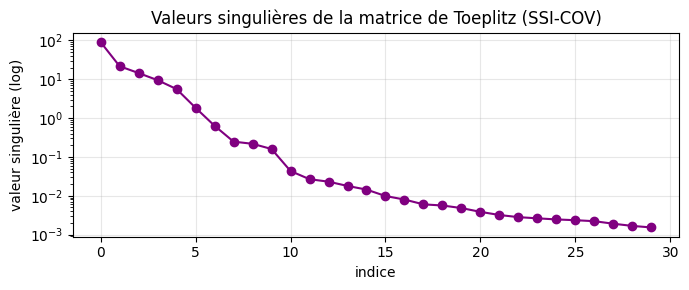

In [7]:
def ssi_cov(Y, s, order):
    '''SSI covariance-driven. Y: (N, m). Retourne A (n,n), C (m,n), valeurs singulières.'''
    N, m = Y.shape
    Yc = Y - Y.mean(axis=0, keepdims=True)
    max_lag = 2 * s
    R = np.zeros((max_lag, m, m))
    for i in range(max_lag):
        R[i] = (Yc[i:].T @ Yc[:N - i]) / (N - i)
    T = np.zeros((s * m, s * m))
    for i in range(s):
        for j in range(s):
            lag = i + j + 1
            T[i*m:(i+1)*m, j*m:(j+1)*m] = R[min(lag, max_lag - 1)]
    U, Sv, Vt = np.linalg.svd(T)
    U1 = U[:, :order]
    S1 = Sv[:order]
    O = U1 @ np.diag(np.sqrt(np.maximum(S1, 1e-12)))
    C = O[:m, :]
    A = np.linalg.pinv(O[:-m, :]) @ O[m:, :]
    return A, C, Sv


def ssi_observability(C, A, s):
    order = A.shape[0]
    blocks = [C]
    Ak = np.eye(order)
    for _ in range(1, s):
        Ak = Ak @ A
        blocks.append(C @ Ak)
    return np.vstack(blocks)


def ssi_estimate_states(Y, C, A, s):
    '''Estime la séquence d'état latent par projection sur la matrice d'observabilité.'''
    N, m = Y.shape
    O = ssi_observability(C, A, s)
    O_pinv = np.linalg.pinv(O)
    n_out = N - s + 1
    X = np.zeros((n_out, A.shape[0]))
    for k in range(n_out):
        X[k] = O_pinv @ Y[k:k+s].reshape(-1)
    return X

Y_train_full = train_s[ALL_SSI_SENSORS].values   # cible incluse en Train (pour connaître C_missing)

# --- Valeurs singulières pour aider au choix de l'ordre ---
_, _, Sv_full = ssi_cov(Y_train_full, SSI_BLOCK_ROWS, max(SSI_ORDER_CANDIDATES))
fig, ax = plt.subplots(figsize=(7,3))
ax.semilogy(Sv_full[:30], "o-", color="purple")
ax.set_xlabel("indice")
ax.set_ylabel("valeur singulière (log)")
ax.set_title("Valeurs singulières de la matrice de Toeplitz (SSI-COV)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
# --- Sélection de l'ordre du modèle sur Validation : erreur de reconstruction one-step-ahead ---
def one_step_ahead_error(A, C, s, Y):
    X = ssi_estimate_states(Y, C, A, s)
    Ypred = X[:-1] @ (C @ A).T   # y_{k+1} approx C A x_k  (à un décalage près de la fenêtre s)
    Ytrue_shift = Y[s: s + Ypred.shape[0]]
    n_cmp = min(len(Ypred), len(Ytrue_shift))
    return np.sqrt(np.mean((Ypred[:n_cmp] - Ytrue_shift[:n_cmp])**2))

val_errors = {}
Y_val_full = val_s[ALL_SSI_SENSORS].values
for order in SSI_ORDER_CANDIDATES:
    try:
        A_o, C_o, _ = ssi_cov(Y_train_full, SSI_BLOCK_ROWS, order)
        err = one_step_ahead_error(A_o, C_o, SSI_BLOCK_ROWS, Y_val_full)
        val_errors[order] = err
    except Exception as e:
        val_errors[order] = np.inf
        print(f"Ordre {order} : échec ({e})")

print("Erreur de reconstruction one-step-ahead (Validation) par ordre :")
for o, e in val_errors.items():
    print(f"  ordre={o:2d}  RMSE_val={e:.4f}")

SSI_ORDER = min(val_errors, key=val_errors.get)
print(f"\n>>> Ordre retenu (minimise l'erreur de Validation) : n = {SSI_ORDER}")

A, C_ssi, Sv = ssi_cov(Y_train_full, SSI_BLOCK_ROWS, SSI_ORDER)
print("\nMatrice A (dynamique discrète latente) :")
print(np.round(A, 4))
print("\nMatrice C (capteurs = fonction de l'état latent), lignes = [cible] + capteurs dispo :")
print(pd.DataFrame(np.round(C_ssi, 3), index=ALL_SSI_SENSORS, columns=[f"x{i+1}" for i in range(SSI_ORDER)]))

C_target_row = C_ssi[0:1, :]                 # ligne correspondant au capteur cible
C_obs_full   = C_ssi[1:, :]                   # lignes correspondant aux capteurs disponibles (ordre = selected_sensors)


Erreur de reconstruction one-step-ahead (Validation) par ordre :
  ordre= 2  RMSE_val=0.4376
  ordre= 3  RMSE_val=0.3711
  ordre= 4  RMSE_val=0.3405
  ordre= 5  RMSE_val=0.2144
  ordre= 6  RMSE_val=0.1815
  ordre= 8  RMSE_val=0.1614

>>> Ordre retenu (minimise l'erreur de Validation) : n = 8

Matrice A (dynamique discrète latente) :
[[ 9.990e-01 -5.000e-04  7.000e-04 -3.000e-04  0.000e+00  6.000e-04
  -1.000e-04  3.000e-04]
 [-9.000e-04  9.988e-01 -3.000e-04  4.000e-04 -2.000e-04 -2.000e-04
  -3.300e-03  1.000e-03]
 [ 1.800e-03  1.400e-03  9.939e-01  4.000e-04 -2.600e-03 -1.700e-03
  -6.400e-03  1.000e-04]
 [ 1.200e-03  1.200e-03 -1.500e-03  9.971e-01  5.000e-04 -1.000e-04
   2.500e-03  1.200e-03]
 [ 9.000e-04  2.000e-04 -1.200e-03  1.600e-03  9.977e-01 -2.600e-03
  -1.500e-03  1.500e-03]
 [ 6.000e-04  8.000e-04 -7.000e-04  3.000e-04 -7.000e-04  9.917e-01
  -4.100e-03  1.900e-03]
 [ 1.800e-03  1.700e-03 -7.500e-03  6.000e-04  1.000e-04 -1.400e-03
   9.812e-01 -2.900e-03]
 [-3.000e-04 -

In [9]:
OBS_SSI_SENSORS = [
    s for s in ALL_SSI_SENSORS
    if s != TARGET_SENSOR
]

print("Capteur cible :", TARGET_SENSOR)
print("Capteurs observés :", OBS_SSI_SENSORS)

Capteur cible : ACR_Mot.PV
Capteurs observés : ['ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV', 'Pres.PV', 'Temp.PV', 'Barometer', 'Temperature']


In [10]:
if TIME_COLUMN is not None:
    _time_xgb = pd.to_datetime(df_train[TIME_COLUMN], errors="coerce", utc=True)
    DT_APPROX = _time_xgb.diff().dt.total_seconds().median()
else:
    DT_APPROX = 1.0
if not np.isfinite(DT_APPROX) or DT_APPROX <= 0:
    DT_APPROX = 1.0
print(f"Pas de temps utilisé : {DT_APPROX:.6f} s")


Pas de temps utilisé : 1.000000 s


## 3. SINDy pour les premières approches hybrides

Avant d'employer SSI + SINDy + XGBoost, SINDy est ajusté sur les états SSI et contrôlé sur la validation. Il sert à produire des caractéristiques dynamiques, pas à donner au modèle la cible cachée.




NORMALISATION DES ÉTATS SSI
Train : (9396, 8)
Validation : (3122, 8)

Moyenne Train :
[ 4.26726910e-15  5.23917507e-16  6.64054214e-18 -5.66218469e-16
  2.61363748e-15 -8.92077670e-16 -2.05393032e-16  3.05512202e-16]

Écart-type Train :
[1. 1. 1. 1. 1. 1. 1. 1.]


COMPARAISON SINDy : DEGRÉ 2 VS DEGRÉ 3


========== DEGRÉ 2 ==========

Degree = 2 | Threshold = 0.001
⚠️ SINDy : 1 états hors domaine. Max = 5.0595
⚠️ SINDy : 1 états hors domaine. Max = 5.3891
⚠️ SINDy : 1 états hors domaine. Max = 5.4556
⚠️ SINDy : 1 états hors domaine. Max = 5.5341
⚠️ SINDy : 1 états hors domaine. Max = 5.5280
⚠️ SINDy : 1 états hors domaine. Max = 5.6724
⚠️ SINDy : 1 états hors domaine. Max = 5.7523
⚠️ SINDy : 1 états hors domaine. Max = 6.1729
⚠️ SINDy : 1 états hors domaine. Max = 6.2624
⚠️ SINDy : 1 états hors domaine. Max = 6.3644
⚠️ SINDy : 1 états hors domaine. Max = 6.3522
⚠️ SINDy : 1 états hors domaine. Max = 6.5419
⚠️ SINDy : 1 états hors domaine. Max = 6.6506
⚠️ SINDy : 1 états hors domaine.

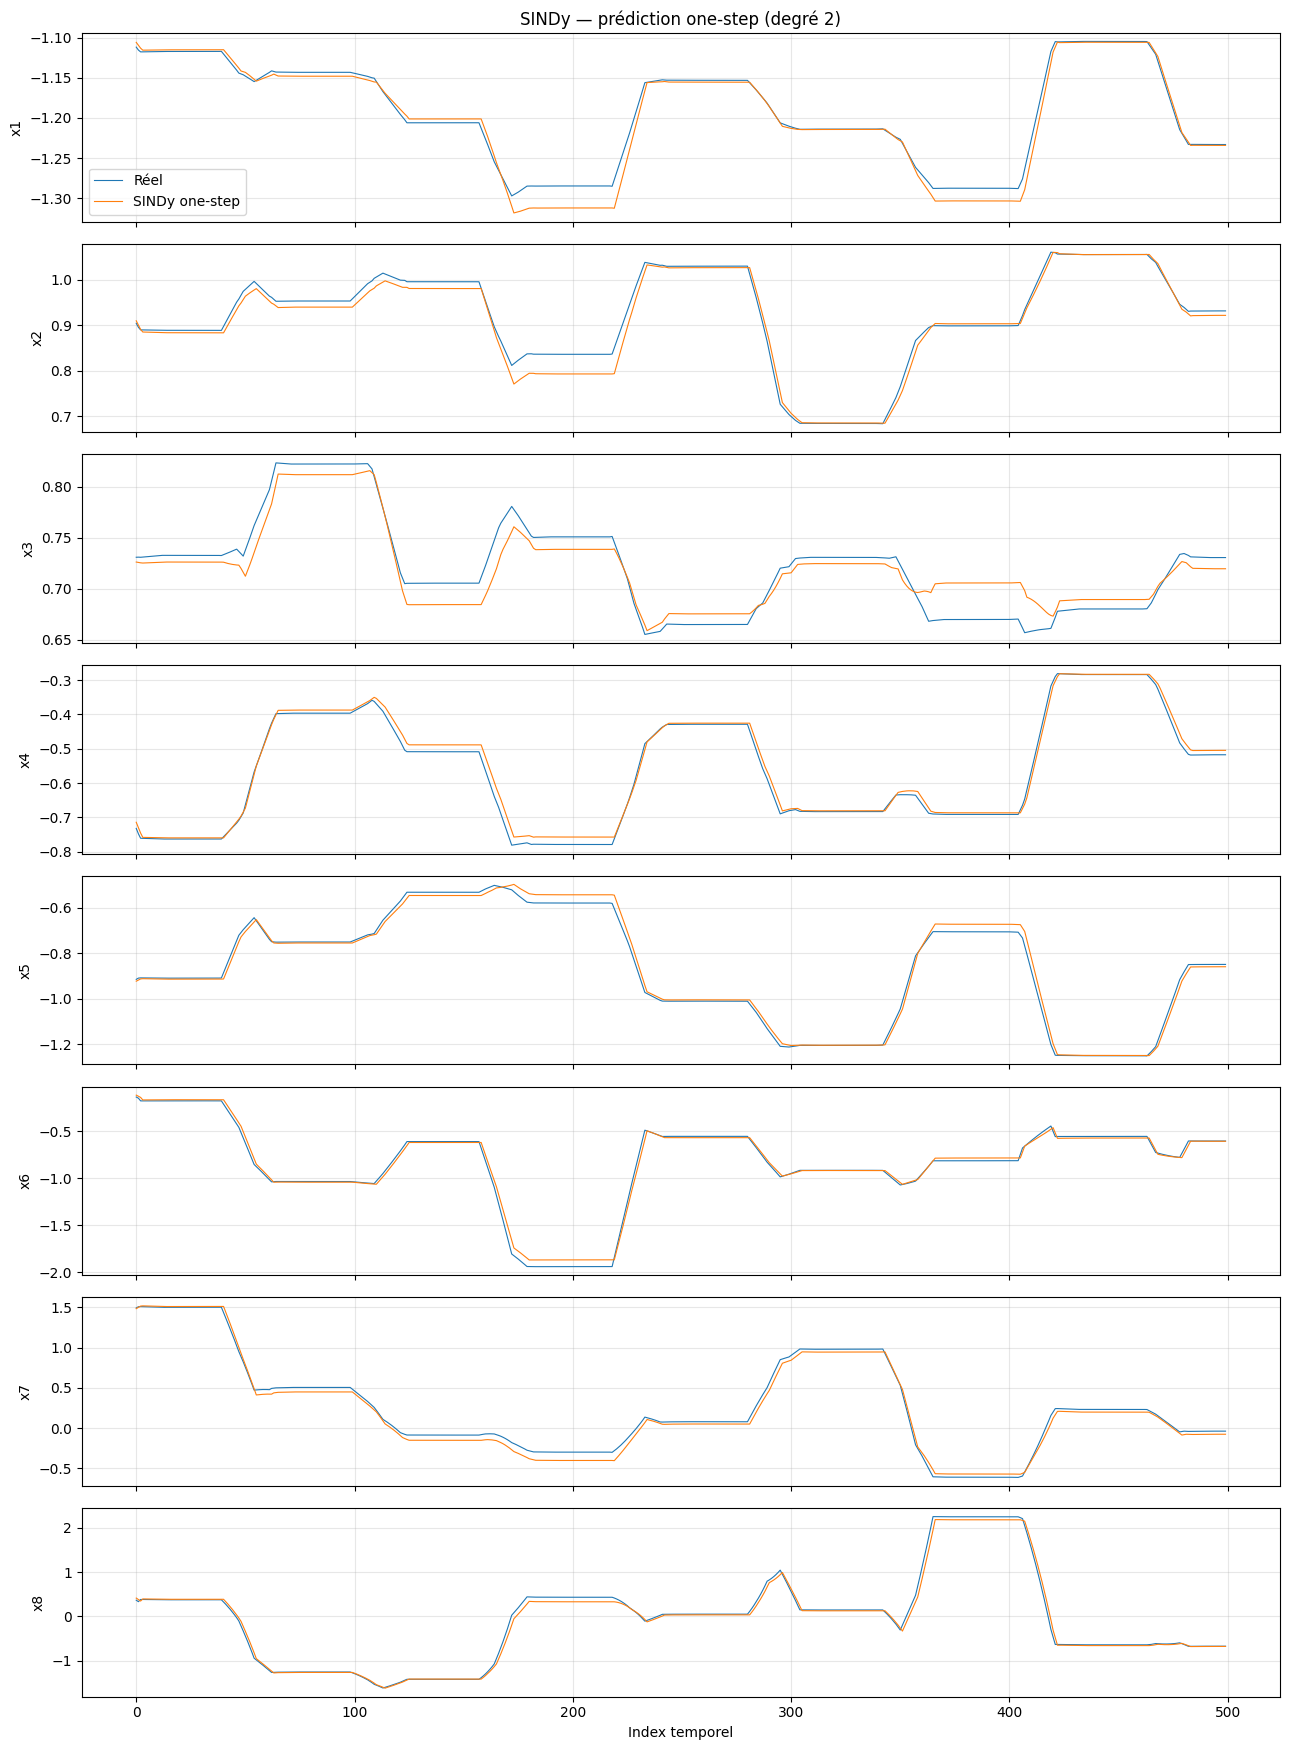

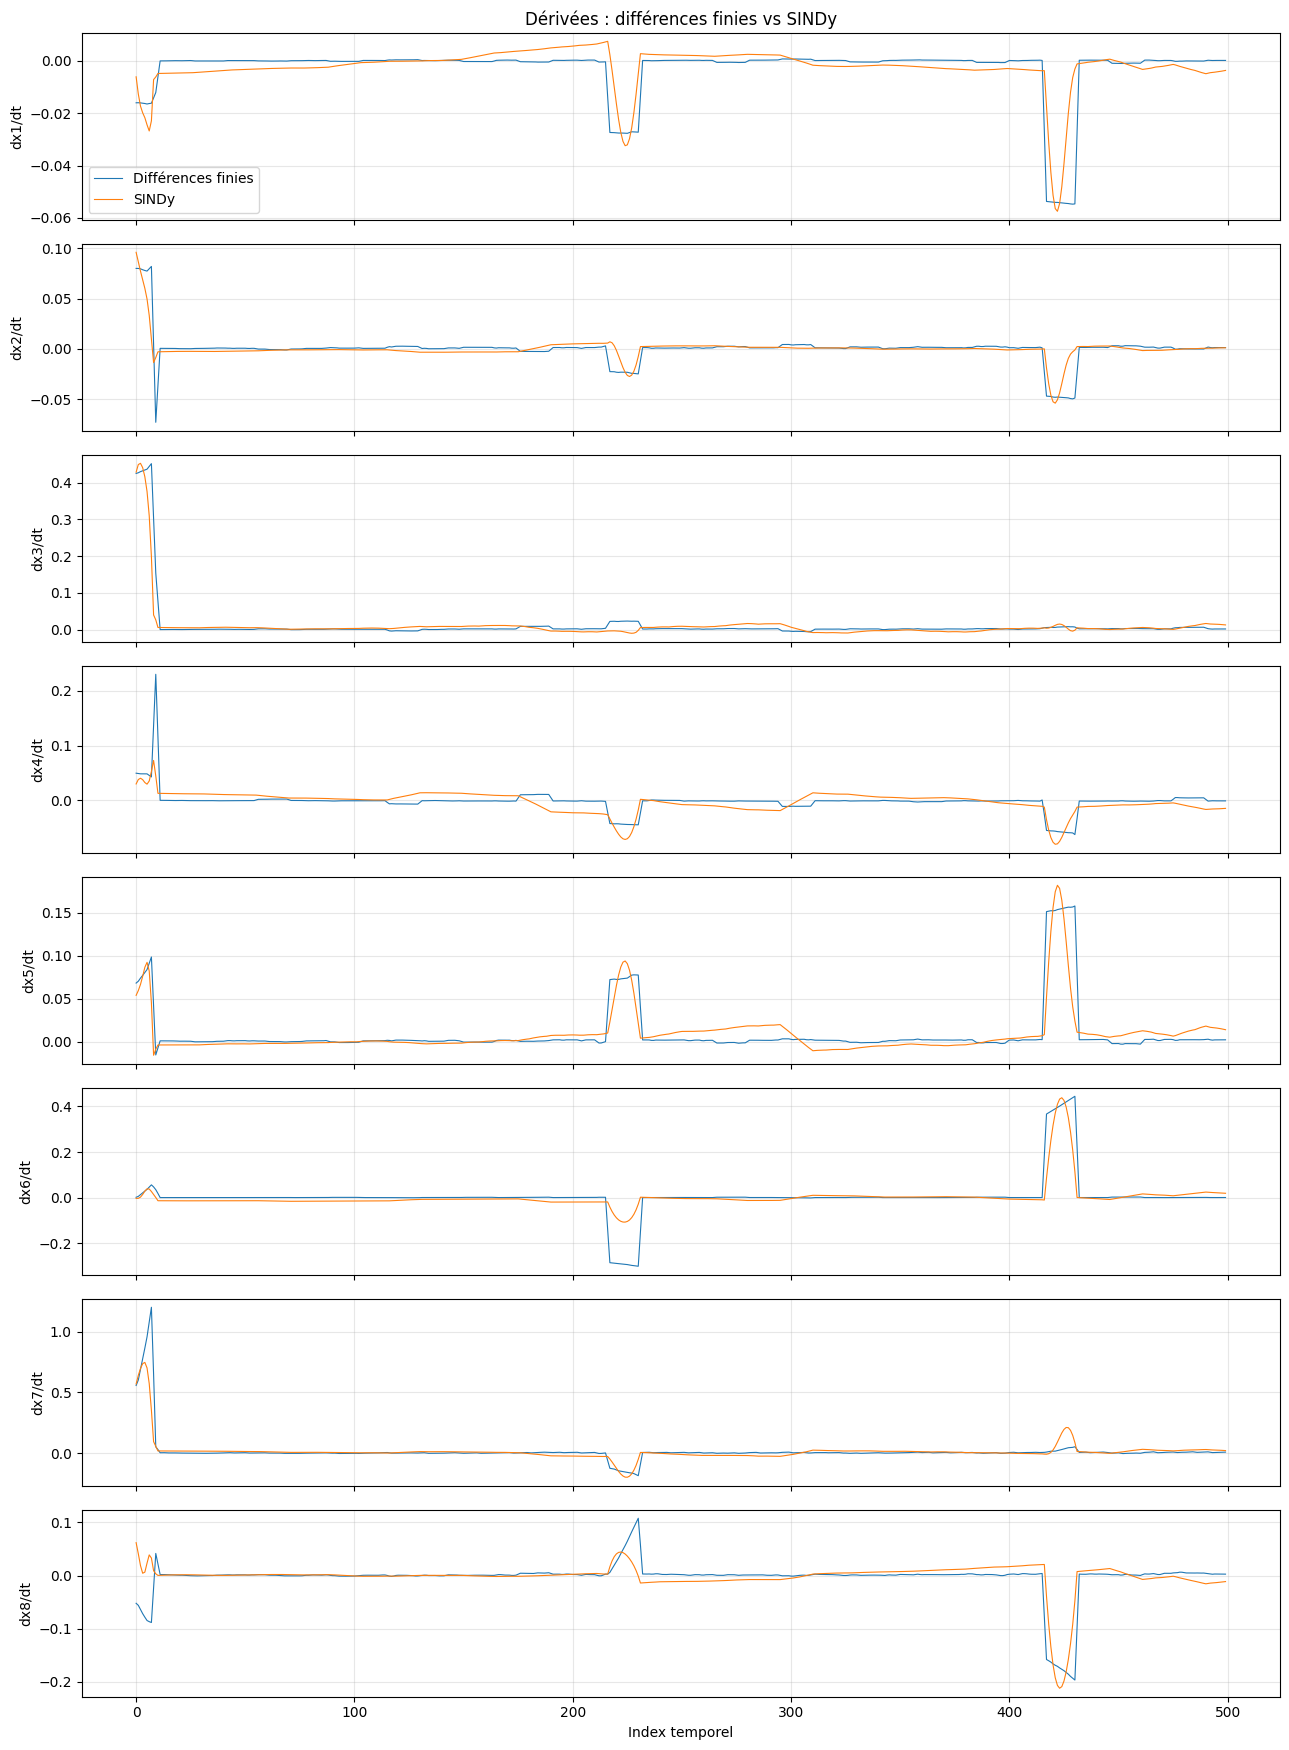



COMPARAISON DES DEGRÉS
 degree  threshold  one_step_RMSE  active_terms  max_abs_coef  stable
      2       0.05       0.023009             0           0.0    True
      3       0.05       0.023009             0           0.0    True


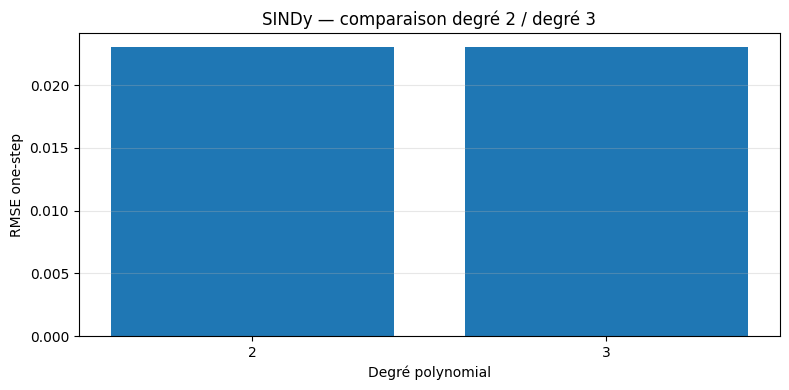



TEST DE STABILITÉ FINAL
⚠️ SINDy : 1 états hors domaine. Max = 5.0595
⚠️ SINDy : 1 états hors domaine. Max = 5.3891
⚠️ SINDy : 1 états hors domaine. Max = 5.4556
⚠️ SINDy : 1 états hors domaine. Max = 5.5341
⚠️ SINDy : 1 états hors domaine. Max = 5.5280
⚠️ SINDy : 1 états hors domaine. Max = 5.6724
⚠️ SINDy : 1 états hors domaine. Max = 5.7523
⚠️ SINDy : 1 états hors domaine. Max = 6.1729
⚠️ SINDy : 1 états hors domaine. Max = 6.2624
⚠️ SINDy : 1 états hors domaine. Max = 6.3644
⚠️ SINDy : 1 états hors domaine. Max = 6.3522
⚠️ SINDy : 1 états hors domaine. Max = 6.5419
⚠️ SINDy : 1 états hors domaine. Max = 6.6506
⚠️ SINDy : 1 états hors domaine. Max = 7.2382
⚠️ SINDy : 1 états hors domaine. Max = 7.3723
⚠️ SINDy : 1 états hors domaine. Max = 7.5194
⚠️ SINDy : 1 états hors domaine. Max = 7.4949
⚠️ SINDy : 1 états hors domaine. Max = 6.5133
⚠️ SINDy : 1 états hors domaine. Max = 6.6039
⚠️ SINDy : 1 états hors domaine. Max = 7.0850
⚠️ SINDy : 1 états hors domaine. Max = 7.1898
⚠️ SINDy

In [11]:
# ============================================================
# SINDy — VERSION AMÉLIORÉE
# ============================================================
#
# Train :
#   Identification du modèle
#
# Validation :
#   Choix du degré + threshold
#   One-step prediction
#   Test de stabilité
#
# Test :
#   NON utilisé ici
#
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import combinations_with_replacement
from sklearn.preprocessing import StandardScaler
from scipy.integrate import solve_ivp


# ============================================================
# 1. PARAMÈTRES SINDy
# ============================================================

# Degrés à comparer
SINDY_POLY_DEGREES = [2, 3]

# Degré par défaut
SINDY_POLY_DEGREE = 3

# Régularisation Ridge
SINDY_ALPHA = 0.05

# Thresholds testés
SINDY_THRESHOLD_CANDIDATES = [
    0.001,
    0.005,
    0.01,
    0.02,
    0.05,
    0.1,
    0.2
]

# Fonctions trigonométriques
SINDY_INCLUDE_TRIG = True


# ============================================================
# 2. PARAMÈTRES DE STABILITÉ
# ============================================================

# Limite des états normalisés
SINDY_STATE_LIMIT = 5.0

# Nombre de points utilisés pour le test
# de simulation libre courte
SINDY_STABILITY_STEPS = 300


# ============================================================
# 3. NORMALISATION DES ÉTATS SSI
# ============================================================
#
# IMPORTANT :
# Le scaler est entraîné UNIQUEMENT sur Train.
#
# X_train_hat et X_val_hat restent inchangés.
# ============================================================

SINDY_SCALER = StandardScaler()

X_train_hat = ssi_estimate_states(Y_train_full, C_ssi, A, SSI_BLOCK_ROWS)
X_val_hat = ssi_estimate_states(Y_val_full, C_ssi, A, SSI_BLOCK_ROWS)

# Fit + transform TRAIN
X_train_hat_sindy = (
    SINDY_SCALER.fit_transform(
        X_train_hat
    )
)


# Transform VALIDATION
X_val_hat_sindy = (
    SINDY_SCALER.transform(
        X_val_hat
    )
)


print("\n")
print("=" * 60)
print("NORMALISATION DES ÉTATS SSI")
print("=" * 60)

print(
    "Train :",
    X_train_hat_sindy.shape
)

print(
    "Validation :",
    X_val_hat_sindy.shape
)

print("\nMoyenne Train :")

print(
    np.mean(
        X_train_hat_sindy,
        axis=0
    )
)

print("\nÉcart-type Train :")

print(
    np.std(
        X_train_hat_sindy,
        axis=0
    )
)


# ============================================================
# 4. BIBLIOTHÈQUE SINDy
# ============================================================

def build_library(
    X,
    degree=3,
    feature_names=None,
    include_trig=True
):

    """
    Bibliothèque :

    1
    x1, x2, ...
    x1², x1x2, ...
    x1³, x1²x2, ...
    sin(x1), cos(x1), ...
    """

    X = np.asarray(
        X,
        dtype=float
    )


    if X.ndim == 1:

        X = X.reshape(
            -1,
            1
        )


    n_samples, n_features = (
        X.shape
    )


    # --------------------------------------------------------
    # Noms des variables
    # --------------------------------------------------------

    if feature_names is None:

        feature_names = [
            f"x{i+1}"
            for i in range(
                n_features
            )
        ]


    cols = []
    names = []


    # --------------------------------------------------------
    # Constante
    # --------------------------------------------------------

    cols.append(
        np.ones(
            n_samples
        )
    )

    names.append(
        "1"
    )


    # --------------------------------------------------------
    # Termes polynomiaux
    # --------------------------------------------------------

    for deg in range(
        1,
        degree + 1
    ):

        for comb in combinations_with_replacement(
            range(n_features),
            deg
        ):

            term = np.ones(
                n_samples
            )

            name_parts = []


            for i in comb:

                term *= X[:, i]

                name_parts.append(
                    feature_names[i]
                )


            cols.append(
                term
            )


            if deg == 1:

                name = name_parts[0]

            else:

                name = " ".join(
                    name_parts
                )


            names.append(
                name
            )


    # --------------------------------------------------------
    # Sin / Cos
    # --------------------------------------------------------

    if include_trig:

        for i in range(
            n_features
        ):

            cols.append(
                np.sin(
                    X[:, i]
                )
            )

            names.append(
                f"sin({feature_names[i]})"
            )


            cols.append(
                np.cos(
                    X[:, i]
                )
            )

            names.append(
                f"cos({feature_names[i]})"
            )


    Theta = np.column_stack(
        cols
    )


    return Theta, names


# ============================================================
# 5. STLSQ
# ============================================================

def stlsq(
    Theta,
    Xdot,
    threshold,
    alpha,
    max_iter=20
):

    """
    Sequential Thresholded Least Squares
    avec régularisation Ridge.
    """

    Theta = np.asarray(
        Theta,
        dtype=float
    )

    Xdot = np.asarray(
        Xdot,
        dtype=float
    )


    n_library = (
        Theta.shape[1]
    )

    n_states = (
        Xdot.shape[1]
    )


    # --------------------------------------------------------
    # Régression Ridge initiale
    # --------------------------------------------------------

    A = (
        Theta.T @ Theta
        + alpha
        * np.eye(
            n_library
        )
    )


    B = (
        Theta.T @ Xdot
    )


    Xi = np.linalg.solve(
        A,
        B
    )


    # --------------------------------------------------------
    # STLSQ
    # --------------------------------------------------------

    for k in range(
        n_states
    ):

        active = np.ones(
            n_library,
            dtype=bool
        )


        for _ in range(
            max_iter
        ):

            if active.sum() == 0:

                Xi[:, k] = 0.0

                break


            small = (
                np.abs(
                    Xi[
                        active,
                        k
                    ]
                )
                < threshold
            )


            if not small.any():

                break


            active_indices = (
                np.where(active)[0]
            )


            active[
                active_indices[
                    small
                ]
            ] = False


            if active.sum() == 0:

                Xi[:, k] = 0.0

                break


            Theta_active = (
                Theta[:, active]
            )


            A_active = (
                Theta_active.T
                @ Theta_active
                + alpha
                * np.eye(
                    active.sum()
                )
            )


            B_active = (
                Theta_active.T
                @ Xdot[:, k]
            )


            Xi[:, k] = 0.0


            Xi[
                active,
                k
            ] = np.linalg.solve(
                A_active,
                B_active
            )


    return Xi


# ============================================================
# 6. CLASSE SimpleSINDy
# ============================================================

class SimpleSINDy:

    def __init__(
        self,
        degree=3,
        threshold=0.05,
        alpha=0.05,
        include_trig=True
    ):

        self.degree = degree

        self.threshold = (
            threshold
        )

        self.alpha = alpha

        self.include_trig = (
            include_trig
        )

        self.feature_names = None

        self.lib_names = None

        self.Xi = None

        self.n_states = None


    # ========================================================
    # FIT
    # ========================================================

    def fit(
        self,
        X,
        t,
        feature_names=None
    ):

        X = np.asarray(
            X,
            dtype=float
        )

        t = np.asarray(
            t,
            dtype=float
        )


        if X.ndim == 1:

            X = X.reshape(
                -1,
                1
            )


        self.n_states = (
            X.shape[1]
        )


        if feature_names is None:

            feature_names = [
                f"x{i+1}"
                for i in range(
                    self.n_states
                )
            ]


        self.feature_names = (
            feature_names
        )


        # ----------------------------------------------------
        # Dérivée par différences finies
        # ----------------------------------------------------

        Xdot = np.gradient(
            X,
            t,
            axis=0
        )


        # ----------------------------------------------------
        # Bibliothèque
        # ----------------------------------------------------

        Theta, self.lib_names = (
            build_library(
                X,
                degree=self.degree,
                feature_names=(
                    self.feature_names
                ),
                include_trig=(
                    self.include_trig
                )
            )
        )


        # ----------------------------------------------------
        # Identification
        # ----------------------------------------------------

        self.Xi = stlsq(
            Theta,
            Xdot,
            threshold=self.threshold,
            alpha=self.alpha
        )


        return self


    # ========================================================
    # PREDICT
    # ========================================================

    def predict(
        self,
        X
    ):

        X = np.asarray(
            X,
            dtype=float
        )

        one_sample = False

        if X.ndim == 1:

            X = X.reshape(
                1,
                -1
            )

            one_sample = True

        # ========================================================
        # 1. Vérification des états
        # ========================================================

        if not np.all(
            np.isfinite(X)
        ):
            raise RuntimeError(
                "SINDy reçoit des états non finis."
            )

        # --------------------------------------------------------
        # Détection hors domaine
        # --------------------------------------------------------

        ood_mask = np.any(
            np.abs(X) > SINDY_STATE_LIMIT,
            axis=1
        )

        if np.any(ood_mask):

            max_state = np.max(
                np.abs(X[ood_mask])
            )

            print(
                f"⚠️ SINDy : "
                f"{ood_mask.sum()} états hors domaine. "
                f"Max = {max_state:.4f}"
            )

        # ========================================================
        # 2. Construction bibliothèque
        # ========================================================

        Theta, _ = build_library(
            X,
            degree=self.degree,
            feature_names=self.feature_names,
            include_trig=self.include_trig
        )

        # ========================================================
        # 3. Dynamique SINDy
        # ========================================================

        Xdot = (
            Theta @ self.Xi
        )

        # ========================================================
        # 4. Vérification
        # ========================================================

        if not np.all(
            np.isfinite(Xdot)
        ):
            raise RuntimeError(
                "SINDy produit une dérivée non finie."
            )

        # --------------------------------------------------------
        # Diagnostic
        # --------------------------------------------------------

        max_xdot = np.max(
            np.abs(Xdot)
        )

        if max_xdot > 10:

            print(
                f"⚠️ Dérivée SINDy élevée : "
                f"max |dx/dt| = {max_xdot:.4f}"
            )

        if one_sample:

            return Xdot[0]

        return Xdot


    # ========================================================
    # ONE-STEP
    # ========================================================

    def predict_one_step(
        self,
        X,
        dt
    ):

        X = np.asarray(
            X,
            dtype=float
        )


        Xdot = self.predict(
            X
        )


        X_next = (
            X
            + dt * Xdot
        )


        # ----------------------------------------------------
        # Protection
        # ----------------------------------------------------

        X_next = np.clip(
            X_next,
            -SINDY_STATE_LIMIT,
            SINDY_STATE_LIMIT
        )


        return X_next


    # ========================================================
    # SIMULATION LIBRE
    # ========================================================

    def simulate(
        self,
        x0,
        t
    ):

        x0 = np.asarray(
            x0,
            dtype=float
        )


        t = np.asarray(
            t,
            dtype=float
        )


        x0 = np.clip(
            x0,
            -SINDY_STATE_LIMIT,
            SINDY_STATE_LIMIT
        )


        def rhs(
            tt,
            x
        ):

            return self.predict(
                x
            )


        sol = solve_ivp(
            rhs,
            (
                t[0],
                t[-1]
            ),
            x0,
            t_eval=t,
            method="RK45",
            rtol=1e-5,
            atol=1e-7,
            max_step=DT_APPROX
        )


        if not sol.success:

            raise RuntimeError(
                "Échec de la simulation SINDy."
            )


        X_sim = (
            sol.y.T
        )


        # ----------------------------------------------------
        # Vérification stabilité
        # ----------------------------------------------------

        if not np.all(
            np.isfinite(
                X_sim
            )
        ):

            raise RuntimeError(
                "Divergence numérique de SINDy."
            )


        if np.max(
            np.abs(
                X_sim
            )
        ) > SINDY_STATE_LIMIT:

            raise RuntimeError(
                "Divergence : "
                "états trop grands."
            )


        return X_sim


    # ========================================================
    # STATISTIQUES COEFFICIENTS
    # ========================================================

    def coefficient_statistics(
        self
    ):

        abs_Xi = np.abs(
            self.Xi
        )


        active = (
            abs_Xi > 1e-10
        )


        if active.any():

            active_values = (
                abs_Xi[active]
            )

            mean_abs = (
                np.mean(
                    active_values
                )
            )

            median_abs = (
                np.median(
                    active_values
                )
            )

        else:

            mean_abs = 0.0

            median_abs = 0.0


        return {

            "active_terms":
                int(
                    active.sum()
                ),

            "max_abs_coef":
                float(
                    abs_Xi.max()
                ),

            "mean_abs_coef":
                float(
                    mean_abs
                ),

            "median_abs_coef":
                float(
                    median_abs
                )
        }


    # ========================================================
    # ÉQUATIONS
    # ========================================================

    def print_equations(
        self
    ):

        for k in range(
            self.n_states
        ):

            terms = []


            for coef, name in zip(
                self.Xi[:, k],
                self.lib_names
            ):

                if abs(coef) > 1e-10:

                    terms.append(
                        f"{coef:+.4f} {name}"
                    )


            equation = (
                " ".join(
                    terms
                )
                if terms
                else "0"
            )


            print(
                f"(x{k+1})' = "
                f"{equation}"
            )


# ============================================================
# 7. FIT SINDy
# ============================================================

def fit_sindy(
    X,
    dt,
    threshold,
    degree=None
):

    X = np.asarray(
        X,
        dtype=float
    )


    if degree is None:

        degree = (
            SINDY_POLY_DEGREE
        )


    # Temps
    t = (
        np.arange(
            len(X)
        )
        * dt
    )


    model = SimpleSINDy(
        degree=degree,
        threshold=threshold,
        alpha=SINDY_ALPHA,
        include_trig=SINDY_INCLUDE_TRIG
    )


    model.fit(
        X,
        t=t,
        feature_names=[
            f"x{i+1}"
            for i in range(
                X.shape[1]
            )
        ]
    )


    return model


# ============================================================
# 8. SCORE ONE-STEP VALIDATION
# ============================================================

def sindy_val_score(
    model,
    X_val,
    dt
):

    """
    Prédiction :

        X(t) -> X(t + dt)

    Pas de simulation libre pour choisir
    le threshold.
    """

    try:

        X_val = np.asarray(
            X_val,
            dtype=float
        )


        # ----------------------------------------------------
        # État actuel
        # ----------------------------------------------------

        X_current = (
            X_val[:-1]
        )


        # ----------------------------------------------------
        # État réel suivant
        # ----------------------------------------------------

        X_true_next = (
            X_val[1:]
        )


        # ----------------------------------------------------
        # Prédiction
        # ----------------------------------------------------

        X_pred_next = (
            model.predict_one_step(
                X_current,
                dt
            )
        )


        # ----------------------------------------------------
        # Vérification
        # ----------------------------------------------------

        if not np.all(
            np.isfinite(
                X_pred_next
            )
        ):

            return np.inf


        # ----------------------------------------------------
        # RMSE
        # ----------------------------------------------------

        rmse = np.sqrt(
            np.mean(
                (
                    X_pred_next
                    - X_true_next
                ) ** 2
            )
        )


        return float(
            rmse
        )


    except Exception as e:

        print(
            "Erreur one-step :",
            e
        )

        return np.inf


# ============================================================
# 9. TEST DE STABILITÉ
# ============================================================

def sindy_stability_test(
    model,
    X_val,
    dt,
    n_steps=300
):

    """
    Simulation libre courte uniquement
    pour vérifier la stabilité.
    """

    try:

        n_steps = min(
            n_steps,
            len(X_val)
        )


        t_sim = (
            np.arange(
                n_steps
            )
            * dt
        )


        X_sim = model.simulate(
            X_val[0],
            t_sim
        )


        max_abs_state = np.max(
            np.abs(
                X_sim
            )
        )


        stable = (
            max_abs_state
            < SINDY_STATE_LIMIT
        )


        return {

            "stable":
                bool(stable),

            "max_abs_state":
                float(
                    max_abs_state
                ),

            "simulation":
                X_sim

        }


    except Exception as e:

        return {

            "stable":
                False,

            "max_abs_state":
                np.inf,

            "simulation":
                None
        }


# ============================================================
# 10. COMPARAISON DEGRÉ 2 / DEGRÉ 3
# ============================================================

print("\n")
print("=" * 60)
print("COMPARAISON SINDy : DEGRÉ 2 VS DEGRÉ 3")
print("=" * 60)


sindy_results = {}

sindy_models = {}


for degree in (
    SINDY_POLY_DEGREES
):

    print("\n")
    print(
        f"========== DEGRÉ {degree} =========="
    )


    for threshold in (
        SINDY_THRESHOLD_CANDIDATES
    ):

        print(
            f"\nDegree = {degree} | "
            f"Threshold = {threshold}"
        )


        # ----------------------------------------------------
        # FIT TRAIN
        # ----------------------------------------------------

        model = fit_sindy(
            X_train_hat_sindy,
            DT_APPROX,
            threshold,
            degree=degree
        )


        # ----------------------------------------------------
        # ONE-STEP VALIDATION
        # ----------------------------------------------------

        score = sindy_val_score(
            model,
            X_val_hat_sindy,
            DT_APPROX
        )


        # ----------------------------------------------------
        # STABILITÉ
        # ----------------------------------------------------

        stability = (
            sindy_stability_test(
                model,
                X_val_hat_sindy,
                DT_APPROX,
                n_steps=(
                    SINDY_STABILITY_STEPS
                )
            )
        )


        # ----------------------------------------------------
        # COEFFICIENTS
        # ----------------------------------------------------

        coef_stats = (
            model.coefficient_statistics()
        )


        # ----------------------------------------------------
        # Sauvegarde
        # ----------------------------------------------------

        sindy_results[
            (
                degree,
                threshold
            )
        ] = {

            "one_step_RMSE":
                score,

            "stable":
                stability[
                    "stable"
                ],

            "max_abs_state":
                stability[
                    "max_abs_state"
                ],

            "active_terms":
                coef_stats[
                    "active_terms"
                ],

            "max_abs_coef":
                coef_stats[
                    "max_abs_coef"
                ],

            "mean_abs_coef":
                coef_stats[
                    "mean_abs_coef"
                ],

            "median_abs_coef":
                coef_stats[
                    "median_abs_coef"
                ]
        }


        sindy_models[
            (
                degree,
                threshold
            )
        ] = model


        print(
            f"One-step RMSE = "
            f"{score:.6f}"
        )

        print(
            f"Termes actifs = "
            f"{coef_stats['active_terms']}"
        )

        print(
            f"Max |coef| = "
            f"{coef_stats['max_abs_coef']:.6f}"
        )

        print(
            f"Max |état| = "
            f"{stability['max_abs_state']:.6f}"
        )

        print(
            f"Stable = "
            f"{stability['stable']}"
        )


# ============================================================
# 11. TABLEAU DES RÉSULTATS
# ============================================================

sindy_results_df = (
    pd.DataFrame(
        [
            {
                "degree":
                    key[0],

                "threshold":
                    key[1],

                **value
            }

            for key, value
            in sindy_results.items()
        ]
    )
)


print("\n")
print("=" * 60)
print("RÉSULTATS SINDy")
print("=" * 60)


print(
    sindy_results_df
    .sort_values(
        "one_step_RMSE"
    )
    .to_string(
        index=False
    )
)


# ============================================================
# 12. MEILLEUR MODÈLE GLOBAL
# ============================================================

# ------------------------------------------------------------
# On privilégie les modèles stables
# ------------------------------------------------------------

stable_results = (
    sindy_results_df[
        sindy_results_df[
            "stable"
        ]
    ]
)


if len(
    stable_results
) > 0:

    best_sindy_row = (
        stable_results
        .sort_values(
            "one_step_RMSE"
        )
        .iloc[0]
    )

else:

    print(
        "\n⚠️ Aucun modèle stable."
    )

    best_sindy_row = (
        sindy_results_df
        .sort_values(
            "one_step_RMSE"
        )
        .iloc[0]
    )


# ------------------------------------------------------------
# Paramètres retenus
# ------------------------------------------------------------

SINDY_POLY_DEGREE = int(
    best_sindy_row[
        "degree"
    ]
)


SINDY_THRESHOLD = float(
    best_sindy_row[
        "threshold"
    ]
)


# ------------------------------------------------------------
# Modèle final
# ------------------------------------------------------------

sindy_model = sindy_models[
    (
        SINDY_POLY_DEGREE,
        0.001
    )
]


print("\n")
print("=" * 60)
print("MEILLEUR MODÈLE SINDy")
print("=" * 60)


print(
    f"Degré : "
    f"{SINDY_POLY_DEGREE}"
)


print(
    f"Threshold : "
    f"{SINDY_THRESHOLD}"
)


print(
    f"One-step RMSE : "
    f"{best_sindy_row['one_step_RMSE']:.6f}"
)


print(
    f"Termes actifs : "
    f"{int(best_sindy_row['active_terms'])}"
)


print(
    f"Max |coefficient| : "
    f"{best_sindy_row['max_abs_coef']:.6f}"
)


print(
    f"Stable : "
    f"{best_sindy_row['stable']}"
)


# ============================================================
# 13. ÉQUATIONS FINALES
# ============================================================

print("\n")
print("=" * 60)
print("ÉQUATIONS FINALES IDENTIFIÉES")
print("=" * 60)


sindy_model.print_equations()


# ============================================================
# 14. ANALYSE DES COEFFICIENTS
# ============================================================

print("\n")
print("=" * 60)
print("ANALYSE DES COEFFICIENTS")
print("=" * 60)


max_coef = np.max(
    np.abs(
        sindy_model.Xi
    )
)


print(
    f"Max |coefficient| = "
    f"{max_coef:.6f}"
)


if max_coef > 100:

    print(
        "⚠️ Coefficients très grands."
    )

elif max_coef > 10:

    print(
        "⚠️ Coefficients relativement grands."
    )

else:

    print(
        "✓ Coefficients raisonnables."
    )


# ------------------------------------------------------------
# Top coefficients
# ------------------------------------------------------------

coef_values = []


for i in range(
    sindy_model.Xi.shape[0]
):

    for j in range(
        sindy_model.Xi.shape[1]
    ):

        coef_values.append(
            (
                abs(
                    sindy_model.Xi[
                        i,
                        j
                    ]
                ),

                sindy_model.Xi[
                    i,
                    j
                ],

                j,

                sindy_model.lib_names[
                    i
                ]
            )
        )


coef_values.sort(
    reverse=True,
    key=lambda x: x[0]
)


print("\nTop 15 coefficients :")


for (
    abs_value,
    value,
    state,
    name
) in coef_values[:15]:

    print(
        f"x{state+1} : "
        f"{value:+.6f} × {name}"
    )


# ============================================================
# 15. ONE-STEP FINAL SUR VALIDATION
# ============================================================

X_current = (
    X_val_hat_sindy[:-1]
)


X_true_next = (
    X_val_hat_sindy[1:]
)


X_pred_next = (
    sindy_model.predict_one_step(
        X_current,
        DT_APPROX
    )
)


# ------------------------------------------------------------
# RMSE global
# ------------------------------------------------------------

one_step_rmse = np.sqrt(
    np.mean(
        (
            X_pred_next
            - X_true_next
        ) ** 2
    )
)


print("\n")
print("=" * 60)
print("ONE-STEP VALIDATION")
print("=" * 60)


print(
    f"RMSE global = "
    f"{one_step_rmse:.6f}"
)


# ------------------------------------------------------------
# RMSE par état
# ------------------------------------------------------------

one_step_rmse_states = np.sqrt(
    np.mean(
        (
            X_pred_next
            - X_true_next
        ) ** 2,
        axis=0
    )
)


for i, rmse in enumerate(
    one_step_rmse_states
):

    print(
        f"x{i+1} : "
        f"RMSE = {rmse:.6f}"
    )


# ============================================================
# 16. COMPARAISON DES DÉRIVÉES
# ============================================================

# ------------------------------------------------------------
# Différences finies sur TRAIN
# ------------------------------------------------------------

Xdot_fd = np.gradient(
    X_train_hat_sindy,
    DT_APPROX,
    axis=0
)


# ------------------------------------------------------------
# Dérivée SINDy
# ------------------------------------------------------------

Xdot_sindy = (
    sindy_model.predict(
        X_train_hat_sindy
    )
)


# ------------------------------------------------------------
# RMSE
# ------------------------------------------------------------

deriv_rmse = np.sqrt(
    np.mean(
        (
            Xdot_fd
            - Xdot_sindy
        ) ** 2,
        axis=0
    )
)


print("\n")
print("=" * 60)
print("RMSE DES DÉRIVÉES")
print("=" * 60)


for i, e in enumerate(
    deriv_rmse
):

    print(
        f"dx{i+1}/dt : "
        f"RMSE = {e:.6f}"
    )


# ============================================================
# 17. PLOT ONE-STEP
# ============================================================

n_plot = min(
    500,
    len(X_pred_next)
)


SSI_ORDER = (
    X_train_hat.shape[1]
)


fig, axes = plt.subplots(
    SSI_ORDER,
    1,
    figsize=(
        13,
        2.2 * SSI_ORDER
    ),
    sharex=True
)


if SSI_ORDER == 1:

    axes = [axes]


for i, ax in enumerate(
    axes
):

    ax.plot(
        X_true_next[
            :n_plot,
            i
        ],
        label="Réel",
        lw=0.8
    )


    ax.plot(
        X_pred_next[
            :n_plot,
            i
        ],
        label="SINDy one-step",
        lw=0.8
    )


    ax.set_ylabel(
        f"x{i+1}"
    )


    ax.grid(
        alpha=0.3
    )


axes[0].legend()


axes[0].set_title(
    "SINDy — prédiction one-step "
    f"(degré {SINDY_POLY_DEGREE})"
)


axes[-1].set_xlabel(
    "Index temporel"
)


plt.tight_layout()
plt.show()


# ============================================================
# 18. PLOT DES DÉRIVÉES
# ============================================================

n_plot = min(
    500,
    len(Xdot_fd)
)


fig, axes = plt.subplots(
    SSI_ORDER,
    1,
    figsize=(
        13,
        2.2 * SSI_ORDER
    ),
    sharex=True
)


if SSI_ORDER == 1:

    axes = [axes]


for i, ax in enumerate(
    axes
):

    ax.plot(
        Xdot_fd[
            :n_plot,
            i
        ],
        label="Différences finies",
        lw=0.8
    )


    ax.plot(
        Xdot_sindy[
            :n_plot,
            i
        ],
        label="SINDy",
        lw=0.8
    )


    ax.set_ylabel(
        f"dx{i+1}/dt"
    )


    ax.grid(
        alpha=0.3
    )


axes[0].legend()


axes[0].set_title(
    "Dérivées : différences finies "
    "vs SINDy"
)


axes[-1].set_xlabel(
    "Index temporel"
)


plt.tight_layout()
plt.show()


# ============================================================
# 19. COMPARAISON DEGRÉ 2 / DEGRÉ 3
# ============================================================

degree_results = []


for degree in (
    SINDY_POLY_DEGREES
):

    temp = (
        sindy_results_df[
            sindy_results_df[
                "degree"
            ] == degree
        ]
    )


    stable_temp = (
        temp[
            temp[
                "stable"
            ]
        ]
    )


    if len(
        stable_temp
    ) > 0:

        best_degree = (
            stable_temp
            .sort_values(
                "one_step_RMSE"
            )
            .iloc[0]
        )

    else:

        best_degree = (
            temp
            .sort_values(
                "one_step_RMSE"
            )
            .iloc[0]
        )


    degree_results.append(
        best_degree
    )


degree_results_df = pd.DataFrame(
    degree_results
)


print("\n")
print("=" * 60)
print("COMPARAISON DES DEGRÉS")
print("=" * 60)


print(
    degree_results_df[
        [
            "degree",
            "threshold",
            "one_step_RMSE",
            "active_terms",
            "max_abs_coef",
            "stable"
        ]
    ].to_string(
        index=False
    )
)


# ============================================================
# 20. PLOT COMPARAISON DEGRÉ
# ============================================================

plt.figure(
    figsize=(8, 4)
)


plt.bar(
    degree_results_df[
        "degree"
    ].astype(str),
    degree_results_df[
        "one_step_RMSE"
    ]
)


plt.xlabel(
    "Degré polynomial"
)


plt.ylabel(
    "RMSE one-step"
)


plt.title(
    "SINDy — comparaison degré 2 / degré 3"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()
plt.show()


# ============================================================
# 21. TEST DE STABILITÉ FINAL SUR VALIDATION
# ============================================================

print("\n")
print("=" * 60)
print("TEST DE STABILITÉ FINAL")
print("=" * 60)


sindy_stability = (
    sindy_stability_test(
        sindy_model,
        X_val_hat_sindy,
        DT_APPROX,
        n_steps=(
            SINDY_STABILITY_STEPS
        )
    )
)


print(
    f"Stable : "
    f"{sindy_stability['stable']}"
)


print(
    f"Max |état| : "
    f"{sindy_stability['max_abs_state']:.6f}"
)


# ============================================================
# 22. SIMULATION LIBRE COURTE
# ============================================================

if (
    sindy_stability[
        "simulation"
    ]
    is not None
):

    X_sim = (
        sindy_stability[
            "simulation"
        ]
    )


    n_plot = min(
        SINDY_STABILITY_STEPS,
        len(
            X_val_hat_sindy
        )
    )


    fig, axes = plt.subplots(
        SSI_ORDER,
        1,
        figsize=(
            13,
            2.2 * SSI_ORDER
        ),
        sharex=True
    )


    if SSI_ORDER == 1:

        axes = [axes]


    for i, ax in enumerate(
        axes
    ):

        ax.plot(
            X_val_hat_sindy[
                :n_plot,
                i
            ],
            label="Réel",
            lw=0.8
        )


        ax.plot(
            X_sim[
                :n_plot,
                i
            ],
            label="SINDy",
            lw=0.8
        )


        ax.set_ylabel(
            f"x{i+1}"
        )


        ax.grid(
            alpha=0.3
        )


    axes[0].legend()


    axes[0].set_title(
        "SINDy — simulation libre courte "
        "pour vérification de stabilité"
    )


    axes[-1].set_xlabel(
        "Index temporel"
    )


    plt.tight_layout()
    plt.show()


# ============================================================
# 23. RÉSUMÉ FINAL
# ============================================================

print("\n")
print("=" * 60)
print("RÉSUMÉ FINAL SINDy")
print("=" * 60)


print(
    f"Degré retenu : "
    f"{SINDY_POLY_DEGREE}"
)


print(
    f"Threshold : "
    f"{SINDY_THRESHOLD}"
)


print(
    f"RMSE one-step : "
    f"{one_step_rmse:.6f}"
)


print(
    f"Termes actifs : "
    f"{int(best_sindy_row['active_terms'])}"
)


print(
    f"Max |coefficient| : "
    f"{best_sindy_row['max_abs_coef']:.6f}"
)


print(
    f"Stable : "
    f"{sindy_stability['stable']}"
)

## 4. SSI + SINDy + XGBoost

Pourquoi : les états SSI décrivent les mouvements partagés ; SINDy ajoute une représentation de leur dynamique ; XGBoost peut apprendre une relation non linéaire entre ces informations et le capteur cible. L'évaluation et les graphiques de l'essai original sont conservés.


SSI SANS LE CAPTEUR CIBLE
Capteur cible : ACR_Mot.PV
Capteurs disponibles : ['ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV', 'Pres.PV', 'Temp.PV', 'Barometer', 'Temperature']

Dimensions des états SSI :
Train : (9396, 8)
Validation : (3122, 8)
Test : (3126, 8)
⚠️ SINDy : 223 états hors domaine. Max = 8.9025
⚠️ SINDy : 1239 états hors domaine. Max = 11.4278
⚠️ Dérivée SINDy élevée : max |dx/dt| = 14.9294
⚠️ SINDy : 223 états hors domaine. Max = 8.9025
⚠️ SINDy : 1239 états hors domaine. Max = 11.4278
⚠️ Dérivée SINDy élevée : max |dx/dt| = 14.9294

Dimensions des features SSI + SINDy :
Train : (9396, 24)
Validation : (3122, 24)
Test : (3126, 24)
INVERSE TRANSFORM DU TARGET
Target : ACR_Mot.PV
Index du target dans le scaler : 0
Mean target : 0.002143995376047947
Scale target : 0.0009139518664667892

Dimensions :
y_val_original : (3112,)
y_val_pred_original : (3112,)
y_test_original : (3116,)
y_test_pred_original : (3116,)

XGBoost + SSI + SINDy — Validation
RMSE    

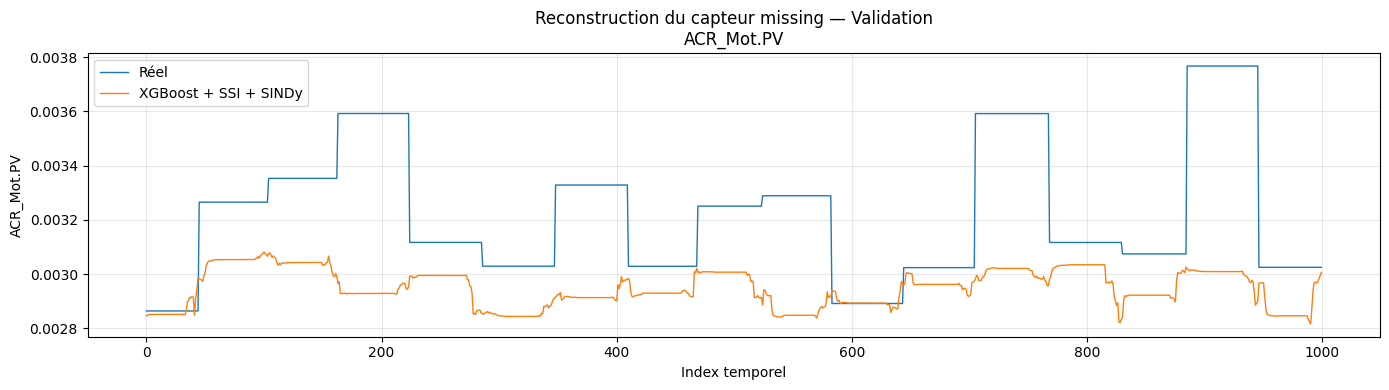

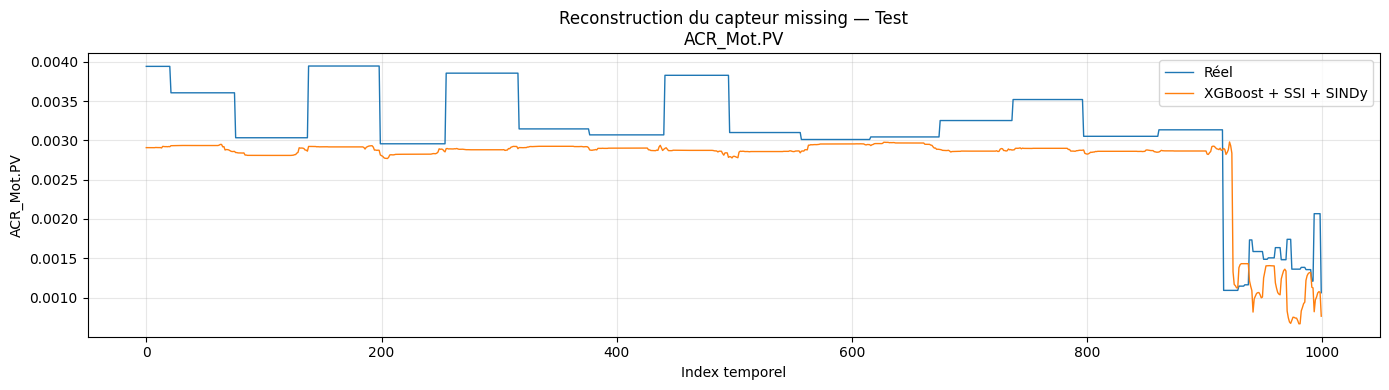

In [12]:
# ============================================================
# SSI → SINDy → XGBoost
# VERSION SANS CAPTEUR CIBLE DANS LES ENTRÉES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


# ============================================================
# 1. ÉTATS SSI ESTIMÉS UNIQUEMENT AVEC LES CAPTEURS DISPONIBLES
# ============================================================

Y_train_obs = train_s[
    OBS_SSI_SENSORS
].values

Y_val_obs = val_s[
    OBS_SSI_SENSORS
].values

Y_test_obs = test_s[
    OBS_SSI_SENSORS
].values


# ------------------------------------------------------------
# Identification SSI sur TRAIN uniquement
# ------------------------------------------------------------

A_obs, C_obs, Sv_obs = ssi_cov(
    Y_train_obs,
    SSI_BLOCK_ROWS,
    SSI_ORDER
)


print("=" * 60)
print("SSI SANS LE CAPTEUR CIBLE")
print("=" * 60)

print("Capteur cible :", TARGET_SENSOR)

print(
    "Capteurs disponibles :",
    OBS_SSI_SENSORS
)


# ============================================================
# 2. ESTIMATION DES ÉTATS SSI
# ============================================================

X_train_hat_obs = ssi_estimate_states(
    Y_train_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS
)

X_val_hat_obs = ssi_estimate_states(
    Y_val_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS
)

X_test_hat_obs = ssi_estimate_states(
    Y_test_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS
)


print("\nDimensions des états SSI :")

print(
    "Train :",
    X_train_hat_obs.shape
)

print(
    "Validation :",
    X_val_hat_obs.shape
)

print(
    "Test :",
    X_test_hat_obs.shape
)


# ============================================================
# 3. SINDy
# ============================================================

# ------------------------------------------------------------
# IMPORTANT :
# SINDy est entraîné UNIQUEMENT sur les états SSI
# construits avec les capteurs disponibles.
# ------------------------------------------------------------

sindy_model.fit(
    X_train_hat_obs,
    t=np.arange(
        len(X_train_hat_obs)
    ) * DT_APPROX
)


# ============================================================
# 4. DYNAMIQUE SINDy
# ============================================================

Xdot_train_sindy = sindy_model.predict(
    X_train_hat_sindy
)

Xdot_val_sindy = sindy_model.predict(
    X_val_hat_sindy
)
X_test_hat_sindy = SINDY_SCALER.transform(
    X_test_hat_obs
)

Xdot_test_sindy = sindy_model.predict(
    X_test_hat_sindy
)


# ============================================================
# 5. PRÉDICTION ONE-STEP SINDy
# ============================================================

Xnext_train_sindy = (
    sindy_model.predict_one_step(
        X_train_hat_sindy,
        DT_APPROX
    )
)

Xnext_val_sindy = (
    sindy_model.predict_one_step(
        X_val_hat_sindy,
        DT_APPROX
    )
)

Xnext_test_sindy = (
    sindy_model.predict_one_step(
        X_test_hat_sindy,
        DT_APPROX
    )
)


# ============================================================
# 6. ALIGNEMENT DES DIMENSIONS
# ============================================================
#
# predict_one_step peut retourner N-1 points.
# On enlève le dernier état SSI pour que toutes les
# features aient la même longueur.
# ============================================================

n_train = min(
    len(X_train_hat_obs),
    len(Xdot_train_sindy),
    len(Xnext_train_sindy)
)

n_val = min(
    len(X_val_hat_obs),
    len(Xdot_val_sindy),
    len(Xnext_val_sindy)
)

n_test = min(
    len(X_test_hat_obs),
    len(Xdot_test_sindy),
    len(Xnext_test_sindy)
)


# ============================================================
# 7. FEATURES SSI + SINDy
# ============================================================

X_train_sindy_features = np.column_stack([
    X_train_hat_obs[:n_train],
    Xdot_train_sindy[:n_train],
    Xnext_train_sindy[:n_train]
])


X_val_sindy_features = np.column_stack([
    X_val_hat_obs[:n_val],
    Xdot_val_sindy[:n_val],
    Xnext_val_sindy[:n_val]
])


X_test_sindy_features = np.column_stack([
    X_test_hat_obs[:n_test],
    Xdot_test_sindy[:n_test],
    Xnext_test_sindy[:n_test]
])


print("\nDimensions des features SSI + SINDy :")

print(
    "Train :",
    X_train_sindy_features.shape
)

print(
    "Validation :",
    X_val_sindy_features.shape
)

print(
    "Test :",
    X_test_sindy_features.shape
)


# ============================================================
# 8. LAGS DES CAPTEURS DISPONIBLES
# ============================================================

N_LAGS = 10


def create_lag_features(
    df,
    sensor_columns,
    n_lags
):

    data = {}

    for sensor in sensor_columns:

        for lag in range(
            n_lags + 1
        ):

            data[
                f"{sensor}_lag{lag}"
            ] = df[
                sensor
            ].shift(lag)

    return pd.DataFrame(
        data,
        index=df.index
    )


X_train_lags = create_lag_features(
    train_s,
    OBS_SSI_SENSORS,
    N_LAGS
)

X_val_lags = create_lag_features(
    val_s,
    OBS_SSI_SENSORS,
    N_LAGS
)

X_test_lags = create_lag_features(
    test_s,
    OBS_SSI_SENSORS,
    N_LAGS
)


# ============================================================
# 9. ALIGNEMENT LAGS + SSI + SINDy
# ============================================================

X_train_hybrid = pd.concat(
    [
        X_train_lags.reset_index(drop=True),
        pd.DataFrame(
            X_train_sindy_features
        )
    ],
    axis=1
)


X_val_hybrid = pd.concat(
    [
        X_val_lags.reset_index(drop=True),
        pd.DataFrame(
            X_val_sindy_features
        )
    ],
    axis=1
)


X_test_hybrid = pd.concat(
    [
        X_test_lags.reset_index(drop=True),
        pd.DataFrame(
            X_test_sindy_features
        )
    ],
    axis=1
)


# ============================================================
# 10. ALIGNEMENT FINAL AVEC LES TARGETS
# ============================================================

y_train_full = train_s[
    TARGET_SENSOR
].reset_index(drop=True)


y_val_full = val_s[
    TARGET_SENSOR
].reset_index(drop=True)


y_test_full = test_s[
    TARGET_SENSOR
].reset_index(drop=True)


# ============================================================
# 11. MASQUES VALIDES
# ============================================================

train_mask = (
    X_train_hybrid.notna().all(axis=1)
    &
    y_train_full.notna()
)

val_mask = (
    X_val_hybrid.notna().all(axis=1)
    &
    y_val_full.notna()
)

test_mask = (
    X_test_hybrid.notna().all(axis=1)
    &
    y_test_full.notna()
)


X_train_hybrid = X_train_hybrid.loc[
    train_mask
].reset_index(drop=True)

X_val_hybrid = X_val_hybrid.loc[
    val_mask
].reset_index(drop=True)

X_test_hybrid = X_test_hybrid.loc[
    test_mask
].reset_index(drop=True)


y_train = y_train_full.loc[
    train_mask
].reset_index(drop=True)

y_val = y_val_full.loc[
    val_mask
].reset_index(drop=True)

y_test = y_test_full.loc[
    test_mask
].reset_index(drop=True)


# ============================================================
# 12. XGBOOST HYBRIDE
# ============================================================

XGB_PARAMS = {
    "n_estimators": 500,
    "max_depth": 6,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1
}


xgb_hybrid = XGBRegressor(
    **XGB_PARAMS
)


xgb_hybrid.fit(
    X_train_hybrid,
    y_train
)


# ============================================================
# 13. PRÉDICTIONS
# ============================================================

# ------------------------------------------------------------
# IMPORTANT :
# y_val et y_test restent les vraies valeurs standardisées.
# NE PAS les écraser avec les prédictions.
# ------------------------------------------------------------

y_val_pred_scaled = xgb_hybrid.predict(
    X_val_hybrid
)

y_test_pred_scaled = xgb_hybrid.predict(
    X_test_hybrid
)


# ============================================================
# 14. RETOUR À L'ÉCHELLE ORIGINALE DU TARGET UNIQUEMENT
# ============================================================

# ------------------------------------------------------------
# Le scaler a été entraîné sur les 10 capteurs.
# On récupère la position exacte de TARGET_SENSOR.
# ------------------------------------------------------------

TARGET_IDX = list(train_s.columns).index(TARGET_SENSOR)

print("=" * 60)
print("INVERSE TRANSFORM DU TARGET")
print("=" * 60)

print("Target :", TARGET_SENSOR)
print("Index du target dans le scaler :", TARGET_IDX)

print("Mean target :", scaler.mean_[TARGET_IDX])
print("Scale target :", scaler.scale_[TARGET_IDX])


# ------------------------------------------------------------
# Paramètres du StandardScaler correspondant au target
# ------------------------------------------------------------

TARGET_MEAN = scaler.mean_[TARGET_IDX]
TARGET_SCALE = scaler.scale_[TARGET_IDX]


# ------------------------------------------------------------
# Retour à l'échelle physique
# ------------------------------------------------------------

y_val_original = (
    y_val.values * TARGET_SCALE
    + TARGET_MEAN
)

y_val_pred_original = (
    y_val_pred_scaled * TARGET_SCALE
    + TARGET_MEAN
)


y_test_original = (
    y_test.values * TARGET_SCALE
    + TARGET_MEAN
)

y_test_pred_original = (
    y_test_pred_scaled * TARGET_SCALE
    + TARGET_MEAN
)


print("\nDimensions :")

print(
    "y_val_original :",
    y_val_original.shape
)

print(
    "y_val_pred_original :",
    y_val_pred_original.shape
)

print(
    "y_test_original :",
    y_test_original.shape
)

print(
    "y_test_pred_original :",
    y_test_pred_original.shape
)

# ============================================================
# 14. RETOUR À L'ÉCHELLE ORIGINALE
# ============================================================

# ------------------------------------------------------------
# y_val / y_test :
# vraies valeurs standardisées
#
# y_val_pred_scaled / y_test_pred_scaled :
# prédictions standardisées
#
# On inverse la transformation pour obtenir les valeurs
# dans l'unité physique originale du capteur.
# ------------------------------------------------------------



# ============================================================
# 15. ÉVALUATION
# ============================================================

def evaluate(
    y_true,
    y_pred,
    name
):

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    corr = np.corrcoef(
        y_true,
        y_pred
    )[0, 1]

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        f"RMSE        = {rmse:.6f}"
    )

    print(
        f"MAE         = {mae:.6f}"
    )

    print(
        f"R²          = {r2:.6f}"
    )

    print(
        f"Corrélation = {corr:.6f}"
    )

    return {
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Correlation": corr
    }


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

results_val = evaluate(
    y_val_original,
    y_val_pred_original,
    "XGBoost + SSI + SINDy — Validation"
)


# ------------------------------------------------------------
# Test
# ------------------------------------------------------------

results_test = evaluate(
    y_test_original,
    y_test_pred_original,
    "XGBoost + SSI + SINDy — Test"
)


# ============================================================
# 16. VISUALISATION VALIDATION
# ============================================================

n_plot = min(
    1000,
    len(y_val_original)
)

plt.figure(
    figsize=(14, 4)
)

plt.plot(
    y_val_original[:n_plot],
    label="Réel",
    lw=1
)

plt.plot(
    y_val_pred_original[:n_plot],
    label="XGBoost + SSI + SINDy",
    lw=1
)

plt.title(
    f"Reconstruction du capteur missing — Validation\n"
    f"{TARGET_SENSOR}"
)

plt.xlabel(
    "Index temporel"
)

plt.ylabel(
    TARGET_SENSOR
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 17. VISUALISATION TEST
# ============================================================

n_plot = min(
    1000,
    len(y_test_original)
)

plt.figure(
    figsize=(14, 4)
)

plt.plot(
    y_test_original[:n_plot],
    label="Réel",
    lw=1
)

plt.plot(
    y_test_pred_original[:n_plot],
    label="XGBoost + SSI + SINDy",
    lw=1
)

plt.title(
    f"Reconstruction du capteur missing — Test\n"
    f"{TARGET_SENSOR}"
)

plt.xlabel(
    "Index temporel"
)

plt.ylabel(
    TARGET_SENSOR
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

## 5. CNN 1D + SSI + lags + XGBoost

Pourquoi : le CNN cherche des motifs locaux dans une fenêtre temporelle, SSI apporte une vue globale des états cachés, et les lags donnent le retard de propagation possible. Cette version ne passe pas par SINDy : elle teste si les motifs et SSI suffisent.


ALIGNEMENT SSI
Train        | observations =   9410 | états SSI =   9396 | décalage SSI = 14
Validation   | observations =   3136 | états SSI =   3122 | décalage SSI = 14
Test         | observations =   3140 | états SSI =   3126 | décalage SSI = 14

Décalage SSI retenu : 14

DIMENSIONS APRÈS ALIGNEMENT
CNN train  : (9381, 30, 9)
Lags train : (9381, 117)
SSI train  : (9381, 8)
y train    : (9381,)
Epoch 1/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1400 - mae: 0.2356 - val_loss: 0.8236 - val_mae: 0.8304
Epoch 2/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0418 - mae: 0.1466 - val_loss: 0.3951 - val_mae: 0.5534
Epoch 3/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0336 - mae: 0.1338 - val_loss: 0.2069 - val_mae: 0.3528
Epoch 4/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0235 - mae: 0.1081 - val_loss: 0.2250 - val_mae: 0.3784
Epoch 5/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0214 - mae: 0.1023 - val_loss: 0.2956 - val_mae: 0.4411
Epoch

,split,RMSE,MAE,R2,Correlation
0,Train,0.069506,0.045076,0.995172,0.997662
1,Validation,0.448067,0.353150,0.827484,0.961730
2,Test,0.497007,0.342749,0.796321,0.928147



Capteur cible : ACR_Mot.PV
TARGET_MEAN  : 0.00214400
TARGET_SCALE : 0.00091395

Métriques dans l'unité originale :


,split,RMSE,MAE,R2,Correlation
0,Train,0.000064,0.000041,0.995172,0.997662
1,Validation,0.000410,0.000323,0.827484,0.961730
2,Test,0.000454,0.000313,0.796321,0.928147


,time_index_in_test,y_true_scaled,y_pred_scaled,y_true_original,y_pred_original
0,29,1.965860,0.954382,0.003941,0.003016
1,30,1.965860,0.954382,0.003941,0.003016
2,31,1.597892,0.954382,0.003604,0.003016
3,32,1.597892,0.954382,0.003604,0.003016
4,33,1.597892,0.948553,0.003604,0.003011


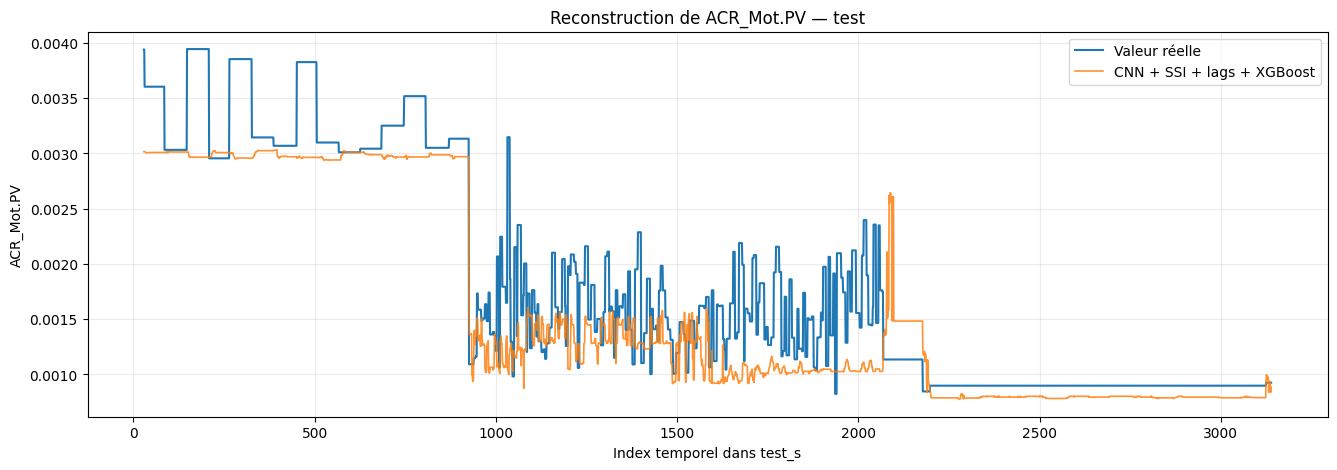

In [13]:
# ============================================================
# CNN 1D + SSI + Lags -> XGBoost
# Reconstruction de TARGET_SENSOR sans SINDy
#
# Prérequis :
# train_s, val_s, test_s, scaler
# TARGET_SENSOR, OBS_SSI_SENSORS
# SSI_BLOCK_ROWS, SSI_ORDER
# ssi_cov(), ssi_estimate_states()
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)


# ============================================================
# 0. PARAMÈTRES
# ============================================================

SEED = 42

WINDOW = 30
N_LAGS = 10

CNN_EPOCHS = 100
CNN_BATCH_SIZE = 64
CNN_EMBEDDING_DIM = 32

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


# ============================================================
# 1. VÉRIFICATIONS
# ============================================================

required_variables = [
    "train_s",
    "val_s",
    "test_s",
    "scaler",
    "TARGET_SENSOR",
    "OBS_SSI_SENSORS",
    "SSI_BLOCK_ROWS",
    "SSI_ORDER",
    "ssi_cov",
    "ssi_estimate_states",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Variables/fonctions manquantes : "
        + ", ".join(missing_variables)
    )

if TARGET_SENSOR in OBS_SSI_SENSORS:
    raise ValueError(
        f"{TARGET_SENSOR} ne doit pas être inclus dans OBS_SSI_SENSORS."
    )

if TARGET_SENSOR not in train_s.columns:
    raise ValueError(
        f"Le capteur cible {TARGET_SENSOR} est absent de train_s."
    )

if (
    list(train_s.columns) != list(val_s.columns)
    or list(train_s.columns) != list(test_s.columns)
):
    raise ValueError(
        "train_s, val_s et test_s doivent avoir les mêmes colonnes."
    )


# ============================================================
# 2. DONNÉES OBSERVÉES ET CIBLE
# ============================================================

# Les entrées ne contiennent jamais le capteur cible.
Y_train_obs = train_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
Y_val_obs = val_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
Y_test_obs = test_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)

# La cible est disponible uniquement pour entraîner/évaluer.
y_train_full = train_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_val_full = val_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_test_full = test_s[TARGET_SENSOR].to_numpy(dtype=np.float32)


# ============================================================
# 3. SSI : IDENTIFICATION UNIQUEMENT SUR TRAIN
# ============================================================

A_obs, C_obs, Sv_obs = ssi_cov(
    Y_train_obs,
    SSI_BLOCK_ROWS,
    SSI_ORDER,
)

X_train_hat_obs = ssi_estimate_states(
    Y_train_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS,
)

X_val_hat_obs = ssi_estimate_states(
    Y_val_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS,
)

X_test_hat_obs = ssi_estimate_states(
    Y_test_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS,
)

X_train_hat_obs = np.asarray(
    X_train_hat_obs,
    dtype=np.float32,
)

X_val_hat_obs = np.asarray(
    X_val_hat_obs,
    dtype=np.float32,
)

X_test_hat_obs = np.asarray(
    X_test_hat_obs,
    dtype=np.float32,
)


# ============================================================
# 4. DÉCALAGE SSI
#
# Exemple :
# 9410 observations et 9396 états SSI
# --> SSI_OFFSET = 14
#
# état SSI[k] correspond à l'instant brut t = k + 14
# ============================================================

def get_ssi_offset(states, observations, split_name):
    offset = len(observations) - len(states)

    if offset < 0:
        raise ValueError(
            f"SSI renvoie trop d'états sur {split_name}."
        )

    print(
        f"{split_name:<12} | "
        f"observations = {len(observations):>6} | "
        f"états SSI = {len(states):>6} | "
        f"décalage SSI = {offset}"
    )

    return offset


print("=" * 70)
print("ALIGNEMENT SSI")
print("=" * 70)

SSI_OFFSET_TRAIN = get_ssi_offset(
    X_train_hat_obs,
    Y_train_obs,
    "Train",
)

SSI_OFFSET_VAL = get_ssi_offset(
    X_val_hat_obs,
    Y_val_obs,
    "Validation",
)

SSI_OFFSET_TEST = get_ssi_offset(
    X_test_hat_obs,
    Y_test_obs,
    "Test",
)

if not (
    SSI_OFFSET_TRAIN
    == SSI_OFFSET_VAL
    == SSI_OFFSET_TEST
):
    raise ValueError(
        "Le décalage SSI doit être identique sur train, validation et test."
    )

SSI_OFFSET = SSI_OFFSET_TRAIN

print("\nDécalage SSI retenu :", SSI_OFFSET)


# ============================================================
# 5. CONSTRUCTION DES FEATURES ALIGNÉES
#
# Pour le même instant brut t :
#
# CNN  = observés[t-WINDOW+1 : t+1]
# Lags = observés[t], ..., observés[t-N_LAGS]
# SSI  = état SSI[t - SSI_OFFSET]
# y    = cible[t]
# ============================================================

def build_aligned_split(
    observed_sensors,
    ssi_states,
    target,
    window,
    n_lags,
    ssi_offset,
):
    observed_sensors = np.asarray(
        observed_sensors,
        dtype=np.float32,
    )

    ssi_states = np.asarray(
        ssi_states,
        dtype=np.float32,
    )

    target = np.asarray(
        target,
        dtype=np.float32,
    )

    n_raw = len(target)

    if len(observed_sensors) != n_raw:
        raise ValueError(
            "Les observations et la cible n'ont pas la même longueur."
        )

    if len(ssi_states) != n_raw - ssi_offset:
        raise ValueError(
            "Les dimensions SSI sont incompatibles avec SSI_OFFSET."
        )

    # Premier instant où CNN, lags et SSI sont tous disponibles.
    first_t = max(
        window - 1,
        n_lags,
        ssi_offset,
    )

    if n_raw <= first_t:
        raise ValueError(
            "Pas assez d'observations pour construire les features."
        )

    valid_t = np.arange(
        first_t,
        n_raw,
    )

    # CNN : (n_exemples, WINDOW, n_capteurs_observés)
    X_cnn = np.stack(
        [
            observed_sensors[
                t - window + 1:t + 1
            ]
            for t in valid_t
        ],
        axis=0,
    )

    # Lags : x(t), x(t-1), ..., x(t-N_LAGS)
    X_lags = np.concatenate(
        [
            np.stack(
                [
                    observed_sensors[t - lag]
                    for t in valid_t
                ],
                axis=0,
            )
            for lag in range(n_lags + 1)
        ],
        axis=1,
    )

    # Variations : utiles pour les changements rapides.
    X_delta_1 = np.stack(
        [
            observed_sensors[t]
            - observed_sensors[t - 1]
            for t in valid_t
        ],
        axis=0,
    )

    X_delta_3 = np.stack(
        [
            observed_sensors[t]
            - observed_sensors[t - 3]
            for t in valid_t
        ],
        axis=0,
    )

    # Ajout des variations aux lags.
    X_lags = np.hstack([
        X_lags,
        X_delta_1,
        X_delta_3,
    ])

    # t brut -> index dans le tableau des états SSI.
    ssi_indices = valid_t - ssi_offset

    X_ssi = ssi_states[ssi_indices]

    # Cible au même instant t.
    y = target[valid_t]

    return (
        X_cnn,
        X_lags,
        X_ssi,
        y,
        valid_t,
    )


(
    X_cnn_train,
    X_lags_train,
    X_ssi_train,
    y_train,
    idx_train,
) = build_aligned_split(
    Y_train_obs,
    X_train_hat_obs,
    y_train_full,
    WINDOW,
    N_LAGS,
    SSI_OFFSET,
)

(
    X_cnn_val,
    X_lags_val,
    X_ssi_val,
    y_val,
    idx_val,
) = build_aligned_split(
    Y_val_obs,
    X_val_hat_obs,
    y_val_full,
    WINDOW,
    N_LAGS,
    SSI_OFFSET,
)

(
    X_cnn_test,
    X_lags_test,
    X_ssi_test,
    y_test,
    idx_test,
) = build_aligned_split(
    Y_test_obs,
    X_test_hat_obs,
    y_test_full,
    WINDOW,
    N_LAGS,
    SSI_OFFSET,
)

print("\n" + "=" * 70)
print("DIMENSIONS APRÈS ALIGNEMENT")
print("=" * 70)
print("CNN train  :", X_cnn_train.shape)
print("Lags train :", X_lags_train.shape)
print("SSI train  :", X_ssi_train.shape)
print("y train    :", y_train.shape)


# ============================================================
# 6. CNN 1D
#
# Flatten préserve les positions temporelles ; GlobalAveragePooling
# lissait trop fortement les variations dans ton cas.
# ============================================================

n_observed_sensors = X_cnn_train.shape[-1]

cnn_input = tf.keras.Input(
    shape=(
        WINDOW,
        n_observed_sensors,
    ),
    name="observed_sensor_window",
)

x = tf.keras.layers.Conv1D(
    filters=32,
    kernel_size=3,
    padding="causal",
    activation="relu",
)(cnn_input)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Conv1D(
    filters=64,
    kernel_size=5,
    padding="causal",
    activation="relu",
)(x)

x = tf.keras.layers.BatchNormalization()(x)

# Préserve la localisation temporelle des motifs.
x = tf.keras.layers.Flatten()(x)

x = tf.keras.layers.Dense(
    64,
    activation="relu",
)(x)

x = tf.keras.layers.Dense(
    CNN_EMBEDDING_DIM,
    activation="relu",
    name="cnn_embedding",
)(x)

cnn_output = tf.keras.layers.Dense(
    1,
    name="cnn_target_prediction",
)(x)

cnn_model = tf.keras.Model(
    inputs=cnn_input,
    outputs=cnn_output,
    name="cnn_1d_ssi_lags",
)

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3,
    ),
    loss="mse",
    metrics=["mae"],
)

cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
    )
]

history_cnn = cnn_model.fit(
    X_cnn_train,
    y_train,
    validation_data=(
        X_cnn_val,
        y_val,
    ),
    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH_SIZE,
    verbose=1,
    callbacks=cnn_callbacks,
    shuffle=True,
)


# ============================================================
# 7. EMBEDDINGS CNN
# ============================================================

cnn_embedding_model = tf.keras.Model(
    inputs=cnn_model.input,
    outputs=cnn_model.get_layer(
        "cnn_embedding"
    ).output,
)

X_cnn_emb_train = cnn_embedding_model.predict(
    X_cnn_train,
    verbose=0,
)

X_cnn_emb_val = cnn_embedding_model.predict(
    X_cnn_val,
    verbose=0,
)

X_cnn_emb_test = cnn_embedding_model.predict(
    X_cnn_test,
    verbose=0,
)


# ============================================================
# 8. FUSION : CNN + SSI + LAGS
# ============================================================

X_train_final = np.hstack([
    X_cnn_emb_train,
    X_ssi_train,
    X_lags_train,
]).astype(np.float32)

X_val_final = np.hstack([
    X_cnn_emb_val,
    X_ssi_val,
    X_lags_val,
]).astype(np.float32)

X_test_final = np.hstack([
    X_cnn_emb_test,
    X_ssi_test,
    X_lags_test,
]).astype(np.float32)

print("\n" + "=" * 70)
print("DIMENSIONS FINALES XGBOOST")
print("=" * 70)
print("Train      :", X_train_final.shape)
print("Validation :", X_val_final.shape)
print("Test       :", X_test_final.shape)


# ============================================================
# 9. XGBOOST
# ============================================================

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.80,
    colsample_bytree=0.80,
    reg_alpha=0.01,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1,
    early_stopping_rounds=50,
)

xgb_model.fit(
    X_train_final,
    y_train,
    eval_set=[
        (
            X_val_final,
            y_val,
        )
    ],
    verbose=False,
)

# Les y restent les vraies valeurs ; on ne les écrase pas.
y_train_pred = xgb_model.predict(X_train_final)
y_val_pred = xgb_model.predict(X_val_final)
y_test_pred = xgb_model.predict(X_test_final)


# ============================================================
# 10. MÉTRIQUES
# ============================================================

def regression_metrics(
    y_true,
    y_pred,
    split_name,
):
    return {
        "split": split_name,
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "R2": r2_score(
            y_true,
            y_pred,
        ),
        "Correlation": np.corrcoef(
            y_true,
            y_pred,
        )[0, 1],
    }


metrics_scaled = pd.DataFrame([
    regression_metrics(
        y_train,
        y_train_pred,
        "Train",
    ),
    regression_metrics(
        y_val,
        y_val_pred,
        "Validation",
    ),
    regression_metrics(
        y_test,
        y_test_pred,
        "Test",
    ),
])

print("\nMétriques dans l'espace standardisé :")
display(metrics_scaled)


# ============================================================
# 11. RETOUR À L'UNITÉ ORIGINALE
# ============================================================

TARGET_IDX = list(
    train_s.columns
).index(TARGET_SENSOR)

TARGET_MEAN = float(
    scaler.mean_[TARGET_IDX]
)

TARGET_SCALE = float(
    scaler.scale_[TARGET_IDX]
)

def inverse_target_scale(y_scaled):
    y_scaled = np.asarray(
        y_scaled,
        dtype=float,
    )

    return (
        y_scaled * TARGET_SCALE
        + TARGET_MEAN
    )


y_train_original = inverse_target_scale(y_train)
y_val_original = inverse_target_scale(y_val)
y_test_original = inverse_target_scale(y_test)

y_train_pred_original = inverse_target_scale(y_train_pred)
y_val_pred_original = inverse_target_scale(y_val_pred)
y_test_pred_original = inverse_target_scale(y_test_pred)

metrics_original = pd.DataFrame([
    regression_metrics(
        y_train_original,
        y_train_pred_original,
        "Train",
    ),
    regression_metrics(
        y_val_original,
        y_val_pred_original,
        "Validation",
    ),
    regression_metrics(
        y_test_original,
        y_test_pred_original,
        "Test",
    ),
])

print(f"\nCapteur cible : {TARGET_SENSOR}")
print(f"TARGET_MEAN  : {TARGET_MEAN:.8f}")
print(f"TARGET_SCALE : {TARGET_SCALE:.8f}")

print("\nMétriques dans l'unité originale :")
display(metrics_original)


# ============================================================
# 12. VISUALISATION TEST
# ============================================================

results_test = pd.DataFrame({
    "time_index_in_test": idx_test,
    "y_true_scaled": y_test,
    "y_pred_scaled": y_test_pred,
    "y_true_original": y_test_original,
    "y_pred_original": y_test_pred_original,
})

display(results_test.head())

plt.figure(figsize=(16, 5))

plt.plot(
    results_test["time_index_in_test"],
    results_test["y_true_original"],
    label="Valeur réelle",
    linewidth=1.5,
)

plt.plot(
    results_test["time_index_in_test"],
    results_test["y_pred_original"],
    label="CNN + SSI + lags + XGBoost",
    linewidth=1.2,
    alpha=0.85,
)

plt.title(
    f"Reconstruction de {TARGET_SENSOR} — test"
)

plt.xlabel("Index temporel dans test_s")
plt.ylabel(TARGET_SENSOR)

plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 6. CNN 1D + lags + XGBoost

Pourquoi : essai plus simple, sans SSI ni SINDy. Il permet de vérifier si les motifs temporels bruts et le passé récent expliquent déjà la reconstruction.


DIMENSIONS APRÈS ALIGNEMENT
CNN train      : (9381, 30, 9)
Features train : (9381, 117)
Cible train    : (9381,)
CNN validation : (3107, 30, 9)
CNN test       : (3111, 30, 9)
Epoch 1/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.1400 - mae: 0.2356 - val_loss: 0.8236 - val_mae: 0.8304
Epoch 2/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0418 - mae: 0.1466 - val_loss: 0.3951 - val_mae: 0.5534
Epoch 3/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0336 - mae: 0.1338 - val_loss: 0.2069 - val_mae: 0.3528
Epoch 4/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0235 - mae: 0.1081 - val_loss: 0.2250 - val_mae: 0.3784
Epoch 5/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0214 - mae: 0.1023 - val_loss: 0.2956 - val_mae: 0.4411
Epoch 6/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0186 - mae: 0.0942 - val_loss: 0.3222 - val_mae: 0.4678
Epoch 7/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0166 - mae: 0.0895 - val_loss: 0.3082 - val_mae

,split,RMSE,MAE,R2,Correlation
0,Train,0.072501,0.046781,0.994747,0.997443
1,Validation,0.471557,0.380593,0.808922,0.961305
2,Test,0.489074,0.341083,0.802771,0.927517



Capteur cible : ACR_Mot.PV
TARGET_MEAN  : 0.00214400
TARGET_SCALE : 0.00091395

Métriques dans l'unité originale :


,split,RMSE,MAE,R2,Correlation
0,Train,0.000066,0.000043,0.994747,0.997443
1,Validation,0.000431,0.000348,0.808922,0.961305
2,Test,0.000447,0.000312,0.802771,0.927517


,time_index_in_test,y_true_scaled,y_pred_scaled,y_true_original,y_pred_original
0,29,1.965860,0.925584,0.003941,0.002990
1,30,1.965860,0.925584,0.003941,0.002990
2,31,1.597892,0.925584,0.003604,0.002990
3,32,1.597892,0.925584,0.003604,0.002990
4,33,1.597892,0.916394,0.003604,0.002982


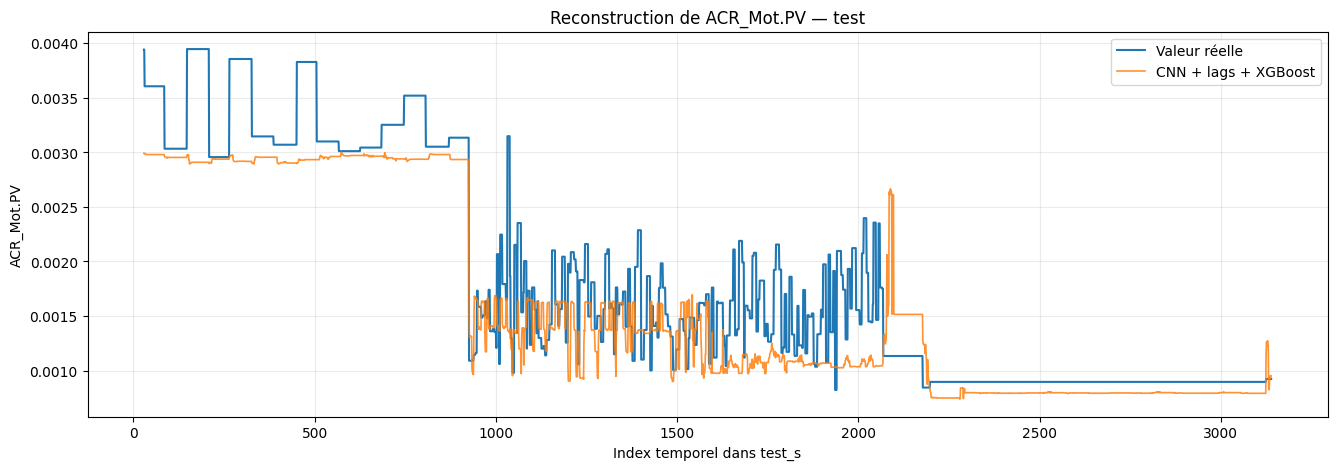

In [14]:
# ============================================================
# CNN 1D + Lags -> XGBoost
# Reconstruction de TARGET_SENSOR
# Sans SSI et sans SINDy
#
# Prérequis :
# train_s, val_s, test_s, scaler
# TARGET_SENSOR, OBS_SSI_SENSORS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)


# ============================================================
# 0. PARAMÈTRES
# ============================================================

SEED = 42

WINDOW = 30
N_LAGS = 10

CNN_EPOCHS = 100
CNN_BATCH_SIZE = 64
CNN_EMBEDDING_DIM = 32

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


# ============================================================
# 1. VÉRIFICATIONS
# ============================================================

required_variables = [
    "train_s",
    "val_s",
    "test_s",
    "scaler",
    "TARGET_SENSOR",
    "OBS_SSI_SENSORS",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Variables manquantes : "
        + ", ".join(missing_variables)
    )

if TARGET_SENSOR in OBS_SSI_SENSORS:
    raise ValueError(
        f"{TARGET_SENSOR} ne doit pas être inclus dans OBS_SSI_SENSORS."
    )

if TARGET_SENSOR not in train_s.columns:
    raise ValueError(
        f"Le capteur cible {TARGET_SENSOR} est absent de train_s."
    )

if (
    list(train_s.columns) != list(val_s.columns)
    or list(train_s.columns) != list(test_s.columns)
):
    raise ValueError(
        "train_s, val_s et test_s doivent avoir les mêmes colonnes."
    )


# ============================================================
# 2. CAPTEURS OBSERVÉS ET CIBLE
# ============================================================

# Entrées : uniquement les capteurs observés.
X_train_obs = train_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
X_val_obs = val_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
X_test_obs = test_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)

# Cible : utilisée uniquement pour l'entraînement et l'évaluation.
y_train_full = train_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_val_full = val_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_test_full = test_s[TARGET_SENSOR].to_numpy(dtype=np.float32)


# ============================================================
# 3. FEATURES TEMPORELLES ALIGNÉES
#
# À chaque instant t :
#
# CNN  : X[t-WINDOW+1 : t+1]
# Lags : X[t], X[t-1], ..., X[t-N_LAGS]
# Delta: X[t]-X[t-1] et X[t]-X[t-3]
# y    : TARGET_SENSOR[t]
# ============================================================

def build_aligned_split(
    observed_sensors,
    target,
    window,
    n_lags,
):
    observed_sensors = np.asarray(
        observed_sensors,
        dtype=np.float32,
    )

    target = np.asarray(
        target,
        dtype=np.float32,
    )

    if len(observed_sensors) != len(target):
        raise ValueError(
            "Les capteurs observés et la cible doivent avoir la même longueur."
        )

    n_samples = len(target)

    first_t = max(
        window - 1,
        n_lags,
        3,  # nécessaire à delta_3
    )

    if n_samples <= first_t:
        raise ValueError(
            f"Pas assez d'observations ({n_samples}) "
            f"pour WINDOW={window} et N_LAGS={n_lags}."
        )

    valid_t = np.arange(
        first_t,
        n_samples,
    )

    # CNN : shape (n_exemples, WINDOW, n_capteurs)
    X_cnn = np.stack(
        [
            observed_sensors[
                t - window + 1:t + 1
            ]
            for t in valid_t
        ],
        axis=0,
    )

    # Lags : [X(t), X(t-1), ..., X(t-N_LAGS)]
    X_lags = np.concatenate(
        [
            np.stack(
                [
                    observed_sensors[t - lag]
                    for t in valid_t
                ],
                axis=0,
            )
            for lag in range(n_lags + 1)
        ],
        axis=1,
    )

    # Variations courtes : importantes dans les régimes transitoires.
    X_delta_1 = np.stack(
        [
            observed_sensors[t]
            - observed_sensors[t - 1]
            for t in valid_t
        ],
        axis=0,
    )

    X_delta_3 = np.stack(
        [
            observed_sensors[t]
            - observed_sensors[t - 3]
            for t in valid_t
        ],
        axis=0,
    )

    X_tabular = np.hstack([
        X_lags,
        X_delta_1,
        X_delta_3,
    ])

    y = target[valid_t]

    return (
        X_cnn,
        X_tabular,
        y,
        valid_t,
    )


(
    X_cnn_train,
    X_tabular_train,
    y_train,
    idx_train,
) = build_aligned_split(
    X_train_obs,
    y_train_full,
    WINDOW,
    N_LAGS,
)

(
    X_cnn_val,
    X_tabular_val,
    y_val,
    idx_val,
) = build_aligned_split(
    X_val_obs,
    y_val_full,
    WINDOW,
    N_LAGS,
)

(
    X_cnn_test,
    X_tabular_test,
    y_test,
    idx_test,
) = build_aligned_split(
    X_test_obs,
    y_test_full,
    WINDOW,
    N_LAGS,
)

print("=" * 70)
print("DIMENSIONS APRÈS ALIGNEMENT")
print("=" * 70)
print("CNN train      :", X_cnn_train.shape)
print("Features train :", X_tabular_train.shape)
print("Cible train    :", y_train.shape)
print("CNN validation :", X_cnn_val.shape)
print("CNN test       :", X_cnn_test.shape)


# ============================================================
# 4. CNN 1D
#
# Flatten est utilisé pour garder les positions dans la fenêtre
# temporelle ; le pooling moyen lissait trop les variations.
# ============================================================

n_observed_sensors = X_cnn_train.shape[-1]

cnn_input = tf.keras.Input(
    shape=(
        WINDOW,
        n_observed_sensors,
    ),
    name="observed_sensor_window",
)

x = tf.keras.layers.Conv1D(
    filters=32,
    kernel_size=3,
    padding="causal",
    activation="relu",
)(cnn_input)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Conv1D(
    filters=64,
    kernel_size=5,
    padding="causal",
    activation="relu",
)(x)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Flatten()(x)

x = tf.keras.layers.Dense(
    64,
    activation="relu",
)(x)

x = tf.keras.layers.Dense(
    CNN_EMBEDDING_DIM,
    activation="relu",
    name="cnn_embedding",
)(x)

cnn_output = tf.keras.layers.Dense(
    1,
    name="cnn_target_prediction",
)(x)

cnn_model = tf.keras.Model(
    inputs=cnn_input,
    outputs=cnn_output,
    name="cnn_1d_lags",
)

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3,
    ),
    loss="mse",
    metrics=["mae"],
)

cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
    )
]

history_cnn = cnn_model.fit(
    X_cnn_train,
    y_train,
    validation_data=(
        X_cnn_val,
        y_val,
    ),
    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH_SIZE,
    verbose=1,
    callbacks=cnn_callbacks,
    shuffle=True,
)


# ============================================================
# 5. EXTRACTION DES EMBEDDINGS CNN
# ============================================================

cnn_embedding_model = tf.keras.Model(
    inputs=cnn_model.input,
    outputs=cnn_model.get_layer(
        "cnn_embedding"
    ).output,
    name="cnn_embedding_extractor",
)

X_cnn_emb_train = cnn_embedding_model.predict(
    X_cnn_train,
    verbose=0,
)

X_cnn_emb_val = cnn_embedding_model.predict(
    X_cnn_val,
    verbose=0,
)

X_cnn_emb_test = cnn_embedding_model.predict(
    X_cnn_test,
    verbose=0,
)


# ============================================================
# 6. FUSION CNN + LAGS + VARIATIONS
# ============================================================

X_train_final = np.hstack([
    X_cnn_emb_train,
    X_tabular_train,
]).astype(np.float32)

X_val_final = np.hstack([
    X_cnn_emb_val,
    X_tabular_val,
]).astype(np.float32)

X_test_final = np.hstack([
    X_cnn_emb_test,
    X_tabular_test,
]).astype(np.float32)

print("\n" + "=" * 70)
print("DIMENSIONS FINALES XGBOOST")
print("=" * 70)
print("Train      :", X_train_final.shape)
print("Validation :", X_val_final.shape)
print("Test       :", X_test_final.shape)


# ============================================================
# 7. XGBOOST
# ============================================================

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.80,
    colsample_bytree=0.80,
    reg_alpha=0.01,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1,
    early_stopping_rounds=50,
)

xgb_model.fit(
    X_train_final,
    y_train,
    eval_set=[
        (
            X_val_final,
            y_val,
        )
    ],
    verbose=False,
)

# Ne jamais écraser y_test avec une prédiction.
y_train_pred = xgb_model.predict(X_train_final)
y_val_pred = xgb_model.predict(X_val_final)
y_test_pred = xgb_model.predict(X_test_final)


# ============================================================
# 8. MÉTRIQUES
# ============================================================

def regression_metrics(
    y_true,
    y_pred,
    split_name,
):
    return {
        "split": split_name,
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "R2": r2_score(
            y_true,
            y_pred,
        ),
        "Correlation": np.corrcoef(
            y_true,
            y_pred,
        )[0, 1],
    }


metrics_scaled = pd.DataFrame([
    regression_metrics(
        y_train,
        y_train_pred,
        "Train",
    ),
    regression_metrics(
        y_val,
        y_val_pred,
        "Validation",
    ),
    regression_metrics(
        y_test,
        y_test_pred,
        "Test",
    ),
])

print("\nMétriques dans l'espace standardisé :")
display(metrics_scaled)


# ============================================================
# 9. RETOUR À L'ÉCHELLE ORIGINALE DU CAPTEUR CIBLE
# ============================================================

TARGET_IDX = list(
    train_s.columns
).index(TARGET_SENSOR)

TARGET_MEAN = float(
    scaler.mean_[TARGET_IDX]
)

TARGET_SCALE = float(
    scaler.scale_[TARGET_IDX]
)

def inverse_target_scale(y_scaled):
    y_scaled = np.asarray(
        y_scaled,
        dtype=float,
    )

    return (
        y_scaled * TARGET_SCALE
        + TARGET_MEAN
    )


y_train_original = inverse_target_scale(y_train)
y_val_original = inverse_target_scale(y_val)
y_test_original = inverse_target_scale(y_test)

y_train_pred_original = inverse_target_scale(y_train_pred)
y_val_pred_original = inverse_target_scale(y_val_pred)
y_test_pred_original = inverse_target_scale(y_test_pred)

metrics_original = pd.DataFrame([
    regression_metrics(
        y_train_original,
        y_train_pred_original,
        "Train",
    ),
    regression_metrics(
        y_val_original,
        y_val_pred_original,
        "Validation",
    ),
    regression_metrics(
        y_test_original,
        y_test_pred_original,
        "Test",
    ),
])

print(f"\nCapteur cible : {TARGET_SENSOR}")
print(f"TARGET_MEAN  : {TARGET_MEAN:.8f}")
print(f"TARGET_SCALE : {TARGET_SCALE:.8f}")

print("\nMétriques dans l'unité originale :")
display(metrics_original)


# ============================================================
# 10. RÉSULTATS ET VISUALISATION TEST
# ============================================================

results_test = pd.DataFrame({
    "time_index_in_test": idx_test,
    "y_true_scaled": y_test,
    "y_pred_scaled": y_test_pred,
    "y_true_original": y_test_original,
    "y_pred_original": y_test_pred_original,
})

display(results_test.head())

plt.figure(figsize=(16, 5))

plt.plot(
    results_test["time_index_in_test"],
    results_test["y_true_original"],
    label="Valeur réelle",
    linewidth=1.5,
)

plt.plot(
    results_test["time_index_in_test"],
    results_test["y_pred_original"],
    label="CNN + lags + XGBoost",
    linewidth=1.2,
    alpha=0.85,
)

plt.title(
    f"Reconstruction de {TARGET_SENSOR} — test"
)

plt.xlabel("Index temporel dans test_s")
plt.ylabel(TARGET_SENSOR)

plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 7. CNN 1D seul — témoin

Ce modèle est conservé comme point de comparaison : il mesure ce que le CNN peut faire seul, sans XGBoost, SSI, SINDy ni lags explicites.


DIMENSIONS
Train      : (9381, 30, 9) (9381,)
Validation : (3107, 30, 9) (3107,)
Test       : (3111, 30, 9) (3111,)


Model: "cnn_1d_direct_regression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ observed_sensor_window          │ (None, 30, 9)          │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 30, 32)         │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 30, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 30, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 30, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ target_prediction (Dense)       │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,697 (53.50 KB)

 Trainable params: 13,505 (52.75 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0981 - mae: 0.2012 - val_loss: 0.8052 - val_mae: 0.8050 - learning_rate: 0.0010
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0408 - mae: 0.1405 - val_loss: 0.2876 - val_mae: 0.4449 - learning_rate: 0.0010
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0337 - mae: 0.1273 - val_loss: 0.1408 - val_mae: 0.2663 - learning_rate: 0.0010
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0307 - mae: 0.1210 - val_loss: 0.1601 - val_mae: 0.2947 - learning_rate: 0.0010
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0274 - mae: 0.1124 - val_loss: 0.1621 - val_mae: 0.2977 - learning_rate: 0.0010
Epoch 6/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0258 - mae: 0.1088 - val_loss: 0.1797 - val_mae: 0.3119 - learning_rate: 0.0010
Epoch 7/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0245 - mae: 0.1057 - val_loss: 0.1777 - val_mae: 0.3090 - learning_rate: 0.0010

,split,RMSE,MAE,R2,Correlation
0,Train,0.181641,0.123996,0.967026,0.983513
1,Validation,0.375257,0.266322,0.878995,0.965457
2,Test,0.775162,0.620577,0.504543,0.729576



Métriques — unité originale :


,split,RMSE,MAE,R2,Correlation
0,Train,0.000166,0.000113,0.967026,0.983513
1,Validation,0.000343,0.000243,0.878995,0.965457
2,Test,0.000708,0.000567,0.504543,0.729576


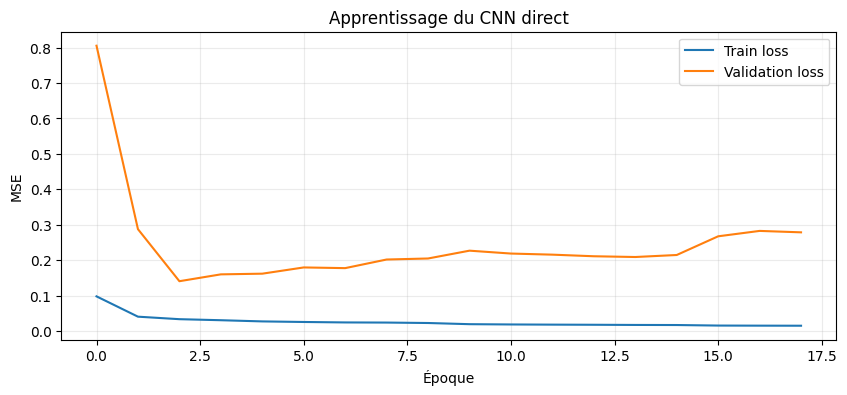

,time_index_in_test,y_true_original,y_pred_original
0,29,0.003941,0.003169
1,30,0.003941,0.003169
2,31,0.003604,0.003169
3,32,0.003604,0.003170
4,33,0.003604,0.003170


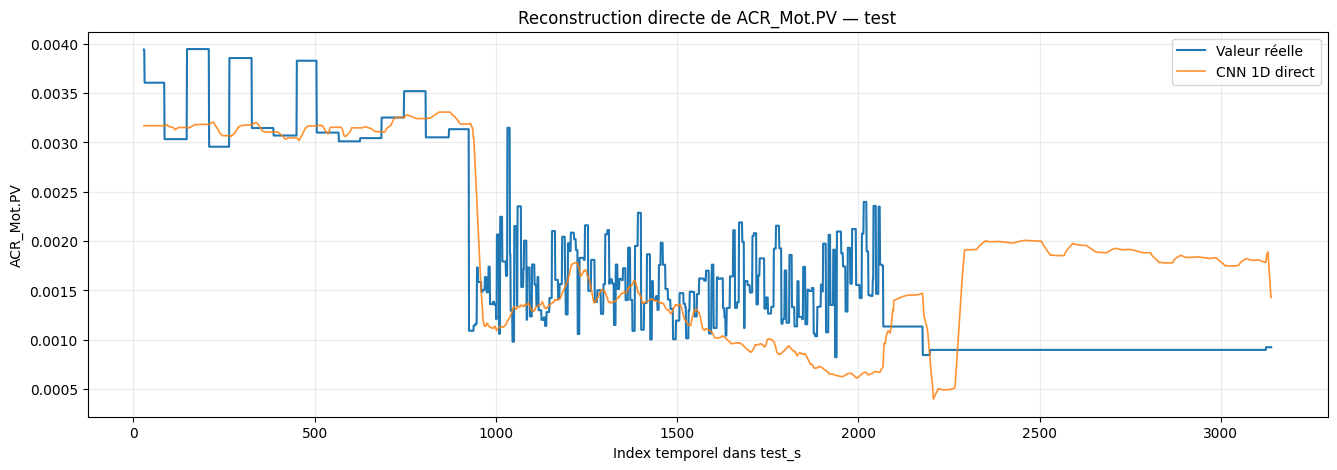

In [15]:
# ============================================================
# CNN 1D -> prédiction directe du capteur cible
# Sans lags explicites, SSI, SINDy ou XGBoost
#
# Prérequis :
# train_s, val_s, test_s, scaler
# TARGET_SENSOR, OBS_SSI_SENSORS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

# ------------------------------------------------------------
# 0. Paramètres
# ------------------------------------------------------------
SEED = 42

WINDOW = 30
CNN_EPOCHS = 150
CNN_BATCH_SIZE = 64
LEARNING_RATE = 1e-3

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ------------------------------------------------------------
# 1. Vérifications
# ------------------------------------------------------------
required_variables = [
    "train_s",
    "val_s",
    "test_s",
    "scaler",
    "TARGET_SENSOR",
    "OBS_SSI_SENSORS",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Variables manquantes : "
        + ", ".join(missing_variables)
    )

if TARGET_SENSOR in OBS_SSI_SENSORS:
    raise ValueError(
        f"{TARGET_SENSOR} ne doit pas être dans OBS_SSI_SENSORS."
    )

if (
    list(train_s.columns) != list(val_s.columns)
    or list(train_s.columns) != list(test_s.columns)
):
    raise ValueError(
        "train_s, val_s et test_s doivent avoir les mêmes colonnes."
    )

# ------------------------------------------------------------
# 2. Données
# ------------------------------------------------------------
X_train_obs = train_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
X_val_obs = val_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
X_test_obs = test_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)

y_train_full = train_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_val_full = val_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_test_full = test_s[TARGET_SENSOR].to_numpy(dtype=np.float32)

# ------------------------------------------------------------
# 3. Fenêtres temporelles strictement alignées
#
# Pour prédire y[t], le CNN reçoit :
# X[t-WINDOW+1], ..., X[t]
# ------------------------------------------------------------
def create_cnn_windows(
    observed_sensors,
    target,
    window,
):
    observed_sensors = np.asarray(
        observed_sensors,
        dtype=np.float32,
    )

    target = np.asarray(
        target,
        dtype=np.float32,
    )

    if len(observed_sensors) != len(target):
        raise ValueError(
            "observed_sensors et target doivent avoir la même longueur."
        )

    if len(target) < window:
        raise ValueError(
            f"Pas assez de lignes pour WINDOW={window}."
        )

    valid_t = np.arange(
        window - 1,
        len(target),
    )

    X_cnn = np.stack(
        [
            observed_sensors[
                t - window + 1:t + 1
            ]
            for t in valid_t
        ],
        axis=0,
    )

    y = target[valid_t]

    return X_cnn, y, valid_t


X_cnn_train, y_train, idx_train = create_cnn_windows(
    X_train_obs,
    y_train_full,
    WINDOW,
)

X_cnn_val, y_val, idx_val = create_cnn_windows(
    X_val_obs,
    y_val_full,
    WINDOW,
)

X_cnn_test, y_test, idx_test = create_cnn_windows(
    X_test_obs,
    y_test_full,
    WINDOW,
)

print("=" * 65)
print("DIMENSIONS")
print("=" * 65)
print("Train      :", X_cnn_train.shape, y_train.shape)
print("Validation :", X_cnn_val.shape, y_val.shape)
print("Test       :", X_cnn_test.shape, y_test.shape)

# ------------------------------------------------------------
# 4. CNN 1D direct
#
# GlobalAveragePooling conserve une architecture compacte,
# pour limiter le surapprentissage.
# ------------------------------------------------------------
n_observed_sensors = X_cnn_train.shape[-1]

cnn_input = tf.keras.Input(
    shape=(
        WINDOW,
        n_observed_sensors,
    ),
    name="observed_sensor_window",
)

x = tf.keras.layers.Conv1D(
    filters=32,
    kernel_size=3,
    padding="causal",
    activation="relu",
)(cnn_input)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Conv1D(
    filters=64,
    kernel_size=5,
    padding="causal",
    activation="relu",
)(x)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.GlobalAveragePooling1D()(x)

x = tf.keras.layers.Dense(
    32,
    activation="relu",
)(x)

cnn_output = tf.keras.layers.Dense(
    1,
    name="target_prediction",
)(x)

cnn_direct_model = tf.keras.Model(
    inputs=cnn_input,
    outputs=cnn_output,
    name="cnn_1d_direct_regression",
)

cnn_direct_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE,
    ),
    loss="mse",
    metrics=["mae"],
)

cnn_direct_model.summary()

# ------------------------------------------------------------
# 5. Entraînement
# ------------------------------------------------------------
cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=6,
        min_lr=1e-5,
        verbose=1,
    ),
]

history_cnn_direct = cnn_direct_model.fit(
    X_cnn_train,
    y_train,
    validation_data=(
        X_cnn_val,
        y_val,
    ),
    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH_SIZE,
    verbose=1,
    callbacks=cnn_callbacks,
    shuffle=True,
)

# ------------------------------------------------------------
# 6. Prédictions
# ------------------------------------------------------------
y_train_pred = cnn_direct_model.predict(
    X_cnn_train,
    verbose=0,
).ravel()

y_val_pred = cnn_direct_model.predict(
    X_cnn_val,
    verbose=0,
).ravel()

y_test_pred = cnn_direct_model.predict(
    X_cnn_test,
    verbose=0,
).ravel()

# ------------------------------------------------------------
# 7. Métriques
# ------------------------------------------------------------
def regression_metrics(
    y_true,
    y_pred,
    split_name,
):
    return {
        "split": split_name,
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "R2": r2_score(
            y_true,
            y_pred,
        ),
        "Correlation": np.corrcoef(
            y_true,
            y_pred,
        )[0, 1],
    }

metrics_scaled = pd.DataFrame([
    regression_metrics(
        y_train,
        y_train_pred,
        "Train",
    ),
    regression_metrics(
        y_val,
        y_val_pred,
        "Validation",
    ),
    regression_metrics(
        y_test,
        y_test_pred,
        "Test",
    ),
])

print("\nMétriques — espace standardisé :")
display(metrics_scaled)

# ------------------------------------------------------------
# 8. Retour à l'unité originale du capteur cible seulement
# ------------------------------------------------------------
TARGET_IDX = list(
    train_s.columns
).index(TARGET_SENSOR)

TARGET_MEAN = float(
    scaler.mean_[TARGET_IDX]
)

TARGET_SCALE = float(
    scaler.scale_[TARGET_IDX]
)

def inverse_target_scale(y_scaled):
    y_scaled = np.asarray(
        y_scaled,
        dtype=float,
    )

    return (
        y_scaled * TARGET_SCALE
        + TARGET_MEAN
    )

y_train_original = inverse_target_scale(y_train)
y_val_original = inverse_target_scale(y_val)
y_test_original = inverse_target_scale(y_test)

y_train_pred_original = inverse_target_scale(y_train_pred)
y_val_pred_original = inverse_target_scale(y_val_pred)
y_test_pred_original = inverse_target_scale(y_test_pred)

metrics_original = pd.DataFrame([
    regression_metrics(
        y_train_original,
        y_train_pred_original,
        "Train",
    ),
    regression_metrics(
        y_val_original,
        y_val_pred_original,
        "Validation",
    ),
    regression_metrics(
        y_test_original,
        y_test_pred_original,
        "Test",
    ),
])

print("\nMétriques — unité originale :")
display(metrics_original)

# ------------------------------------------------------------
# 9. Courbe de perte
# ------------------------------------------------------------
plt.figure(figsize=(10, 4))

plt.plot(
    history_cnn_direct.history["loss"],
    label="Train loss",
)

plt.plot(
    history_cnn_direct.history["val_loss"],
    label="Validation loss",
)

plt.title("Apprentissage du CNN direct")
plt.xlabel("Époque")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# ------------------------------------------------------------
# 10. Résultats test et graphe
# ------------------------------------------------------------
results_test_cnn_direct = pd.DataFrame({
    "time_index_in_test": idx_test,
    "y_true_original": y_test_original,
    "y_pred_original": y_test_pred_original,
})

display(results_test_cnn_direct.head())

plt.figure(figsize=(16, 5))

plt.plot(
    results_test_cnn_direct["time_index_in_test"],
    results_test_cnn_direct["y_true_original"],
    label="Valeur réelle",
    linewidth=1.5,
)

plt.plot(
    results_test_cnn_direct["time_index_in_test"],
    results_test_cnn_direct["y_pred_original"],
    label="CNN 1D direct",
    linewidth=1.2,
    alpha=0.85,
)

plt.title(
    f"Reconstruction directe de {TARGET_SENSOR} — test"
)

plt.xlabel("Index temporel dans test_s")
plt.ylabel(TARGET_SENSOR)

plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 8. SSI + SINDy + lags + XGBoost, alignement strict

Pourquoi : cette version vérifie soigneusement que chaque entrée correspond à la bonne cible temporelle. L'objectif est d'éviter qu'un décalage de lags donne un score artificiellement bon ou dégrade les amplitudes.


SINDy — APPRENTISSAGE SUR LES ÉTATS SSI OBSERVÉS
⚠️ SINDy : 223 états hors domaine. Max = 8.9025
⚠️ SINDy : 1239 états hors domaine. Max = 11.4278
⚠️ Dérivée SINDy élevée : max |dx/dt| = 14.9311
⚠️ SINDy : 223 états hors domaine. Max = 8.9025
⚠️ SINDy : 1239 états hors domaine. Max = 11.4278
⚠️ Dérivée SINDy élevée : max |dx/dt| = 14.9311

Dimensions SINDy avant construction :
Train : SSI=9396, Xdot=9396, Xnext=9396 → n_train=9396
Val   : SSI=3122, Xdot=3122, Xnext=3122 → n_val=3122
Test  : SSI=3126, Xdot=3126, Xnext=3126 → n_test=3126

Dimensions SSI + SINDy :
Train : (9396, 24)
Val   : (3122, 24)
Test  : (3126, 24)

AVANT MASQUE
Train X : (9396, 123) | y : (9396,)
Val X   : (3122, 123) | y : (3122,)
Test X  : (3126, 123) | y : (3126,)

ALIGNEMENT FINAL
Train X : (9386, 123) | Train y : (9386,)
Val X   : (3112, 123) | Val y   : (3112,)
Test X  : (3116, 123) | Test y : (3116,)

✓ Alignement X/y correct.
✓ Aucun NaN dans les features finales.
✓ Aucun problème de dimension.

XGBoost entr

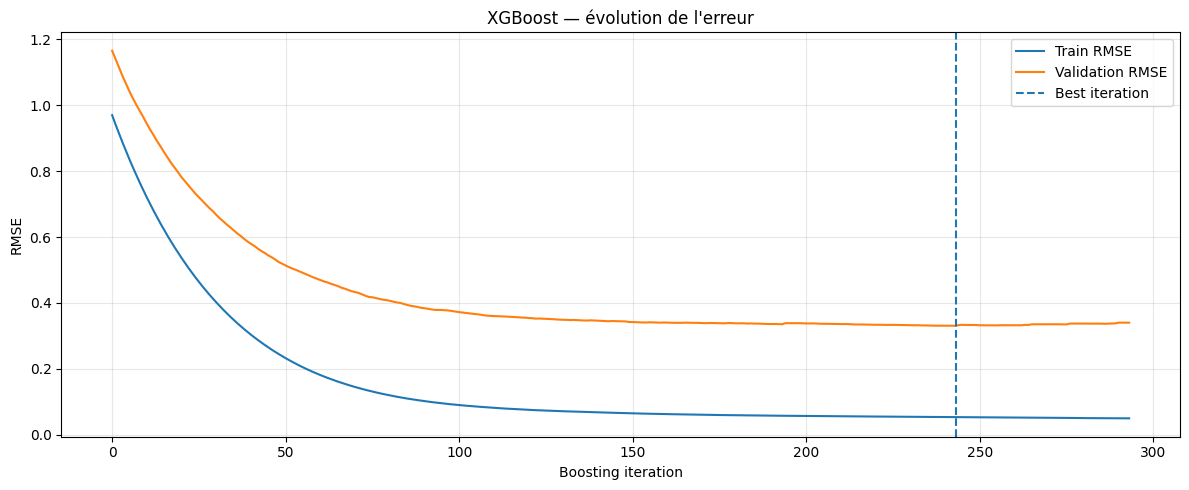

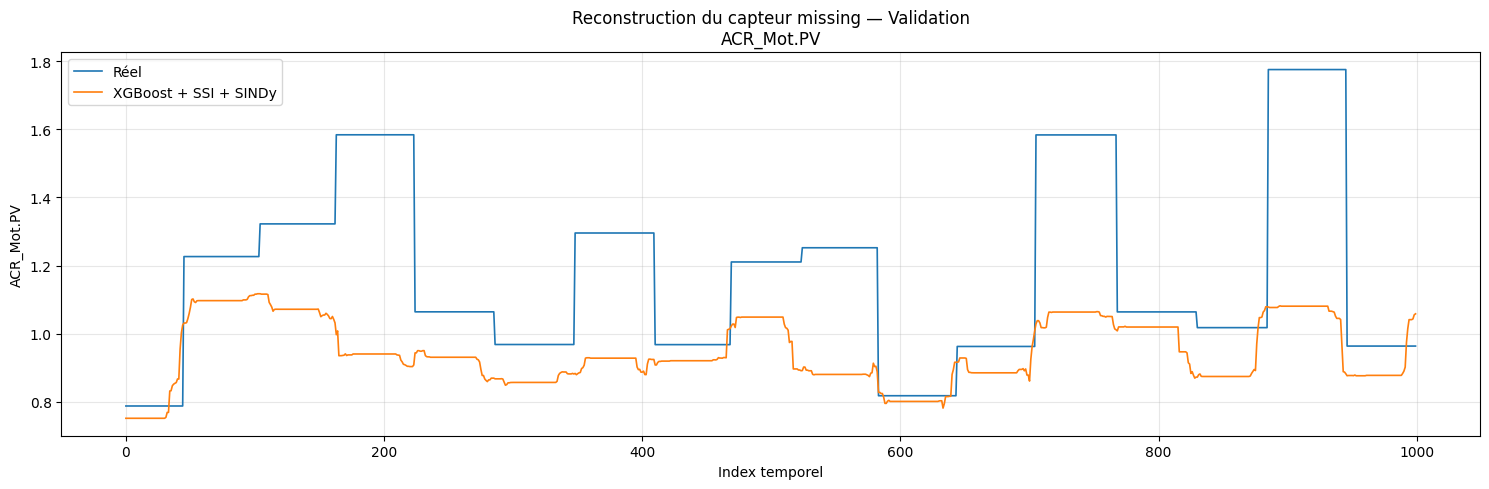

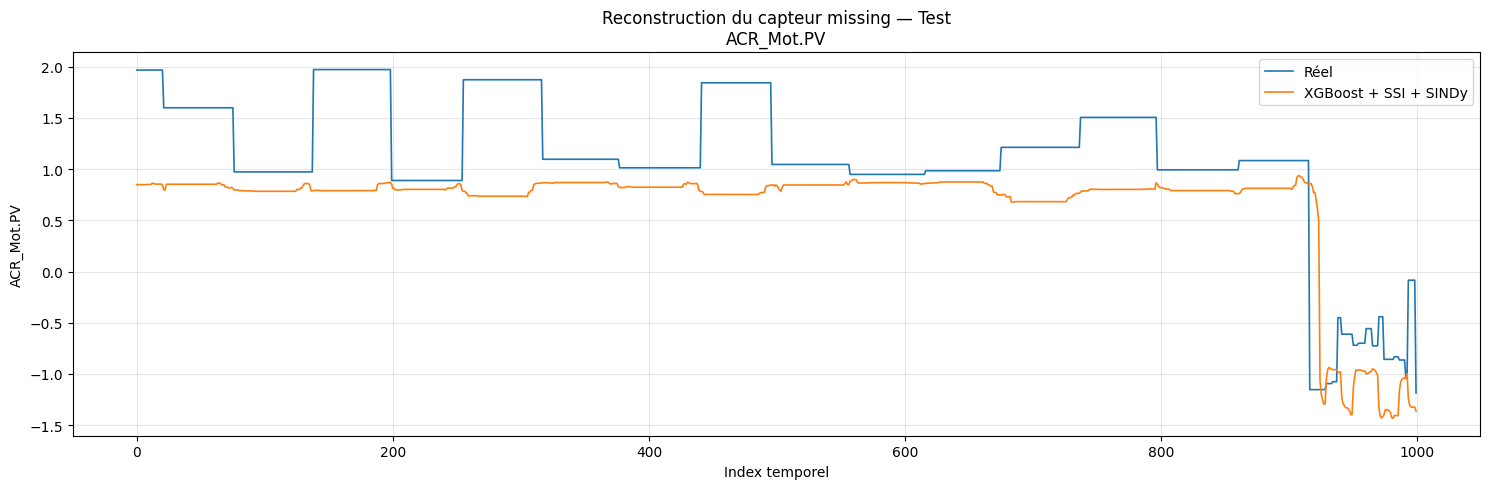

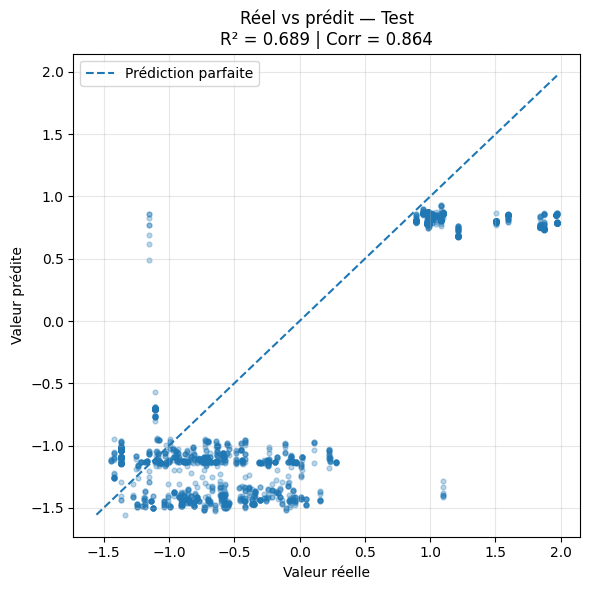

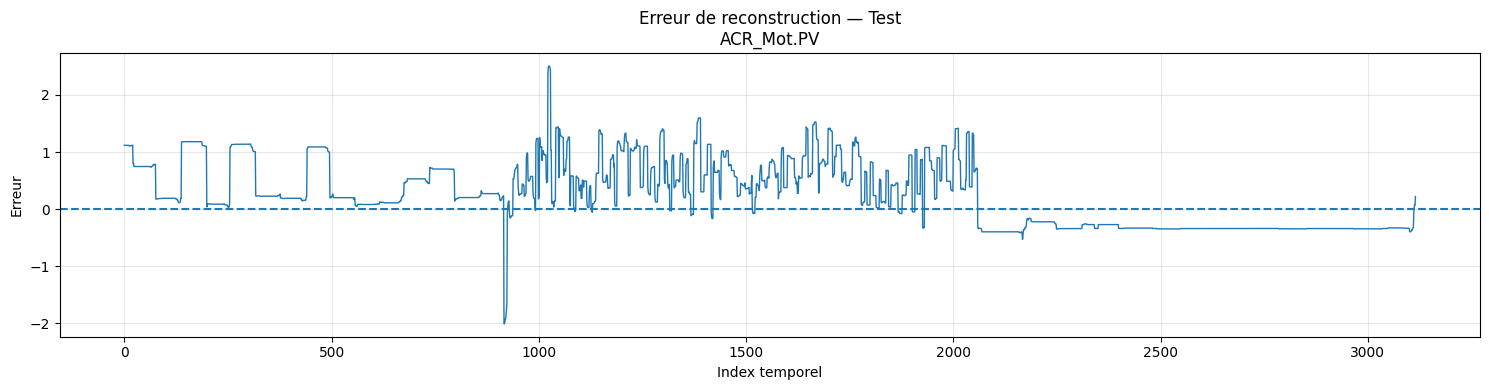

In [16]:
# ============================================================
# SSI → SINDy → LAGS → XGBoost
# VERSION ROBUSTE AVEC ALIGNEMENT STRICT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


# ============================================================
# 1. SINDy
# ============================================================
SINDY_POLY_DEGREES = [2, 3]

# Degré par défaut
SINDY_POLY_DEGREE = 3

# Régularisation Ridge
SINDY_ALPHA = 0.05

# Thresholds testés
SINDY_THRESHOLD_CANDIDATES = [
    0.001,
    0.005,
    0.01,
    0.02,
    0.05,
    0.1,
    0.2
]

# Fonctions trigonométriques
SINDY_INCLUDE_TRIG = False


# ============================================================
# 2. PARAMÈTRES DE STABILITÉ
# ============================================================

# Limite des états normalisés
SINDY_STATE_LIMIT = 5.0

# Nombre de points utilisés pour le test
# de simulation libre courte
SINDY_STABILITY_STEPS = 300


print("=" * 70)
print("SINDy — APPRENTISSAGE SUR LES ÉTATS SSI OBSERVÉS")
print("=" * 70)

sindy_model.fit(
    X_train_hat_obs,
    t=np.arange(len(X_train_hat_obs)) * DT_APPROX
)


# ============================================================
# 2. DYNAMIQUE SINDy
# ============================================================

Xdot_train_sindy = sindy_model.predict(
    X_train_hat_sindy
)

Xdot_val_sindy = sindy_model.predict(
    X_val_hat_sindy
)

Xdot_test_sindy = sindy_model.predict(
    X_test_hat_sindy
)


# ============================================================
# 3. PRÉDICTION ONE-STEP SINDy
# ============================================================

Xnext_train_sindy = sindy_model.predict_one_step(
    X_train_hat_sindy,
    DT_APPROX
)

Xnext_val_sindy = sindy_model.predict_one_step(
    X_val_hat_sindy,
    DT_APPROX
)

Xnext_test_sindy = sindy_model.predict_one_step(
    X_test_hat_sindy,
    DT_APPROX
)


# ============================================================
# 4. ALIGNEMENT STRICT SINDy
# ============================================================

n_train = min(
    len(X_train_hat_obs),
    len(Xdot_train_sindy),
    len(Xnext_train_sindy)
)

n_val = min(
    len(X_val_hat_obs),
    len(Xdot_val_sindy),
    len(Xnext_val_sindy)
)

n_test = min(
    len(X_test_hat_obs),
    len(Xdot_test_sindy),
    len(Xnext_test_sindy)
)


print("\nDimensions SINDy avant construction :")

print(
    f"Train : SSI={len(X_train_hat_obs)}, "
    f"Xdot={len(Xdot_train_sindy)}, "
    f"Xnext={len(Xnext_train_sindy)} "
    f"→ n_train={n_train}"
)

print(
    f"Val   : SSI={len(X_val_hat_obs)}, "
    f"Xdot={len(Xdot_val_sindy)}, "
    f"Xnext={len(Xnext_val_sindy)} "
    f"→ n_val={n_val}"
)

print(
    f"Test  : SSI={len(X_test_hat_obs)}, "
    f"Xdot={len(Xdot_test_sindy)}, "
    f"Xnext={len(Xnext_test_sindy)} "
    f"→ n_test={n_test}"
)


# ============================================================
# 5. FEATURES SSI + SINDy
# ============================================================

X_train_sindy_features = np.column_stack([
    X_train_hat_obs[:n_train],
    Xdot_train_sindy[:n_train],
    Xnext_train_sindy[:n_train]
])

X_val_sindy_features = np.column_stack([
    X_val_hat_obs[:n_val],
    Xdot_val_sindy[:n_val],
    Xnext_val_sindy[:n_val]
])

X_test_sindy_features = np.column_stack([
    X_test_hat_obs[:n_test],
    Xdot_test_sindy[:n_test],
    Xnext_test_sindy[:n_test]
])


print("\nDimensions SSI + SINDy :")

print(
    "Train :",
    X_train_sindy_features.shape
)

print(
    "Val   :",
    X_val_sindy_features.shape
)

print(
    "Test  :",
    X_test_sindy_features.shape
)


# ============================================================
# 6. LAGS
# ============================================================

N_LAGS = 10


def create_lag_features(
    df,
    sensor_columns,
    n_lags
):

    data = {}

    for sensor in sensor_columns:

        for lag in range(n_lags + 1):

            data[
                f"{sensor}_lag{lag}"
            ] = df[sensor].shift(lag)

    return pd.DataFrame(
        data,
        index=df.index
    )


X_train_lags = create_lag_features(
    train_s,
    OBS_SSI_SENSORS,
    N_LAGS
)

X_val_lags = create_lag_features(
    val_s,
    OBS_SSI_SENSORS,
    N_LAGS
)

X_test_lags = create_lag_features(
    test_s,
    OBS_SSI_SENSORS,
    N_LAGS
)


# ============================================================
# 7. ALIGNEMENT LAGS + SINDy
# ============================================================

X_train_lags = (
    X_train_lags
    .iloc[:n_train]
    .reset_index(drop=True)
)

X_val_lags = (
    X_val_lags
    .iloc[:n_val]
    .reset_index(drop=True)
)

X_test_lags = (
    X_test_lags
    .iloc[:n_test]
    .reset_index(drop=True)
)


X_train_sindy_df = pd.DataFrame(
    X_train_sindy_features
).reset_index(drop=True)

X_val_sindy_df = pd.DataFrame(
    X_val_sindy_features
).reset_index(drop=True)

X_test_sindy_df = pd.DataFrame(
    X_test_sindy_features
).reset_index(drop=True)


# ============================================================
# 8. CONSTRUCTION FEATURES HYBRIDES
# ============================================================

X_train_hybrid = pd.concat(
    [
        X_train_lags,
        X_train_sindy_df
    ],
    axis=1
)

X_val_hybrid = pd.concat(
    [
        X_val_lags,
        X_val_sindy_df
    ],
    axis=1
)

X_test_hybrid = pd.concat(
    [
        X_test_lags,
        X_test_sindy_df
    ],
    axis=1
)


# ============================================================
# 9. TARGETS
# ============================================================
#
# TRÈS IMPORTANT :
# les targets sont tronquées avec EXACTEMENT le même n_train
# utilisé pour construire X.
#

y_train_full = (
    train_s[TARGET_SENSOR]
    .iloc[:n_train]
    .reset_index(drop=True)
)

y_val_full = (
    val_s[TARGET_SENSOR]
    .iloc[:n_val]
    .reset_index(drop=True)
)

y_test_full = (
    test_s[TARGET_SENSOR]
    .iloc[:n_test]
    .reset_index(drop=True)
)


# ============================================================
# 10. VÉRIFICATION AVANT MASQUE
# ============================================================

print("\n" + "=" * 70)
print("AVANT MASQUE")
print("=" * 70)

print(
    "Train X :",
    X_train_hybrid.shape,
    "| y :",
    y_train_full.shape
)

print(
    "Val X   :",
    X_val_hybrid.shape,
    "| y :",
    y_val_full.shape
)

print(
    "Test X  :",
    X_test_hybrid.shape,
    "| y :",
    y_test_full.shape
)


assert len(X_train_hybrid) == len(y_train_full)
assert len(X_val_hybrid) == len(y_val_full)
assert len(X_test_hybrid) == len(y_test_full)


# ============================================================
# 11. MASQUES
# ============================================================

train_mask = (
    X_train_hybrid.notna().all(axis=1)
    &
    y_train_full.notna()
)

val_mask = (
    X_val_hybrid.notna().all(axis=1)
    &
    y_val_full.notna()
)

test_mask = (
    X_test_hybrid.notna().all(axis=1)
    &
    y_test_full.notna()
)


# ============================================================
# 12. APPLICATION DES MASQUES
# ============================================================

X_train_hybrid = (
    X_train_hybrid
    .loc[train_mask]
    .reset_index(drop=True)
)

X_val_hybrid = (
    X_val_hybrid
    .loc[val_mask]
    .reset_index(drop=True)
)

X_test_hybrid = (
    X_test_hybrid
    .loc[test_mask]
    .reset_index(drop=True)
)


y_train = (
    y_train_full
    .loc[train_mask]
    .reset_index(drop=True)
)

y_val = (
    y_val_full
    .loc[val_mask]
    .reset_index(drop=True)
)

y_test = (
    y_test_full
    .loc[test_mask]
    .reset_index(drop=True)
)


# ============================================================
# 13. VÉRIFICATION FINALE
# ============================================================

print("\n" + "=" * 70)
print("ALIGNEMENT FINAL")
print("=" * 70)

print(
    "Train X :",
    X_train_hybrid.shape,
    "| Train y :",
    y_train.shape
)

print(
    "Val X   :",
    X_val_hybrid.shape,
    "| Val y   :",
    y_val.shape
)

print(
    "Test X  :",
    X_test_hybrid.shape,
    "| Test y :",
    y_test.shape
)


assert len(X_train_hybrid) == len(y_train)
assert len(X_val_hybrid) == len(y_val)
assert len(X_test_hybrid) == len(y_test)

assert np.isfinite(
    X_train_hybrid.values
).all()

assert np.isfinite(
    X_val_hybrid.values
).all()

assert np.isfinite(
    X_test_hybrid.values
).all()


print("\n✓ Alignement X/y correct.")
print("✓ Aucun NaN dans les features finales.")
print("✓ Aucun problème de dimension.")


# ============================================================
# 14. XGBOOST
# ============================================================

XGB_PARAMS = {

    # Maximum de 1000 arbres
    "n_estimators": 1000,

    # Arbres peu profonds pour limiter le sur-apprentissage
    "max_depth": 3,

    # Learning rate faible
    "learning_rate": 0.03,

    # Sous-échantillonnage
    "subsample": 0.8,
    "colsample_bytree": 0.8,

    # Régularisation
    "min_child_weight": 3,
    "reg_alpha": 0.01,
    "reg_lambda": 1.0,

    "objective": "reg:squarederror",
    "eval_metric": "rmse",

    "random_state": 42,
    "n_jobs": -1,

    # Early stopping
    "early_stopping_rounds": 50
}


xgb_hybrid = XGBRegressor(
    **XGB_PARAMS
)


# ============================================================
# 15. ENTRAÎNEMENT
# ============================================================

xgb_hybrid.fit(
    X_train_hybrid,
    y_train,

    eval_set=[
        (X_train_hybrid, y_train),
        (X_val_hybrid, y_val)
    ],

    verbose=False
)


print("\n" + "=" * 70)
print("XGBoost entraîné")
print("=" * 70)

print(
    "Nombre d'arbres utilisés :",
    xgb_hybrid.best_iteration + 1
)

print(
    "Meilleur RMSE validation :",
    xgb_hybrid.best_score
)


# ============================================================
# 16. PRÉDICTIONS
# ============================================================

y_val_pred = xgb_hybrid.predict(
    X_val_hybrid
)

y_test_pred = xgb_hybrid.predict(
    X_test_hybrid
)


# ============================================================
# 17. ÉVALUATION
# ============================================================

def evaluate(
    y_true,
    y_pred,
    name
):

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    corr = np.corrcoef(
        y_true,
        y_pred
    )[0, 1]

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print(
        f"RMSE        = {rmse:.6f}"
    )

    print(
        f"MAE         = {mae:.6f}"
    )

    print(
        f"R²          = {r2:.6f}"
    )

    print(
        f"Corrélation = {corr:.6f}"
    )

    return {
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Correlation": corr
    }


results_val = evaluate(
    y_val,
    y_val_pred,
    "XGBoost + SSI + SINDy — Validation"
)


results_test = evaluate(
    y_test,
    y_test_pred,
    "XGBoost + SSI + SINDy — Test"
)


# ============================================================
# 18. COURBE D'APPRENTISSAGE XGBOOST
# ============================================================

evals_result = xgb_hybrid.evals_result()

train_rmse = evals_result["validation_0"]["rmse"]
val_rmse = evals_result["validation_1"]["rmse"]

plt.figure(
    figsize=(12, 5)
)

plt.plot(
    train_rmse,
    label="Train RMSE"
)

plt.plot(
    val_rmse,
    label="Validation RMSE"
)

plt.axvline(
    x=xgb_hybrid.best_iteration,
    linestyle="--",
    label="Best iteration"
)

plt.xlabel("Boosting iteration")
plt.ylabel("RMSE")

plt.title(
    "XGBoost — évolution de l'erreur"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 19. PLOT VALIDATION
# ============================================================

n_plot = min(
    1000,
    len(y_val)
)

plt.figure(
    figsize=(15, 5)
)

plt.plot(
    y_val.iloc[:n_plot].values,
    label="Réel",
    lw=1.2
)

plt.plot(
    y_val_pred[:n_plot],
    label="XGBoost + SSI + SINDy",
    lw=1.2
)

plt.title(
    f"Reconstruction du capteur missing — Validation\n"
    f"{TARGET_SENSOR}"
)

plt.xlabel(
    "Index temporel"
)

plt.ylabel(
    TARGET_SENSOR
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 20. PLOT TEST
# ============================================================

n_plot = min(
    1000,
    len(y_test)
)

plt.figure(
    figsize=(15, 5)
)

plt.plot(
    y_test.iloc[:n_plot].values,
    label="Réel",
    lw=1.2
)

plt.plot(
    y_test_pred[:n_plot],
    label="XGBoost + SSI + SINDy",
    lw=1.2
)

plt.title(
    f"Reconstruction du capteur missing — Test\n"
    f"{TARGET_SENSOR}"
)

plt.xlabel(
    "Index temporel"
)

plt.ylabel(
    TARGET_SENSOR
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 21. SCATTER RÉEL VS PRÉDIT
# ============================================================

plt.figure(
    figsize=(6, 6)
)

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.3,
    s=12
)

lims = [
    min(y_test.min(), y_test_pred.min()),
    max(y_test.max(), y_test_pred.max())
]

plt.plot(
    lims,
    lims,
    linestyle="--",
    label="Prédiction parfaite"
)

plt.xlabel(
    "Valeur réelle"
)

plt.ylabel(
    "Valeur prédite"
)

plt.title(
    f"Réel vs prédit — Test\n"
    f"R² = {results_test['R2']:.3f} | "
    f"Corr = {results_test['Correlation']:.3f}"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 22. ERREUR DE RECONSTRUCTION
# ============================================================

test_error = (
    y_test.values -
    y_test_pred
)

plt.figure(
    figsize=(15, 4)
)

plt.plot(
    test_error,
    lw=1
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Index temporel"
)

plt.ylabel(
    "Erreur"
)

plt.title(
    f"Erreur de reconstruction — Test\n"
    f"{TARGET_SENSOR}"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

## 9. CNN 1D + SSI + SINDy + lags + XGBoost

Pourquoi : c'est l'essai hybride le plus riche. Il combine les formes locales (CNN), les états communs (SSI), leur loi dynamique (SINDy) et les retards (lags). Son avantage potentiel est de capturer plusieurs facettes de la propagation ; son risque est de devenir trop complexe et de surapprendre.


ALIGNEMENT SSI
Train        | observations =   9410 | états SSI =   9396 | décalage = 14
Validation   | observations =   3136 | états SSI =   3122 | décalage = 14
Test         | observations =   3140 | états SSI =   3126 | décalage = 14

Décalage SSI retenu : 14
⚠️ SINDy : 54 états hors domaine. Max = 9.4771
⚠️ SINDy : 1222 états hors domaine. Max = 11.4019
⚠️ Dérivée SINDy élevée : max |dx/dt| = 14.7105

DIMENSIONS APRÈS ALIGNEMENT
CNN train   : (9381, 30, 9)
Lags train  : (9381, 99)
SSI train   : (9381, 8)
SINDy train : (9381, 8)
y train     : (9381,)
CNN val     : (3107, 30, 9)
CNN test    : (3111, 30, 9)
Epoch 1/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0593 - mae: 0.1545 - val_loss: 0.2065 - val_mae: 0.3623
Epoch 2/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0232 - mae: 0.1008 - val_loss: 0.2383 - val_mae: 0.3894
Epoch 3/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0192 - mae: 0.0913 - val_loss: 0.1741 - val_mae: 0.3232
Epoch 4/100
147/147 ━━━━━━━

,split,RMSE,MAE,R2,Correlation
0,Train,0.061023,0.037859,0.996278,0.998196
1,Validation,0.581656,0.478039,0.709279,0.931069
2,Test,0.834794,0.710249,0.425380,0.746943



Capteur cible : ACR_Mot.PV
TARGET_MEAN  : 0.00214400
TARGET_SCALE : 0.00091395

Métriques dans l'unité originale du capteur :


,split,RMSE,MAE,R2,Correlation
0,Train,0.000056,0.000035,0.996278,0.998196
1,Validation,0.000532,0.000437,0.709279,0.931069
2,Test,0.000763,0.000649,0.425381,0.746943



Aperçu des résultats test :


,time_index_in_test,y_true_scaled,y_pred_scaled,y_true_original,y_pred_original
0,29,1.965860,0.794586,0.003941,0.002870
1,30,1.965860,0.794586,0.003941,0.002870
2,31,1.597892,0.794586,0.003604,0.002870
3,32,1.597892,0.794586,0.003604,0.002870
4,33,1.597892,0.786389,0.003604,0.002863


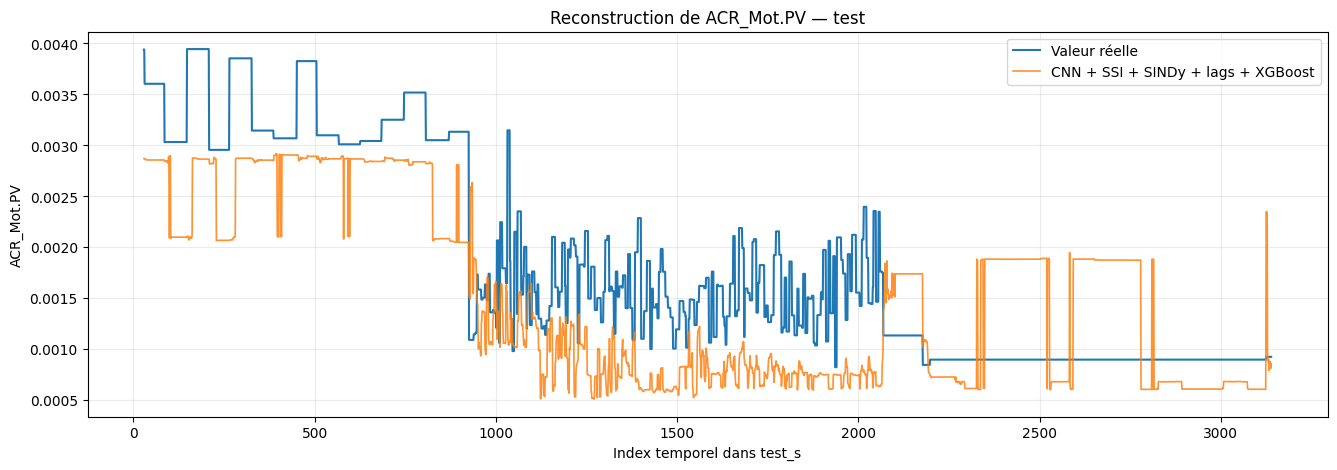

In [17]:
# ============================================================
# CNN 1D + SSI + SINDy + Lags -> XGBoost
# Reconstruction de TARGET_SENSOR sans l'utiliser en entrée
#
# Prérequis déjà définis dans le notebook :
# train_s, val_s, test_s, scaler
# TARGET_SENSOR, OBS_SSI_SENSORS
# SSI_BLOCK_ROWS, SSI_ORDER
# ssi_cov(), ssi_estimate_states()
# sindy_model
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor


# ============================================================
# 0. PARAMÈTRES
# ============================================================

SEED = 42

WINDOW = 30
N_LAGS = 10

CNN_EPOCHS = 100
CNN_BATCH_SIZE = 64
CNN_EMBEDDING_DIM = 32

# Si DT_APPROX existe déjà dans le notebook, SINDy l'utilise.
# Sinon, on considère dt = 1.
DT_SINDY = float(globals().get("DT_APPROX", 1.0))

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


# ============================================================
# 1. VÉRIFICATIONS
# ============================================================

required_variables = [
    "train_s",
    "val_s",
    "test_s",
    "scaler",
    "TARGET_SENSOR",
    "OBS_SSI_SENSORS",
    "SSI_BLOCK_ROWS",
    "SSI_ORDER",
    "ssi_cov",
    "ssi_estimate_states",
    "sindy_model",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Variables/fonctions manquantes : "
        + ", ".join(missing_variables)
    )

if TARGET_SENSOR in OBS_SSI_SENSORS:
    raise ValueError(
        f"{TARGET_SENSOR} ne doit pas être inclus dans OBS_SSI_SENSORS."
    )

if TARGET_SENSOR not in train_s.columns:
    raise ValueError(
        f"Le capteur cible {TARGET_SENSOR} est absent de train_s."
    )

if (
    list(train_s.columns) != list(val_s.columns)
    or list(train_s.columns) != list(test_s.columns)
):
    raise ValueError(
        "train_s, val_s et test_s doivent avoir les mêmes colonnes "
        "dans le même ordre."
    )


# ============================================================
# 2. DONNÉES OBSERVÉES ET CIBLE
# ============================================================

# Les entrées ne contiennent jamais TARGET_SENSOR.
Y_train_obs = train_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
Y_val_obs = val_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
Y_test_obs = test_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)

# Cible standardisée : elle est utilisée seulement comme y.
y_train_full = train_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_val_full = val_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_test_full = test_s[TARGET_SENSOR].to_numpy(dtype=np.float32)


# ============================================================
# 3. SSI : IDENTIFICATION SUR TRAIN UNIQUEMENT
# ============================================================

A_obs, C_obs, Sv_obs = ssi_cov(
    Y_train_obs,
    SSI_BLOCK_ROWS,
    SSI_ORDER,
)

X_train_hat_obs = ssi_estimate_states(
    Y_train_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS,
)

X_val_hat_obs = ssi_estimate_states(
    Y_val_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS,
)

X_test_hat_obs = ssi_estimate_states(
    Y_test_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS,
)

X_train_hat_obs = np.asarray(
    X_train_hat_obs,
    dtype=np.float32,
)

X_val_hat_obs = np.asarray(
    X_val_hat_obs,
    dtype=np.float32,
)

X_test_hat_obs = np.asarray(
    X_test_hat_obs,
    dtype=np.float32,
)


# ============================================================
# 4. DÉCALAGE TEMPOREL SSI
#
# Exemple :
# 9410 observations brutes
# 9396 états SSI
# offset = 14
#
# Alors :
# état SSI[k] <-> instant brut t = k + 14
# ============================================================

def get_ssi_offset(
    states,
    observations,
    split_name,
):
    offset = len(observations) - len(states)

    if offset < 0:
        raise ValueError(
            f"SSI renvoie trop d'états sur {split_name} : "
            f"{len(states)} états pour {len(observations)} observations."
        )

    print(
        f"{split_name:<12} | "
        f"observations = {len(observations):>6} | "
        f"états SSI = {len(states):>6} | "
        f"décalage = {offset}"
    )

    return offset


print("=" * 70)
print("ALIGNEMENT SSI")
print("=" * 70)

SSI_OFFSET_TRAIN = get_ssi_offset(
    X_train_hat_obs,
    Y_train_obs,
    "Train",
)

SSI_OFFSET_VAL = get_ssi_offset(
    X_val_hat_obs,
    Y_val_obs,
    "Validation",
)

SSI_OFFSET_TEST = get_ssi_offset(
    X_test_hat_obs,
    Y_test_obs,
    "Test",
)

if not (
    SSI_OFFSET_TRAIN
    == SSI_OFFSET_VAL
    == SSI_OFFSET_TEST
):
    raise ValueError(
        "Le décalage SSI doit être identique sur train, validation et test."
    )

SSI_OFFSET = SSI_OFFSET_TRAIN

print("\nDécalage SSI retenu :", SSI_OFFSET)


# ============================================================
# 5. SINDy
# ============================================================

# Standardisation des états SSI apprise uniquement sur train.
SINDY_SCALER = StandardScaler()

X_train_hat_sindy = SINDY_SCALER.fit_transform(
    X_train_hat_obs
)

X_val_hat_sindy = SINDY_SCALER.transform(
    X_val_hat_obs
)

X_test_hat_sindy = SINDY_SCALER.transform(
    X_test_hat_obs
)

# SINDy est entraîné uniquement sur les états SSI issus de train.
t_train_sindy = (
    np.arange(len(X_train_hat_sindy), dtype=float)
    * DT_SINDY
)

sindy_model.fit(
    X_train_hat_sindy,
    t=t_train_sindy,
)

# Features dynamiques SINDy : dérivées prédites dX/dt.
Xdot_train_sindy = sindy_model.predict(
    X_train_hat_sindy
)

Xdot_val_sindy = sindy_model.predict(
    X_val_hat_sindy
)

Xdot_test_sindy = sindy_model.predict(
    X_test_hat_sindy
)

Xdot_train_sindy = np.asarray(
    Xdot_train_sindy,
    dtype=np.float32,
)

Xdot_val_sindy = np.asarray(
    Xdot_val_sindy,
    dtype=np.float32,
)

Xdot_test_sindy = np.asarray(
    Xdot_test_sindy,
    dtype=np.float32,
)


# ============================================================
# 6. CONSTRUCTION DES ENTRÉES ALIGNÉES
#
# Pour chaque instant brut t :
#
# CNN   : observés[t-WINDOW+1 : t+1]
# Lags  : observés[t], ..., observés[t-N_LAGS]
# SSI   : états_SSI[t - SSI_OFFSET]
# SINDy : features_SINDy[t - SSI_OFFSET]
# y     : cible[t]
# ============================================================

def build_aligned_split(
    observed_sensors,
    ssi_states,
    sindy_features,
    target,
    window,
    n_lags,
    ssi_offset,
):
    observed_sensors = np.asarray(
        observed_sensors,
        dtype=np.float32,
    )

    ssi_states = np.asarray(
        ssi_states,
        dtype=np.float32,
    )

    '''sindy_features = np.asarray(
        sindy_features,
        dtype=np.float32,
    )

    target = np.asarray(
        target,
        dtype=np.float32,
    )'''

    n_raw = len(target)

    if len(observed_sensors) != n_raw:
        raise ValueError(
            "Les observations et la cible n'ont pas la même longueur."
        )

    if len(ssi_states) != len(sindy_features):
        raise ValueError(
            "Les états SSI et les features SINDy n'ont pas la même longueur."
        )

    if len(ssi_states) != n_raw - ssi_offset:
        raise ValueError(
            "Dimensions incompatibles entre les données brutes, "
            "les états SSI et SSI_OFFSET."
        )

    # Premier instant compatible avec :
    # - la fenêtre CNN ;
    # - les lags ;
    # - le premier état SSI disponible.
    first_t = max(
        window - 1,
        n_lags,
        ssi_offset,
    )

    if n_raw <= first_t:
        raise ValueError(
            f"Pas assez d'observations ({n_raw}) pour "
            f"WINDOW={window}, N_LAGS={n_lags} et "
            f"SSI_OFFSET={ssi_offset}."
        )

    # Instants dans les données brutes.
    valid_t = np.arange(
        first_t,
        n_raw,
    )

    # ----------------------------
    # Entrées CNN :
    # shape = (n_samples, WINDOW, n_sensors)
    # ----------------------------
    X_cnn = np.stack(
        [
            observed_sensors[
                t - window + 1:t + 1
            ]
            for t in valid_t
        ],
        axis=0,
    )

    # ----------------------------
    # Lags :
    # [x(t), x(t-1), ..., x(t-N_LAGS)]
    # ----------------------------
    X_lags = np.concatenate(
        [
            np.stack(
                [
                    observed_sensors[t - lag]
                    for t in valid_t
                ],
                axis=0,
            )
            for lag in range(n_lags + 1)
        ],
        axis=1,
    )

    # ----------------------------
    # Conversion temps brut -> index SSI/SINDy
    # ----------------------------
    ssi_indices = valid_t - ssi_offset

    X_ssi = ssi_states[ssi_indices]
    X_sindy = sindy_features[ssi_indices]

    # Cible au même instant t.
    y = target[valid_t]

    return (
        X_cnn,
        X_lags,
        X_ssi,
        X_sindy,
        y,
        valid_t,
    )


(
    X_cnn_train,
    X_lags_train,
    X_ssi_train,
    X_sindy_train,
    y_train,
    idx_train,
) = build_aligned_split(
    Y_train_obs,
    X_train_hat_obs,
    Xdot_train_sindy,
    y_train_full,
    WINDOW,
    N_LAGS,
    SSI_OFFSET,
)

(
    X_cnn_val,
    X_lags_val,
    X_ssi_val,
    X_sindy_val,
    y_val,
    idx_val,
) = build_aligned_split(
    Y_val_obs,
    X_val_hat_obs,
    Xdot_val_sindy,
    y_val_full,
    WINDOW,
    N_LAGS,
    SSI_OFFSET,
)

(
    X_cnn_test,
    X_lags_test,
    X_ssi_test,
    X_sindy_test,
    y_test,
    idx_test,
) = build_aligned_split(
    Y_test_obs,
    X_test_hat_obs,
    Xdot_test_sindy,
    y_test_full,
    WINDOW,
    N_LAGS,
    SSI_OFFSET,
)

print("\n" + "=" * 70)
print("DIMENSIONS APRÈS ALIGNEMENT")
print("=" * 70)
print("CNN train   :", X_cnn_train.shape)
print("Lags train  :", X_lags_train.shape)
print("SSI train   :", X_ssi_train.shape)
print("SINDy train :", X_sindy_train.shape)
print("y train     :", y_train.shape)
print("CNN val     :", X_cnn_val.shape)
print("CNN test    :", X_cnn_test.shape)


# ============================================================
# 7. CNN 1D LÉGER
# ============================================================

n_observed_sensors = X_cnn_train.shape[-1]

cnn_input = tf.keras.Input(
    shape=(WINDOW, n_observed_sensors),
    name="observed_sensor_window",
)

x = tf.keras.layers.Conv1D(
    filters=32,
    kernel_size=3,
    padding="causal",
    activation="relu",
)(cnn_input)

x = tf.keras.layers.Conv1D(
    filters=64,
    kernel_size=5,
    padding="causal",
    activation="relu",
)(x)

# Préserve l'information temporelle au lieu de moyenner la fenêtre.
x = tf.keras.layers.Flatten()(x)

x = tf.keras.layers.Dense(
    64,
    activation="relu",
)(x)

x = tf.keras.layers.Dense(
    CNN_EMBEDDING_DIM,
    activation="relu",
    name="cnn_embedding",
)(x)

cnn_output = tf.keras.layers.Dense(
    1,
    name="cnn_target_prediction",
)(x)

cnn_model = tf.keras.Model(
    inputs=cnn_input,
    outputs=cnn_output,
    name="lightweight_cnn_1d",
)

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="mse",
    metrics=["mae"],
)

cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
    )
]

history_cnn = cnn_model.fit(
    X_cnn_train,
    y_train,
    validation_data=(
        X_cnn_val,
        y_val,
    ),
    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH_SIZE,
    verbose=1,
    callbacks=cnn_callbacks,
    shuffle=True,
)


# ============================================================
# 8. EXTRACTION DES EMBEDDINGS CNN
# ============================================================

cnn_embedding_model = tf.keras.Model(
    inputs=cnn_model.input,
    outputs=cnn_model.get_layer(
        "cnn_embedding"
    ).output,
    name="cnn_embedding_extractor",
)

X_cnn_emb_train = cnn_embedding_model.predict(
    X_cnn_train,
    verbose=0,
)

X_cnn_emb_val = cnn_embedding_model.predict(
    X_cnn_val,
    verbose=0,
)

X_cnn_emb_test = cnn_embedding_model.predict(
    X_cnn_test,
    verbose=0,
)


# ============================================================
# 9. FUSION CNN + SSI + SINDy + LAGS
# ============================================================

X_train_final = np.hstack([
    X_cnn_emb_train,
    X_ssi_train,
    X_sindy_train,
    X_lags_train,
]).astype(np.float32)

X_val_final = np.hstack([
    X_cnn_emb_val,
    X_ssi_val,
    X_sindy_val,
    X_lags_val,
]).astype(np.float32)

X_test_final = np.hstack([
    X_cnn_emb_test,
    X_ssi_test,
    X_sindy_test,
    X_lags_test,
]).astype(np.float32)

print("\n" + "=" * 70)
print("DIMENSIONS FINALES XGBOOST")
print("=" * 70)
print("Train      :", X_train_final.shape)
print("Validation :", X_val_final.shape)
print("Test       :", X_test_final.shape)


# ============================================================
# 10. XGBOOST
# ============================================================

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.80,
    colsample_bytree=0.80,
    reg_alpha=0.01,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1,
    early_stopping_rounds=50,
)

xgb_model.fit(
    X_train_final,
    y_train,
    eval_set=[
        (
            X_val_final,
            y_val,
        )
    ],
    verbose=False,
)

# On ne remplace jamais y_test par les prédictions.
y_train_pred = xgb_model.predict(
    X_train_final
)

y_val_pred = xgb_model.predict(
    X_val_final
)

y_test_pred = xgb_model.predict(
    X_test_final
)


# ============================================================
# 11. MÉTRIQUES
# ============================================================

def regression_metrics(
    y_true,
    y_pred,
    split_name,
):
    correlation = np.corrcoef(
        y_true,
        y_pred,
    )[0, 1]

    return {
        "split": split_name,
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "R2": r2_score(
            y_true,
            y_pred,
        ),
        "Correlation": correlation,
    }


metrics_scaled = pd.DataFrame([
    regression_metrics(
        y_train,
        y_train_pred,
        "Train",
    ),
    regression_metrics(
        y_val,
        y_val_pred,
        "Validation",
    ),
    regression_metrics(
        y_test,
        y_test_pred,
        "Test",
    ),
])

print("\nMétriques dans l'espace standardisé :")
display(metrics_scaled)


# ============================================================
# 12. RETOUR À L'UNITÉ ORIGINALE DU CAPTEUR CIBLE
#
# Le scaler contient les paramètres des 10 capteurs.
# Il ne faut donc PAS appeler :
# scaler.inverse_transform(y.reshape(-1, 1))
# ============================================================

target_index = list(
    train_s.columns
).index(TARGET_SENSOR)

TARGET_MEAN = float(
    scaler.mean_[target_index]
)

TARGET_SCALE = float(
    scaler.scale_[target_index]
)

def inverse_target_scale(y_scaled):
    y_scaled = np.asarray(
        y_scaled,
        dtype=float,
    )

    return (
        y_scaled * TARGET_SCALE
        + TARGET_MEAN
    )


y_train_original = inverse_target_scale(
    y_train
)

y_val_original = inverse_target_scale(
    y_val
)

y_test_original = inverse_target_scale(
    y_test
)

y_train_pred_original = inverse_target_scale(
    y_train_pred
)

y_val_pred_original = inverse_target_scale(
    y_val_pred
)

y_test_pred_original = inverse_target_scale(
    y_test_pred
)

metrics_original = pd.DataFrame([
    regression_metrics(
        y_train_original,
        y_train_pred_original,
        "Train",
    ),
    regression_metrics(
        y_val_original,
        y_val_pred_original,
        "Validation",
    ),
    regression_metrics(
        y_test_original,
        y_test_pred_original,
        "Test",
    ),
])

print(f"\nCapteur cible : {TARGET_SENSOR}")
print(f"TARGET_MEAN  : {TARGET_MEAN:.8f}")
print(f"TARGET_SCALE : {TARGET_SCALE:.8f}")

print("\nMétriques dans l'unité originale du capteur :")
display(metrics_original)


# ============================================================
# 13. RÉSULTATS TEST ET VISUALISATION
# ============================================================

results_test = pd.DataFrame({
    "time_index_in_test": idx_test,
    "y_true_scaled": y_test,
    "y_pred_scaled": y_test_pred,
    "y_true_original": y_test_original,
    "y_pred_original": y_test_pred_original,
})

print("\nAperçu des résultats test :")
display(results_test.head())

plt.figure(figsize=(16, 5))

plt.plot(
    results_test["time_index_in_test"],
    results_test["y_true_original"],
    label="Valeur réelle",
    linewidth=1.5,
)

plt.plot(
    results_test["time_index_in_test"],
    results_test["y_pred_original"],
    label="CNN + SSI + SINDy + lags + XGBoost",
    linewidth=1.2,
    alpha=0.85,
)

plt.title(
    f"Reconstruction de {TARGET_SENSOR} — test"
)

plt.xlabel("Index temporel dans test_s")
plt.ylabel(TARGET_SENSOR)

plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 10. Benchmark XGBoost : instantané, contexte, résidu et amplitude

Ces modèles isolent les sources possibles d'amélioration : relation immédiate, mémoire temporelle, correction des erreurs et correction de l'échelle. Ils reprennent toutes les évaluations et graphiques du bloc final original.


# Reconstruction du capteur cible — benchmark XGBoost propre

Cette partie remplace les anciens essais XGBoost du notebook. Elle ne modifie ni les données, ni le split chronologique, ni les baselines SSI/SINDy existantes. Les modèles n'utilisent que les capteurs disponibles au moment de la panne.


## 1. Configuration

Les réglages ci-dessous sont volontairement compacts et reproductibles. La validation reste chronologique : Train → Validation → Test.


In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from scipy.signal import find_peaks
from scipy.stats import pearsonr
try:
    from xgboost import XGBRegressor
except ImportError as exc:
    raise ImportError("XGBoost est requis. Installez-le dans l'environnement du notebook avec `%pip install xgboost`.") from exc

XGB_GRID = [
    dict(n_estimators=250, max_depth=2, learning_rate=.04, min_child_weight=3, subsample=.85, colsample_bytree=.85),
    dict(n_estimators=350, max_depth=3, learning_rate=.03, min_child_weight=5, subsample=.85, colsample_bytree=.90),
    dict(n_estimators=450, max_depth=4, learning_rate=.025, min_child_weight=7, subsample=.90, colsample_bytree=1.0),
]
TEMPORAL_LAGS = (1, 2, 3, 6, 12)
ROLLING_WINDOWS = (5, 15, 30)
SCENARIO_FRACTIONS = (0.10, 0.20, 0.30)
SCORE_WEIGHTS = dict(Normalized_RMSE=.40, Correlation=.20, Std_ratio=.20, Amplitude_ratio=.20)


## 2. Préparation des modèles et génération des features

Le modèle instantané voit les autres capteurs à l'instant t. Le modèle contextuel ajoute seulement leur historique; les statistiques glissantes sont décalées d'un pas, afin qu'aucune information future ne soit utilisée.


In [19]:
def make_features(other_sensors, temporal=False):
    other_sensors = other_sensors.astype(float).copy()
    features = {f"current__{c}": other_sensors[c] for c in other_sensors.columns}
    if temporal:
        for c in other_sensors.columns:
            previous = other_sensors[c].shift(1)
            for lag in TEMPORAL_LAGS:
                features[f"{c}__lag_{lag}"] = other_sensors[c].shift(lag)
            features[f"{c}__delta_1"] = other_sensors[c] - previous
            features[f"{c}__delta_2"] = other_sensors[c] - 2 * previous + other_sensors[c].shift(2)
            for window in ROLLING_WINDOWS:
                rolling = previous.rolling(window, min_periods=window)
                features[f"{c}__rolling_mean_{window}"] = rolling.mean()
                features[f"{c}__rolling_std_{window}"] = rolling.std()
                features[f"{c}__rolling_min_{window}"] = rolling.min()
                features[f"{c}__rolling_max_{window}"] = rolling.max()
    return pd.DataFrame(features).replace([np.inf, -np.inf], np.nan).bfill().fillna(0.0)

def split_features(history, current, temporal):
    combined = pd.concat([history, current], ignore_index=True)
    return make_features(combined, temporal=temporal).iloc[len(history):].reset_index(drop=True)

history_size = max(max(TEMPORAL_LAGS), max(ROLLING_WINDOWS))
other_train = train_s[selected_sensors].reset_index(drop=True)
other_val = val_s[selected_sensors].reset_index(drop=True)
other_test = test_s[selected_sensors].reset_index(drop=True)

def build_split_features(temporal):
    train_x = split_features(other_train.iloc[:0], other_train, temporal)
    val_x = split_features(other_train.tail(history_size), other_val, temporal)
    test_history = pd.concat([other_train, other_val], ignore_index=True).tail(history_size)
    test_x = split_features(test_history, other_test, temporal)
    return train_x, val_x, test_x

X_instant_train, X_instant_val, X_instant_test = build_split_features(temporal=False)
X_context_train, X_context_val, X_context_test = build_split_features(temporal=True)
y_train_xgb = train_s[TARGET_SENSOR].to_numpy()
y_val_xgb = val_s[TARGET_SENSOR].to_numpy()
y_test_xgb = test_s[TARGET_SENSOR].to_numpy()
assert len(X_context_test) == len(y_test_xgb) and X_context_test.index.equals(pd.RangeIndex(len(y_test_xgb)))


## 3. XGBoost instantané et 4. XGBoost contexte temporel

Les hyperparamètres sont sélectionnés uniquement sur la validation chronologique. Après ce choix, le modèle final est entraîné sur Train + Validation, jamais sur Test.


In [20]:
def select_and_fit_xgb(X_train, y_train, X_val, y_val, label):
    trials = []
    for params in XGB_GRID:
        model = XGBRegressor(**params, objective="reg:squarederror", random_state=RANDOM_SEED, n_jobs=1, verbosity=0)
        model.fit(X_train, y_train)
        trials.append((np.sqrt(mean_squared_error(y_val, model.predict(X_val))), params))
    validation_rmse, chosen = min(trials, key=lambda item: item[0])
    final_model = XGBRegressor(**chosen, objective="reg:squarederror", random_state=RANDOM_SEED, n_jobs=1, verbosity=0)
    final_model.fit(pd.concat([X_train, X_val], ignore_index=True), np.r_[y_train, y_val])
    print(f"{label} — RMSE validation: {validation_rmse:.5f}; paramètres: {chosen}")
    return final_model, chosen

xgb_instant, params_instant = select_and_fit_xgb(X_instant_train, y_train_xgb, X_instant_val, y_val_xgb, "XGBoost instantané")
xgb_context, params_context = select_and_fit_xgb(X_context_train, y_train_xgb, X_context_val, y_val_xgb, "XGBoost contexte")
pred_instant = xgb_instant.predict(X_instant_test)
pred_context = xgb_context.predict(X_context_test)


XGBoost instantané — RMSE validation: 0.46894; paramètres: {'n_estimators': 450, 'max_depth': 4, 'learning_rate': 0.025, 'min_child_weight': 7, 'subsample': 0.9, 'colsample_bytree': 1.0}
XGBoost contexte — RMSE validation: 0.43500; paramètres: {'n_estimators': 350, 'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 5, 'subsample': 0.85, 'colsample_bytree': 0.9}


## 5. XGBoost résiduel

Le second modèle apprend l'erreur restante du modèle contextuel. Les résidus d'apprentissage proviennent de prédictions walk-forward : chaque résidu est calculé avec une prédiction faite sans observer sa cible. Pendant le test, la reconstruction est uniquement baseline + résidu prédit.


In [21]:
def walk_forward_predictions(params, X, y, folds=4):
    prediction = np.full(len(y), np.nan)
    boundaries = np.linspace(max(40, len(y) // 5), len(y), folds + 1, dtype=int)
    for start, end in zip(boundaries[:-1], boundaries[1:]):
        model = XGBRegressor(**params, objective="reg:squarederror", random_state=RANDOM_SEED, n_jobs=1, verbosity=0)
        model.fit(X.iloc[:start], y[:start])
        prediction[start:end] = model.predict(X.iloc[start:end])
    return prediction

oof_context_train = walk_forward_predictions(params_context, X_context_train, y_train_xgb)
valid_oof = np.isfinite(oof_context_train)
residual_train = y_train_xgb[valid_oof] - oof_context_train[valid_oof]

# Validation résiduelle : baseline entraînée sur Train seulement, donc sans fuite.
context_train_only = XGBRegressor(**params_context, objective="reg:squarederror", random_state=RANDOM_SEED, n_jobs=1, verbosity=0).fit(X_context_train, y_train_xgb)
baseline_val = context_train_only.predict(X_context_val)
residual_val = y_val_xgb - baseline_val
xgb_residual, params_residual = select_and_fit_xgb(X_context_train.iloc[valid_oof].reset_index(drop=True), residual_train, X_context_val, residual_val, "XGBoost résiduel")
pred_residual = pred_context + xgb_residual.predict(X_context_test)


XGBoost résiduel — RMSE validation: 0.69940; paramètres: {'n_estimators': 250, 'max_depth': 2, 'learning_rate': 0.04, 'min_child_weight': 3, 'subsample': 0.85, 'colsample_bytree': 0.85}


## 6. Calibration d'amplitude (option expérimentale)

La calibration affine ne sert pas à normaliser artificiellement le Test. Elle est ajustée sur des prédictions walk-forward de Train + Validation puis appliquée telle quelle au Test. La version brute est toujours conservée dans le benchmark.


In [22]:
X_context_train_val = pd.concat([X_context_train, X_context_val], ignore_index=True)
y_train_val = np.r_[y_train_xgb, y_val_xgb]
oof_train_val = walk_forward_predictions(params_context, X_context_train_val, y_train_val)
calibration_ok = np.isfinite(oof_train_val)
amplitude_calibrator = LinearRegression().fit(oof_train_val[calibration_ok, None], y_train_val[calibration_ok])
pred_context_calibrated = amplitude_calibrator.predict(pred_context[:, None])
print(f"Calibration contextuelle: y = {amplitude_calibrator.coef_[0]:.4f} × prediction + {amplitude_calibrator.intercept_:.4f}")


Calibration contextuelle: y = 1.0859 × prediction + -0.2708


## 7. Scénarios de données manquantes et 8. Évaluation

Une unique fonction `evaluate_model` produit les métriques pour tous les scénarios. Les pics du Test servent uniquement à définir un scénario artificiel d'évaluation, jamais à entraîner ou calibrer les modèles.


In [23]:
def inverse_target(values):
    return np.asarray(values) * scaler.scale_[target_idx] + scaler.mean_[target_idx]

def evaluate_model(y_true, y_pred, mask, method, scenario):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    assert len(y_true) == len(y_pred) == len(mask), "Longueurs incohérentes"
    assert mask.dtype == bool and mask.any(), "Masque d'évaluation invalide"
    true, pred = y_true[mask], y_pred[mask]
    assert np.isfinite(true).all() and np.isfinite(pred).all(), "NaN/Inf détecté"
    peak_prominence = max(np.std(true) * .75, 1e-12)
    true_peaks, _ = find_peaks(true, prominence=peak_prominence)
    pred_peaks, _ = find_peaks(pred, prominence=peak_prominence)
    tolerance = max(2, len(true) // 100); used = set(); matched = []
    for peak in true_peaks:
        candidates = [p for p in pred_peaks if abs(p - peak) <= tolerance and p not in used]
        if candidates:
            detected = min(candidates, key=lambda p: abs(p - peak)); used.add(detected); matched.append((peak, detected))
    variance_ratio = np.var(pred) / np.var(true) if np.var(true) else np.nan
    std_ratio = np.std(pred) / np.std(true) if np.std(true) else np.nan
    amplitude_ratio = np.ptp(pred) / np.ptp(true) if np.ptp(true) else np.nan
    return dict(Method=method, Scenario=scenario, N_total=len(y_true), N_missing=int(mask.sum()), MAE=mean_absolute_error(true, pred), RMSE=np.sqrt(mean_squared_error(true, pred)), Normalized_RMSE=np.sqrt(mean_squared_error(true, pred))/np.std(true) if np.std(true) else np.nan, R2=r2_score(true, pred), Correlation=pearsonr(true, pred)[0] if np.std(true) and np.std(pred) else np.nan, Variance_ratio=variance_ratio, Std_ratio=std_ratio, Amplitude_ratio=amplitude_ratio, Peak_MAE=np.mean([abs(true[a]-pred[b]) for a,b in matched]) if matched else np.nan, Peak_RMSE=np.sqrt(np.mean((true[true_peaks]-pred[true_peaks])**2)) if len(true_peaks) else np.nan, Peak_amplitude_error=np.mean([abs(true[a]-pred[b]) for a,b in matched]) if matched else np.nan, Peak_detection_rate=len(matched)/len(true_peaks) if len(true_peaks) else np.nan)

y_test_physical = inverse_target(y_test_xgb)
predictions = {"XGBoost instantané": inverse_target(pred_instant), "XGBoost contexte": inverse_target(pred_context), "XGBoost contexte calibré": inverse_target(pred_context_calibrated), "XGBoost contexte + résidu": inverse_target(pred_residual)}
rng = np.random.default_rng(RANDOM_SEED); scenarios = {"Random 10%": rng.random(len(y_test_physical)) < RANDOM_MISSING_FRACTION}
for fraction in SCENARIO_FRACTIONS:
    length = max(5, int(len(y_test_physical) * fraction)); start = (len(y_test_physical) - length) // 2
    mask = np.zeros(len(y_test_physical), dtype=bool); mask[start:start+length] = True; scenarios[f"Continuous {int(fraction*100)}%"] = mask
peaks, _ = find_peaks(y_test_physical, prominence=max(np.std(y_test_physical), 1e-12)); peak_mask = np.zeros(len(y_test_physical), dtype=bool)
for peak in peaks: peak_mask[max(0, peak-PEAK_WINDOW_HALF_WIDTH):min(len(peak_mask), peak+PEAK_WINDOW_HALF_WIDTH+1)] = True
scenarios["Peak-focused"] = peak_mask
print({name: f"{int(mask.sum())}/{len(mask)} points" for name, mask in scenarios.items()})


{'Random 10%': '306/3140 points', 'Continuous 10%': '314/3140 points', 'Continuous 20%': '628/3140 points', 'Continuous 30%': '942/3140 points', 'Peak-focused': '246/3140 points'}


## 9. Visualisation

Les quatre méthodes sont comparées sur exactement la même fenêtre continue de 20 %, avec une échelle verticale commune. Les deux graphiques ciblent la forme globale et les pics/transitoires.


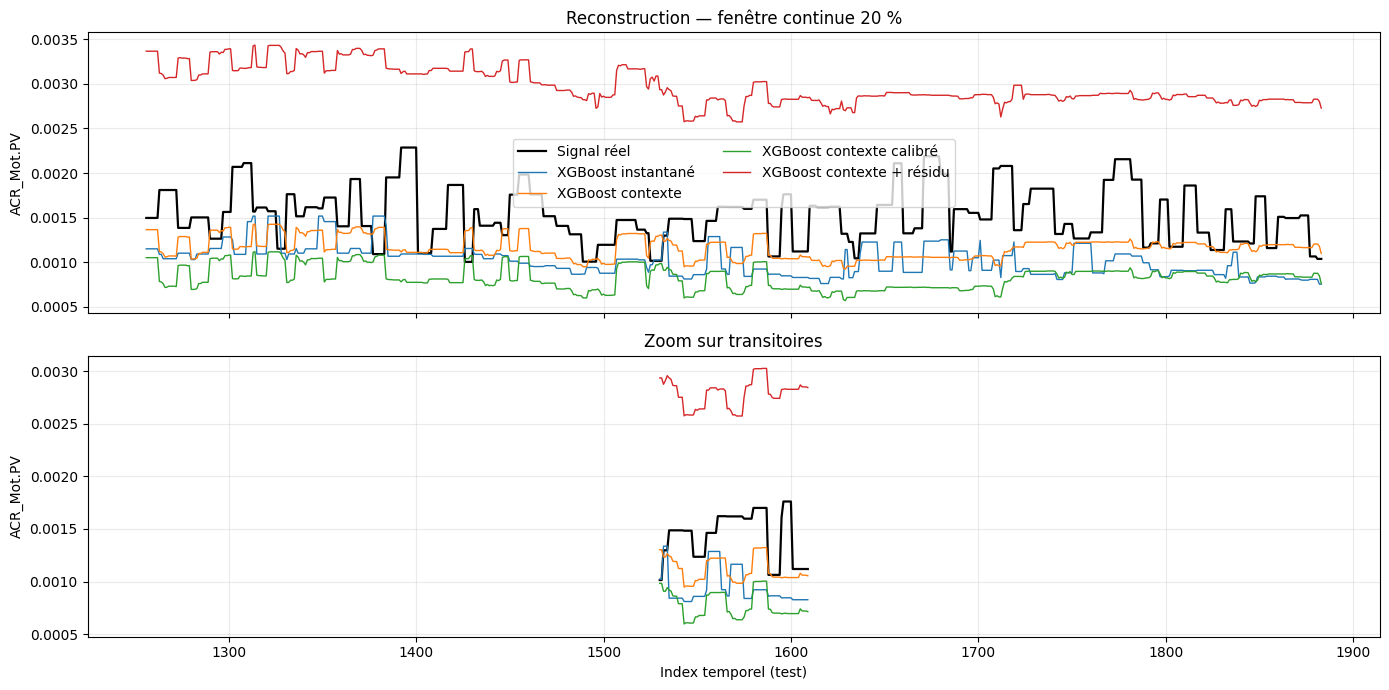

In [24]:
evaluation_rows = [evaluate_model(y_test_physical, prediction, mask, method, scenario) for scenario, mask in scenarios.items() for method, prediction in predictions.items()]
results_all_xgb = pd.DataFrame(evaluation_rows)
main_scenario = "Continuous 20%"; main_mask = scenarios[main_scenario]; idx = np.flatnonzero(main_mask)
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(idx, y_test_physical[main_mask], color="black", lw=1.6, label="Signal réel")
for name, prediction in predictions.items(): axes[0].plot(idx, prediction[main_mask], lw=1.0, label=name)
axes[0].set(title="Reconstruction — fenêtre continue 20 %", ylabel=TARGET_SENSOR); axes[0].legend(ncol=2); axes[0].grid(alpha=.25)
zoom = slice(max(0, len(idx)//2-40), min(len(idx), len(idx)//2+40)); zoom_idx = idx[zoom]
axes[1].plot(zoom_idx, y_test_physical[zoom_idx], color="black", lw=1.6, label="Signal réel")
for name, prediction in predictions.items(): axes[1].plot(zoom_idx, prediction[zoom_idx], lw=1.0, label=name)
axes[1].set(title="Zoom sur transitoires", xlabel="Index temporel (test)", ylabel=TARGET_SENSOR); axes[1].grid(alpha=.25)
plt.tight_layout(); plt.show()


## 10. Comparaison des méthodes

`results_xgb` est le tableau final sur la fenêtre principale. Le score est paramétrable et combine erreur normalisée, corrélation, réalisme de l'écart-type et réalisme de l'amplitude ; les métriques individuelles restent visibles.


Score=w1​RMSEnorm​+w2​∣1−Corr∣+w3​∣1−StdRatio∣+w4​∣1−AmpRatio∣

In [25]:
# ============================================================
# DIAGNOSTIC DES MÉTRIQUES NON FINIES
# ============================================================

results_xgb = (
    results_all_xgb
    .query("Scenario == @main_scenario")
    .copy()
)

# Calcul du score
results_xgb["Selection_score"] = (
    SCORE_WEIGHTS["Normalized_RMSE"]
    * results_xgb["Normalized_RMSE"]
    +
    SCORE_WEIGHTS["Correlation"]
    * (1 - results_xgb["Correlation"]).abs()
    +
    SCORE_WEIGHTS["Std_ratio"]
    * (1 - results_xgb["Std_ratio"]).abs()
    +
    SCORE_WEIGHTS["Amplitude_ratio"]
    * (1 - results_xgb["Amplitude_ratio"]).abs()
)

# ------------------------------------------------------------
# Recherche des valeurs non finies
# ------------------------------------------------------------

numeric_cols = results_xgb.select_dtypes(
    include=np.number
).columns

non_finite_mask = ~np.isfinite(
    results_xgb[numeric_cols]
)

# Colonnes concernées
bad_columns = [
    col
    for col in numeric_cols
    if non_finite_mask[col].any()
]

print("Colonnes contenant des valeurs non finies :")
print(bad_columns)

# Lignes concernées
bad_rows = results_xgb.loc[
    non_finite_mask.any(axis=1)
]

print("\nLignes concernées :")
display(bad_rows)

Colonnes contenant des valeurs non finies :
[]

Lignes concernées :


,Method,Scenario,N_total,N_missing,MAE,RMSE,Normalized_RMSE,R2,Correlation,Variance_ratio,Std_ratio,Amplitude_ratio,Peak_MAE,Peak_RMSE,Peak_amplitude_error,Peak_detection_rate,Selection_score


*Calibration step*

In [26]:
def with_base_prediction(features, base_prediction):
    result = features.reset_index(drop=True).copy()
    result["baseline_context_prediction"] = np.asarray(base_prediction)
    return result

# Les prédictions walk-forward du modèle de contexte évitent que les cibles utilisées
# pour apprendre les corrections aient été vues par le modèle de base correspondant.
oof_context_train = walk_forward_predictions(params_context, X_context_train, y_train_xgb)
valid_oof_context = np.isfinite(oof_context_train)
baseline_train_only = XGBRegressor(**params_context, objective="reg:squarederror", random_state=RANDOM_SEED, n_jobs=1, verbosity=0).fit(X_context_train, y_train_xgb)
baseline_val_from_train = baseline_train_only.predict(X_context_val)

X_correction_train = with_base_prediction(X_context_train.iloc[valid_oof_context], oof_context_train[valid_oof_context])
X_correction_val = with_base_prediction(X_context_val, baseline_val_from_train)
residual_train_oof = y_train_xgb[valid_oof_context] - oof_context_train[valid_oof_context]
residual_val_oof = y_val_xgb - baseline_val_from_train


In [27]:
xgb_conditional_correction, params_conditional = select_and_fit_xgb(
    X_correction_train, residual_train_oof, X_correction_val, residual_val_oof, "Correction conditionnelle"
)
X_correction_test = with_base_prediction(X_context_test, pred_context)
pred_context_conditional = pred_context + xgb_conditional_correction.predict(X_correction_test)


Correction conditionnelle — RMSE validation: 0.70050; paramètres: {'n_estimators': 350, 'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 5, 'subsample': 0.85, 'colsample_bytree': 0.9}


In [28]:
SCALE_EPS = 1e-4  # unité standardisée : protège la division, sans utiliser le Test.
scale_target_train = np.log(np.abs(residual_train_oof) + SCALE_EPS)
scale_target_val = np.log(np.abs(residual_val_oof) + SCALE_EPS)
xgb_residual_scale, params_scale = select_and_fit_xgb(
    X_correction_train, scale_target_train, X_correction_val, scale_target_val, "Échelle conditionnelle du résidu"
)

# Les cibles z de Train reposent sur une échelle prédite walk-forward, pas sur une échelle
# calculée sur la fenêtre Test. Les premières observations sans historique sont ignorées.
oof_log_scale_train = walk_forward_predictions(params_scale, X_correction_train, scale_target_train)
valid_shape = np.isfinite(oof_log_scale_train)
sigma_train_oof = np.exp(oof_log_scale_train[valid_shape]).clip(SCALE_EPS, 3.0)
shape_target_train = residual_train_oof[valid_shape] / sigma_train_oof

scale_train_only = XGBRegressor(**params_scale, objective="reg:squarederror", random_state=RANDOM_SEED, n_jobs=1, verbosity=0).fit(X_correction_train, scale_target_train)
sigma_val = np.exp(scale_train_only.predict(X_correction_val)).clip(SCALE_EPS, 3.0)
shape_target_val = residual_val_oof / sigma_val
xgb_residual_shape, params_shape = select_and_fit_xgb(
    X_correction_train.iloc[valid_shape].reset_index(drop=True), shape_target_train,
    X_correction_val, shape_target_val, "Forme normalisée du résidu"
)
sigma_test = np.exp(xgb_residual_scale.predict(X_correction_test)).clip(SCALE_EPS, 3.0)
z_test = xgb_residual_shape.predict(X_correction_test)
pred_level_scale_shape = pred_context + sigma_test * z_test


Échelle conditionnelle du résidu — RMSE validation: 2.81531; paramètres: {'n_estimators': 450, 'max_depth': 4, 'learning_rate': 0.025, 'min_child_weight': 7, 'subsample': 0.9, 'colsample_bytree': 1.0}
Forme normalisée du résidu — RMSE validation: 8.98143; paramètres: {'n_estimators': 350, 'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 5, 'subsample': 0.85, 'colsample_bytree': 0.9}


In [29]:
X_context_train_val = pd.concat([X_context_train, X_context_val], ignore_index=True)
y_train_val = np.r_[y_train_xgb, y_val_xgb]
oof_train_val = walk_forward_predictions(params_context, X_context_train_val, y_train_val)
calibration_ok = np.isfinite(oof_train_val)
amplitude_calibrator = LinearRegression().fit(oof_train_val[calibration_ok, None], y_train_val[calibration_ok])
pred_context_calibrated = amplitude_calibrator.predict(pred_context[:, None])
print(f"Calibration contextuelle: y = {amplitude_calibrator.coef_[0]:.4f} × prediction + {amplitude_calibrator.intercept_:.4f}")


Calibration contextuelle: y = 1.0859 × prediction + -0.2708


In [30]:
def inverse_target(values):
    return np.asarray(values) * scaler.scale_[target_idx] + scaler.mean_[target_idx]

def evaluate_model(y_true, y_pred, mask, method, scenario):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    assert len(y_true) == len(y_pred) == len(mask), "Longueurs incohérentes"
    assert mask.dtype == bool and mask.any(), "Masque d'évaluation invalide"
    true, pred = y_true[mask], y_pred[mask]
    assert np.isfinite(true).all() and np.isfinite(pred).all(), "NaN/Inf détecté"
    peak_prominence = max(np.std(true) * .75, 1e-12)
    true_peaks, _ = find_peaks(true, prominence=peak_prominence)
    pred_peaks, _ = find_peaks(pred, prominence=peak_prominence)
    tolerance = max(2, len(true) // 100); used = set(); matched = []
    for peak in true_peaks:
        candidates = [p for p in pred_peaks if abs(p - peak) <= tolerance and p not in used]
        if candidates:
            detected = min(candidates, key=lambda p: abs(p - peak)); used.add(detected); matched.append((peak, detected))
    variance_ratio = np.var(pred) / np.var(true) if np.var(true) else np.nan
    std_ratio = np.std(pred) / np.std(true) if np.std(true) else np.nan
    amplitude_ratio = np.ptp(pred) / np.ptp(true) if np.ptp(true) else np.nan
    return dict(Method=method, Scenario=scenario, N_total=len(y_true), N_missing=int(mask.sum()), MAE=mean_absolute_error(true, pred), RMSE=np.sqrt(mean_squared_error(true, pred)), Normalized_RMSE=np.sqrt(mean_squared_error(true, pred))/np.std(true) if np.std(true) else np.nan, R2=r2_score(true, pred), Correlation=pearsonr(true, pred)[0] if np.std(true) and np.std(pred) else np.nan, Variance_ratio=variance_ratio, Std_ratio=std_ratio, Amplitude_ratio=amplitude_ratio, Peak_MAE=np.mean([abs(true[a]-pred[b]) for a,b in matched]) if matched else np.nan, Peak_RMSE=np.sqrt(np.mean((true[true_peaks]-pred[true_peaks])**2)) if len(true_peaks) else np.nan, Peak_amplitude_error=np.mean([abs(true[a]-pred[b]) for a,b in matched]) if matched else np.nan, Peak_detection_rate=len(matched)/len(true_peaks) if len(true_peaks) else np.nan)

y_test_physical = inverse_target(y_test_xgb)
predictions = {"XGBoost instantané": inverse_target(pred_instant), "XGBoost contexte": inverse_target(pred_context), "XGBoost contexte calibré": inverse_target(pred_context_calibrated), "XGBoost contexte + résidu": inverse_target(pred_residual), "XGBoost calibration conditionnelle": inverse_target(pred_context_conditional), "XGBoost niveau–amplitude–forme": inverse_target(pred_level_scale_shape)}
rng = np.random.default_rng(RANDOM_SEED); scenarios = {"Random 10%": rng.random(len(y_test_physical)) < RANDOM_MISSING_FRACTION}
for fraction in SCENARIO_FRACTIONS:
    length = max(5, int(len(y_test_physical) * fraction)); start = (len(y_test_physical) - length) // 2
    mask = np.zeros(len(y_test_physical), dtype=bool); mask[start:start+length] = True; scenarios[f"Continuous {int(fraction*100)}%"] = mask
peaks, _ = find_peaks(y_test_physical, prominence=max(np.std(y_test_physical), 1e-12)); peak_mask = np.zeros(len(y_test_physical), dtype=bool)
for peak in peaks: peak_mask[max(0, peak-PEAK_WINDOW_HALF_WIDTH):min(len(peak_mask), peak+PEAK_WINDOW_HALF_WIDTH+1)] = True
scenarios["Peak-focused"] = peak_mask
print({name: f"{int(mask.sum())}/{len(mask)} points" for name, mask in scenarios.items()})


{'Random 10%': '306/3140 points', 'Continuous 10%': '314/3140 points', 'Continuous 20%': '628/3140 points', 'Continuous 30%': '942/3140 points', 'Peak-focused': '246/3140 points'}


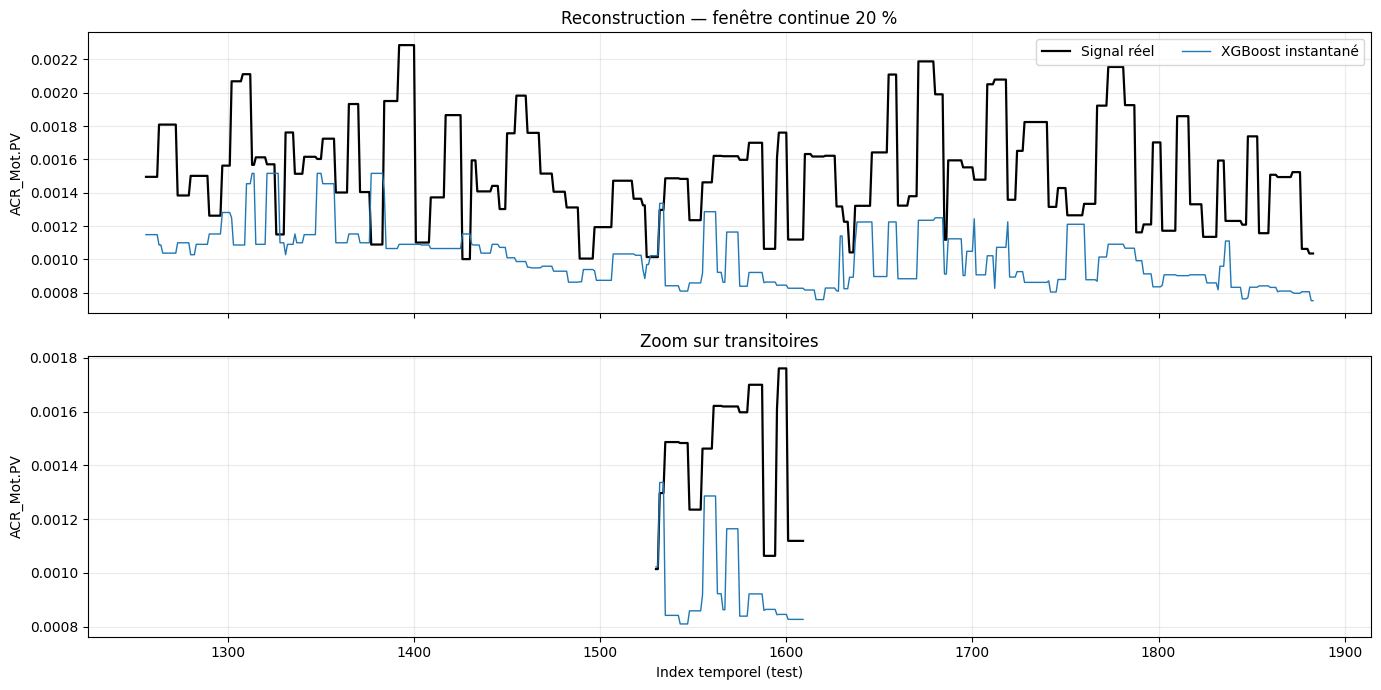

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [31]:
evaluation_rows = [evaluate_model(y_test_physical, prediction, mask, method, scenario) for scenario, mask in scenarios.items() for method, prediction in predictions.items()]
results_all_xgb = pd.DataFrame(evaluation_rows)
main_scenario = "Continuous 20%"; main_mask = scenarios[main_scenario]; idx = np.flatnonzero(main_mask)
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(idx, y_test_physical[main_mask], color="black", lw=1.6, label="Signal réel")
cmp=0
for name, prediction in predictions.items(): 
  
    axes[0].plot(idx, prediction[main_mask], lw=1.0, label=name)
    axes[0].set(title="Reconstruction — fenêtre continue 20 %", ylabel=TARGET_SENSOR); axes[0].legend(ncol=2); axes[0].grid(alpha=.25)
    zoom = slice(max(0, len(idx)//2-40), min(len(idx), len(idx)//2+40)); zoom_idx = idx[zoom]
    axes[1].plot(zoom_idx, y_test_physical[zoom_idx], color="black", lw=1.6, label="Signal réel")
    axes[1].plot(zoom_idx, prediction[zoom_idx], lw=1.0, label=name)
    axes[1].set(title="Zoom sur transitoires", xlabel="Index temporel (test)", ylabel=TARGET_SENSOR); axes[1].grid(alpha=.25)
    plt.tight_layout(); plt.show()


   
    



In [32]:
winner = results_xgb.iloc[3]
print(f"Méthode première selon les résultats exécutés : {winner['Method']}")
print(f"RMSE={winner['RMSE']:.5f}; corrélation={winner['Correlation']:.4f}; std ratio={winner['Std_ratio']:.3f}; amplitude ratio={winner['Amplitude_ratio']:.3f}; peak RMSE={winner['Peak_RMSE']:.5f}")
print("La décision industrielle doit conserver les métriques individuelles : une forte corrélation ne compense pas un ratio de variance ou d'amplitude éloigné de 1.")


Méthode première selon les résultats exécutés : XGBoost contexte + résidu
RMSE=0.00150; corrélation=0.0723; std ratio=0.672; amplitude ratio=0.671; peak RMSE=0.00118
La décision industrielle doit conserver les métriques individuelles : une forte corrélation ne compense pas un ratio de variance ou d'amplitude éloigné de 1.


----------------------------------------------------------------------------------------------------

In [33]:
results_xgb = results_all_xgb.query("Scenario == @main_scenario").copy()
results_xgb["Selection_score"] = (SCORE_WEIGHTS["Normalized_RMSE"] * results_xgb["Normalized_RMSE"] + SCORE_WEIGHTS["Correlation"] * (1 - results_xgb["Correlation"]).abs() + SCORE_WEIGHTS["Std_ratio"] * (1 - results_xgb["Std_ratio"]).abs() + SCORE_WEIGHTS["Amplitude_ratio"] * (1 - results_xgb["Amplitude_ratio"]).abs())
results_xgb = results_xgb.sort_values(["Selection_score", "RMSE"]).reset_index(drop=True)
assert np.isfinite(results_xgb.select_dtypes(include=np.number).to_numpy()).all(), "Métriques non finies"
display(results_xgb[["Method","MAE","RMSE","Normalized_RMSE","R2","Correlation","Variance_ratio","Std_ratio","Amplitude_ratio","Peak_MAE","Peak_RMSE","Peak_detection_rate","Selection_score"]].round(5))
print("Résultats par scénario :"); display(results_all_xgb.sort_values(["Scenario", "RMSE"]).round(5))


,Method,MAE,RMSE,Normalized_RMSE,R2,Correlation,Variance_ratio,Std_ratio,Amplitude_ratio,Peak_MAE,Peak_RMSE,Peak_detection_rate,Selection_score
0,XGBoost contexte,0.00040,0.00050,1.60325,-1.57041,-0.02545,0.14846,0.38531,0.39537,0.00042,0.00072,0.30435,1.09025
1,XGBoost instantané,0.00052,0.00060,1.94055,-2.76572,0.20652,0.30394,0.55131,0.59483,0.00059,0.00084,0.21739,1.10569
2,XGBoost calibration conditionnelle,0.00070,0.00081,2.59536,-5.73590,0.01061,1.12170,1.05910,0.88592,0.00070,0.00055,0.30435,1.27066
3,XGBoost contexte calibré,0.00070,0.00078,2.50380,-5.26901,-0.02545,0.17506,0.41840,0.42934,0.00073,0.00103,0.30435,1.43706
4,XGBoost contexte + résidu,0.00145,0.00150,4.81343,-22.16914,0.07229,0.45100,0.67156,0.67131,0.00137,0.00118,0.39130,2.24234
5,XGBoost niveau–amplitude–forme,0.00128,0.00196,6.28662,-38.52164,0.07354,30.90318,5.55906,3.96856,0.00199,0.00169,0.47826,4.20547


Résultats par scénario :


,Method,Scenario,N_total,N_missing,MAE,RMSE,Normalized_RMSE,R2,Correlation,Variance_ratio,Std_ratio,Amplitude_ratio,Peak_MAE,Peak_RMSE,Peak_amplitude_error,Peak_detection_rate
7,XGBoost contexte,Continuous 10%,3140,314,0.00043,0.00051,1.73666,-2.01599,0.01738,0.15030,0.38768,0.39179,0.00034,0.00072,0.00034,0.36364
10,XGBoost calibration conditionnelle,Continuous 10%,3140,314,0.00049,0.00057,1.93329,-2.73762,-0.03371,0.67945,0.82429,0.92103,0.00065,0.00047,0.00065,0.36364
6,XGBoost instantané,Continuous 10%,3140,314,0.00053,0.00059,2.00352,-3.01409,0.31073,0.22325,0.47249,0.48668,0.00088,0.00082,0.00088,0.09091
8,XGBoost contexte calibré,Continuous 10%,3140,314,0.00075,0.00081,2.73022,-6.45412,0.01738,0.17723,0.42098,0.42545,0.00065,0.00103,0.00065,0.36364
11,XGBoost niveau–amplitude–forme,Continuous 10%,3140,314,0.00070,0.00122,4.12237,-15.99396,-0.05732,14.86387,3.85537,4.29544,0.00021,0.00145,0.00021,0.18182
9,XGBoost contexte + résidu,Continuous 10%,3140,314,0.00141,0.00145,4.88022,-22.81651,0.00716,0.32785,0.57258,0.69045,0.00154,0.00122,0.00154,0.36364
13,XGBoost contexte,Continuous 20%,3140,628,0.00040,0.00050,1.60325,-1.57041,-0.02545,0.14846,0.38531,0.39537,0.00042,0.00072,0.00042,0.30435
12,XGBoost instantané,Continuous 20%,3140,628,0.00052,0.00060,1.94055,-2.76572,0.20652,0.30394,0.55131,0.59483,0.00059,0.00084,0.00059,0.21739
14,XGBoost contexte calibré,Continuous 20%,3140,628,0.00070,0.00078,2.50380,-5.26901,-0.02545,0.17506,0.41840,0.42934,0.00073,0.00103,0.00073,0.30435
16,XGBoost calibration conditionnelle,Continuous 20%,3140,628,0.00070,0.00081,2.59536,-5.73590,0.01061,1.12170,1.05910,0.88592,0.00070,0.00055,0.00070,0.30435


## 11. Conclusion

Exécutez les cellules dans l'ordre avant d'interpréter ce bloc. La méthode retenue est celle ayant le plus faible `Selection_score`, sous réserve que ses ratios d'écart-type et d'amplitude restent proches de 1 et que les métriques de pics soient acceptables pour l'usage industriel.


In [34]:
winner = results_xgb.iloc[0]
print(f"Méthode première selon les résultats exécutés : {winner['Method']}")
print(f"RMSE={winner['RMSE']:.5f}; corrélation={winner['Correlation']:.4f}; std ratio={winner['Std_ratio']:.3f}; amplitude ratio={winner['Amplitude_ratio']:.3f}; peak RMSE={winner['Peak_RMSE']:.5f}")
print("La décision industrielle doit conserver les métriques individuelles : une forte corrélation ne compense pas un ratio de variance ou d'amplitude éloigné de 1.")


Méthode première selon les résultats exécutés : XGBoost contexte
RMSE=0.00050; corrélation=-0.0254; std ratio=0.385; amplitude ratio=0.395; peak RMSE=0.00072
La décision industrielle doit conserver les métriques individuelles : une forte corrélation ne compense pas un ratio de variance ou d'amplitude éloigné de 1.


## Conclusion de recherche — à lire avec le tableau affiché

**Ce qui avance :** les autres capteurs portent assez d'information pour construire des prédictions et comparer des approches non linéaires. Les variantes temporelles testent l'idée que la vibration se propage dans le temps et entre les capteurs.

**Résultat à ne pas surinterpréter :** si le R² est faible, la corrélation faible, ou si les ratios de variance/amplitude sont loin de 1, le modèle ne reproduit pas encore correctement l'intensité du signal. Une amélioration de RMSE ou de variance seule ne suffit pas.

**Pourquoi l'amplitude reste difficile :** les entrées actuelles décrivent des corrélations, mais pas forcément l'atténuation physique : distance, matière, fixation, direction, régime de la machine et réponse fréquentielle du capteur. Des signaux semblables peuvent donc avoir des hauteurs différentes.

**Suite recommandée :** faire une étude dédiée des amplitudes et des pics, par régime de fonctionnement et par bande de fréquence. Ensuite, tester un modèle avec un gain d'amplitude explicite ou des variables physiques supplémentaires. Cette étape est la suite logique de l'étude, pas une conclusion déjà prouvée.
